In [1]:
import yfinance as yf
import pandas as pd
import numpy as np
import warnings
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
from scipy.stats import norm, chi2, skew, kurtosis, kstest,ks_2samp, ttest_ind,spearmanr
import shap
from scipy.optimize import minimize
import statsmodels.api as sm
import statsmodels.formula.api as smf
from arch import arch_model
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_white, acorr_ljungbox, het_arch
from sklearn.metrics import (
    accuracy_score, 
    precision_score, 
    recall_score, 
    roc_auc_score, 
    confusion_matrix
)
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
%matplotlib inline
import logging
logging.getLogger("tqdm").setLevel(logging.ERROR)
import xlsxwriter

C:\Users\PC\anaconda3\envs\research_env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Data Acquisition

In [2]:
start_date= "2000-01-01"
end_date= "2025-10-30"
sp = yf.download("^GSPC", start=start_date, end=end_date)['Close']
sp_ret = np.log(sp).diff().dropna()
tickers = ["^VIX", "SPY", "TLT", "HYG"]
data = yf.download(tickers, start=start_date, end=end_date)["Close"].ffill()

factors = pd.DataFrame({
    "IV": data["^VIX"] / 100,
    "VoV": (data["^VIX"] / 100).rolling(21).std(),
    "Credit_Spread": (data["HYG"] / data["TLT"]) - 1,
    "Yield_Curve": data["TLT"] / data["SPY"],
    "Realized_Vol": data["SPY"].pct_change().rolling(21).std() * np.sqrt(252)
}).dropna()

alphas = [0.005, 0.003,0.01]
forecast_horizon= 5 #days
window = 5 # years

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  4 of 4 completed


## 1.1. Analysis of Volatility Clustering via Autocorrelation

<Figure size 800x500 with 0 Axes>

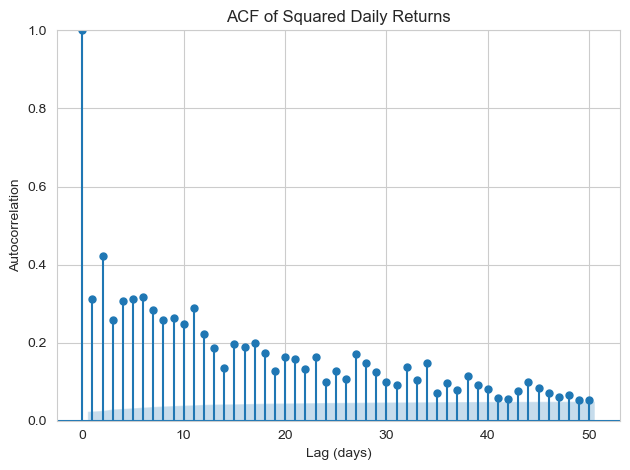

In [3]:
rets = sp_ret.dropna()
abs_ret = np.abs(rets)
sq_ret  = rets**2

plt.figure(figsize=(8, 5))
plot_acf(sq_ret, lags=50)
plt.title("ACF of Squared Daily Returns")
plt.xlabel("Lag (days)")
plt.ylabel("Autocorrelation")
plt.ylim(0, 1) 
plt.tight_layout()
plt.show()

# 2. Modelling
## 2.1 GARCH MODEL SELECTION

In [4]:
def fit_garch_model(returns, vol='Garch', p=1, q=1, dist='normal'):
    try:
        model = arch_model(returns, vol=vol, p=p, q=q, dist=dist)
        res = model.fit(disp='off')
        return res
    except:
        return None

def garch_model_selection(returns):
    results = []
    
    specs = [
        ('Garch', 1, 1), ('Garch', 1, 2), ('Garch', 2, 1), ('Garch', 2, 2),
        ('GJR-GARCH', 1, 1), ('EGARCH', 1, 1)
    ]
    
    distributions = ['normal', 't', 'skewt']
    
    for vol, p, q in specs:
        for dist in distributions:
            res = fit_garch_model(returns, vol, p, q, dist)
            if res is None:
                continue
            
            resid = res.std_resid.dropna()
            
            lb_pvalue = acorr_ljungbox(resid, lags=[10], return_df=True)['lb_pvalue'].iloc[0]
            arch_pvalue = het_arch(resid)[1]
            
            if dist == 'normal':
                ks_pvalue = kstest(resid, 'norm')[1]
            else:
                ks_pvalue = kstest(resid, 't', args=(res.params['nu'],))[1] if 'nu' in res.params else np.nan
            
            results.append({
                'Model': f'{vol}({p},{q})',
                'Distribution': dist,
                'AIC': res.aic,
                'BIC': res.bic,
                'LogLik': res.loglikelihood,
                'LB_pvalue': lb_pvalue,
                'ARCH_pvalue': arch_pvalue,
                'KS_pvalue': ks_pvalue
            })
    
    return pd.DataFrame(results).sort_values(['BIC','AIC'])


results = garch_model_selection(sp_ret)
results

C:\Users\PC\AppData\Local\Temp\ipykernel_15268\3666611171.py:4: ConvergenceWarning: The optimizer returned code 4. The message is:
Inequality constraints incompatible
See scipy.optimize.fmin_slsqp for code meaning.

  res = model.fit(disp='off')
C:\Users\PC\AppData\Local\Temp\ipykernel_15268\3666611171.py:4: ConvergenceWarning: The optimizer returned code 4. The message is:
Inequality constraints incompatible
See scipy.optimize.fmin_slsqp for code meaning.

  res = model.fit(disp='off')
C:\Users\PC\AppData\Local\Temp\ipykernel_15268\3666611171.py:4: ConvergenceWarning: The optimizer returned code 4. The message is:
Inequality constraints incompatible
See scipy.optimize.fmin_slsqp for code meaning.

  res = model.fit(disp='off')
C:\Users\PC\AppData\Local\Temp\ipykernel_15268\3666611171.py:4: ConvergenceWarning: The optimizer returned code 4. The message is:
Inequality constraints incompatible
See scipy.optimize.fmin_slsqp for code meaning.

  res = model.fit(disp='off')
C:\Users\PC\AppD

,Model,Distribution,AIC,BIC,LogLik,LB_pvalue,ARCH_pvalue,KS_pvalue
12,"EGARCH(1,1)",normal,-4.186292e+04,-4.183580e+04,2.093546e+04,1.754836e-02,4.308320e-03,7.930633e-10
7,"Garch(2,1)",t,-3.904422e+04,-3.900354e+04,1.952811e+04,1.551334e-07,5.062262e-234,0.000000e+00
9,"Garch(2,2)",normal,-3.367702e+04,-3.363635e+04,1.684451e+04,4.313708e-08,1.080273e-16,0.000000e+00
6,"Garch(2,1)",normal,-3.169473e+04,-3.166084e+04,1.585237e+04,1.030149e-10,2.668568e-28,0.000000e+00
3,"Garch(1,2)",normal,2.349444e+04,2.352833e+04,-1.174222e+04,9.778798e-01,1.188148e-110,0.000000e+00
8,"Garch(2,1)",skewt,2.698100e+04,2.702845e+04,-1.348350e+04,9.774752e-01,0.000000e+00,NaN
13,"EGARCH(1,1)",t,7.153387e+04,7.156776e+04,-3.576194e+04,1.000000e+00,0.000000e+00,0.000000e+00
14,"EGARCH(1,1)",skewt,8.486259e+04,8.490326e+04,-4.242530e+04,9.995873e-01,1.000000e+00,NaN
1,"Garch(1,1)",t,1.397101e+05,1.397440e+05,-6.985006e+04,9.687236e-08,0.000000e+00,0.000000e+00
0,"Garch(1,1)",normal,1.519729e+05,1.520000e+05,-7.598247e+04,9.999927e-01,0.000000e+00,0.000000e+00


## 2.2. Model Budiling

In [5]:
def rolling_var_monthly(returns, alphas, rolling_window, forecast_horizons,
                        start_date, end_date, regime_name):

    returns = returns.sort_index()
    idx = returns.index
    start_date = pd.to_datetime(start_date)
    end_date   = pd.to_datetime(end_date)

    out = []

    for i in range(rolling_window - 1, len(idx) - max(forecast_horizons)):

        window_end   = idx[i]
        window_start = idx[i - rolling_window + 1]
        r_win = returns.iloc[i - rolling_window + 1: i + 1]

        if len(r_win) < 200:
            continue

        # --- GARCH(2,2) ---
        am = arch_model(r_win * 100, p=2, q=2, vol="GARCH",
                        dist="normal", o=0, rescale=False)
        res = am.fit(disp="off")

        std_resid = res.resid / res.conditional_volatility

        for h in forecast_horizons:

            if i + h >= len(idx):
                continue

            var_date = idx[i + h]

            if not (start_date <= var_date <= end_date):
                continue

            fcast = res.forecast(horizon=h, reindex=False)
            mu_h  = fcast.mean.values[-1, h - 1] / 100
            sig_h = np.sqrt(fcast.variance.values[-1, h - 1]) / 100
            actual = float(returns.loc[var_date].iloc[0] if isinstance(returns.loc[var_date], pd.Series) else returns.loc[var_date])

            for a in alphas:

                # FHS VaR
                q_alpha = np.quantile(std_resid, a)
                var_fhs = mu_h + sig_h * q_alpha

                # Cantelli VaR
                k = np.sqrt((1 - a) / a)
                var_cant = mu_h - k * sig_h

                model_name = f"{regime_name}_{a}_{h}"

                out.append({
                    "ModelName": model_name,
                    "Alpha": a,
                    "ForecastHorizon": h,
                    "VaR_Estimation_Date": var_date,
                    "RollingStart": window_start,
                    "RollingEnd": window_end,
                    "Mu": mu_h,
                    "Sigma": sig_h,
                    "FHS_VaR": var_fhs,
                    "Cantelli_VaR": var_cant,
                    "ActualReturn": actual,
                    "VaR_Ratio": var_fhs/var_cant,
                    "Breach_FHS": int(actual < var_fhs),
                    "Breach_Cantelli": int(actual < var_cant),
                    "Regime": regime_name
                })

    df = pd.DataFrame(out)
    df.sort_values(["VaR_Estimation_Date", "ForecastHorizon", "Alpha"], inplace=True)
    df.reset_index(drop=True, inplace=True)
    return df

alphas = [0.05, 0.03, 0.01]
rolling_window = 252 * 5
forecast_horizons = [1, 5, 10, 21] 

In [6]:
df_full = rolling_var_monthly(sp_ret, alphas, rolling_window, forecast_horizons,
                              "2007-10-01", "2025-10-30", "FullSample")

df_crisis = rolling_var_monthly(sp_ret, alphas, rolling_window, forecast_horizons,
                                "2008-01-01", "2009-12-31", "Crisis")

df_covid  = rolling_var_monthly(sp_ret, alphas, rolling_window, forecast_horizons,
                                "2020-01-01", "2020-12-31", "COVID")

df_infl   = rolling_var_monthly(sp_ret, alphas, rolling_window, forecast_horizons,
                                "2022-01-01", "2022-12-31", "Inflation")

## 3 Test Execution

## 3.1 VAR Back Testing

In [7]:
def var_backtest(df: pd.DataFrame) -> pd.DataFrame:
    
    out = []

    for (alpha, h), sub in df.groupby(["Alpha", "ForecastHorizon"]):

        r  = sub["ActualReturn"].astype(float).values
        vg = sub["FHS_VaR"].astype(float).values
        vc = sub["Cantelli_VaR"].astype(float).values

        n = len(r)
        if n == 0:
            continue

        # Breaches
        v = (r < vg).astype(int)
        g_breach = v.sum()
        exp_breach = round(n * alpha)          

        # VaR ratio
        mean_ratio = np.nanmean(vg / vc)

        # ---------- Kupiec UC Test ----------
        if g_breach in (0, n):
            uc_p = 1.0
        else:
            pi_hat = g_breach / n
            logL0  = g_breach*np.log(alpha) + (n-g_breach)*np.log(1-alpha)
            logL1  = g_breach*np.log(pi_hat) + (n-g_breach)*np.log(1-pi_hat)
            lr_uc = -2*(logL0 - logL1)
            uc_p  = 1 - chi2.cdf(lr_uc, 1)

        UC_pass = (uc_p > alpha)               

        # ---------- Christoffersen IND Test ----------
        n00 = n01 = n10 = n11 = 0
        for i in range(1, n):
            a, b = v[i-1], v[i]
            if a==0 and b==0: n00 += 1
            if a==0 and b==1: n01 += 1
            if a==1 and b==0: n10 += 1
            if a==1 and b==1: n11 += 1

        n0 = n00 + n01
        n1 = n10 + n11

        if n0 == 0 or n1 == 0:
            ind_p = 1.0
        else:
            p01 = n01 / n0 if n0 > 0 else 0
            p11 = n11 / n1 if n1 > 0 else 0
            p1  = (n01 + n11) / (n0 + n1)
            if p01 in (0,1) or p11 in (0,1) or p1 in (0,1):
                ind_p = 1.0
            else:
                logL1 = n00*np.log(1-p01) + n01*np.log(p01) + \
                        n10*np.log(1-p11) + n11*np.log(p11)
                logL0 = (n00+n10)*np.log(1-p1) + (n01+n11)*np.log(p1)
                lr_ind = -2*(logL0 - logL1)
                ind_p = 1 - chi2.cdf(lr_ind, 1)

        IND_pass = (ind_p > alpha)             

        
        breach_rate_pct = f"{(g_breach/n)*100:.2f}%"

        
        out.append({
            "Alpha": alpha,
            "ForecastHorizon": h,
            "Obs": n,
            "ExpB": exp_breach,
            "ActB": g_breach,
            "Breach_Rate": breach_rate_pct,
            "Mean_Ratio": mean_ratio,
            "UC_p": uc_p,
            "UC_pass": UC_pass,
            "IND_p": ind_p,
            "IND_pass": IND_pass
        })

    return pd.DataFrame(out)


    return pd.DataFrame(out)


stats_full   = var_backtest(df_full)
stats_crisis = var_backtest(df_crisis)
stats_covid  = var_backtest(df_covid)
stats_infl   = var_backtest(df_infl)

with pd.ExcelWriter("FHS_var.xlsx", engine="xlsxwriter") as writer:
    stats_full.to_excel(writer, sheet_name="FullSample", index=False)
    stats_crisis.to_excel(writer, sheet_name="Crisis", index=False)
    stats_covid.to_excel(writer, sheet_name="COVID", index=False)
    stats_infl.to_excel(writer, sheet_name="Inflation", index=False)


In [8]:
stats_full

,Alpha,ForecastHorizon,Obs,ExpB,ActB,Breach_Rate,Mean_Ratio,UC_p,UC_pass,IND_p,IND_pass
0,0.01,1,4530,45,59,1.30%,0.279204,0.050612,True,0.048797,True
1,0.01,5,4534,45,67,1.48%,0.279591,0.002539,False,0.000005,False
2,0.01,10,4539,45,68,1.50%,0.279873,0.001682,False,0.000059,False
3,0.01,21,4550,46,67,1.47%,0.280162,0.002762,False,0.000048,False
4,0.03,1,4530,136,137,3.02%,0.376324,0.923773,True,0.674042,True
5,0.03,5,4534,136,137,3.02%,0.376932,0.932088,True,0.031570,True
6,0.03,10,4539,136,150,3.30%,0.377375,0.236248,True,0.005121,False
7,0.03,21,4550,136,140,3.08%,0.377851,0.761948,True,0.001480,False
8,0.05,1,4530,226,230,5.08%,0.402423,0.811864,True,0.921808,True
9,0.05,5,4534,227,215,4.74%,0.403199,0.421455,True,0.234351,True


In [9]:
stats_crisis

,Alpha,ForecastHorizon,Obs,ExpB,ActB,Breach_Rate,Mean_Ratio,UC_p,UC_pass,IND_p,IND_pass
0,0.01,1,505,5,10,1.98%,0.256091,0.050853,True,1.000000,True
1,0.01,5,505,5,12,2.38%,0.256032,0.008291,False,1.000000,True
2,0.01,10,505,5,15,2.97%,0.255965,0.000318,False,1.000000,True
3,0.01,21,505,5,15,2.97%,0.255813,0.000318,False,0.458681,True
4,0.03,1,505,15,22,4.36%,0.363999,0.093673,True,1.000000,True
5,0.03,5,505,15,26,5.15%,0.363918,0.010044,False,1.000000,True
6,0.03,10,505,15,29,5.74%,0.363780,0.001292,False,1.000000,True
7,0.03,21,505,15,29,5.74%,0.363427,0.001292,False,0.555974,True
8,0.05,1,505,25,37,7.33%,0.399759,0.024414,False,1.000000,True
9,0.05,5,505,25,41,8.12%,0.399469,0.003059,False,1.000000,True


In [10]:
stats_covid

,Alpha,ForecastHorizon,Obs,ExpB,ActB,Breach_Rate,Mean_Ratio,UC_p,UC_pass,IND_p,IND_pass
0,0.01,1,253,3,4,1.58%,0.311841,0.391833,True,1.000000,True
1,0.01,5,253,3,8,3.16%,0.312165,0.005837,False,0.236735,True
2,0.01,10,253,3,13,5.14%,0.312386,0.000003,False,0.155513,True
3,0.01,21,253,3,13,5.14%,0.312550,0.000003,False,0.021381,True
4,0.03,1,253,8,12,4.74%,0.368248,0.133310,True,1.000000,True
5,0.03,5,253,8,12,4.74%,0.368935,0.133310,True,0.586753,True
6,0.03,10,253,8,18,7.11%,0.369474,0.001062,False,0.031627,True
7,0.03,21,253,8,21,8.30%,0.370258,0.000044,False,0.340828,True
8,0.05,1,253,13,19,7.51%,0.392433,0.087111,True,0.625344,True
9,0.05,5,253,13,14,5.53%,0.393283,0.701612,True,0.797379,True


In [11]:
stats_infl

,Alpha,ForecastHorizon,Obs,ExpB,ActB,Breach_Rate,Mean_Ratio,UC_p,UC_pass,IND_p,IND_pass
0,0.01,1,251,3,1,0.40%,0.308097,0.275614,True,1.000000,True
1,0.01,5,251,3,2,0.80%,0.308639,0.737311,True,1.000000,True
2,0.01,10,251,3,0,0.00%,0.309299,1.000000,True,1.000000,True
3,0.01,21,251,3,2,0.80%,0.310660,0.737311,True,1.000000,True
4,0.03,1,251,8,8,3.19%,0.381733,0.863282,True,1.000000,True
5,0.03,5,251,8,6,2.39%,0.381960,0.557548,True,1.000000,True
6,0.03,10,251,8,7,2.79%,0.382201,0.842728,True,1.000000,True
7,0.03,21,251,8,7,2.79%,0.382649,0.842728,True,1.000000,True
8,0.05,1,251,13,18,7.17%,0.402149,0.137211,True,0.532325,True
9,0.05,5,251,13,17,6.77%,0.402323,0.220315,True,0.873764,True


## 3.2. Horizon Effect Test: Rolling VER

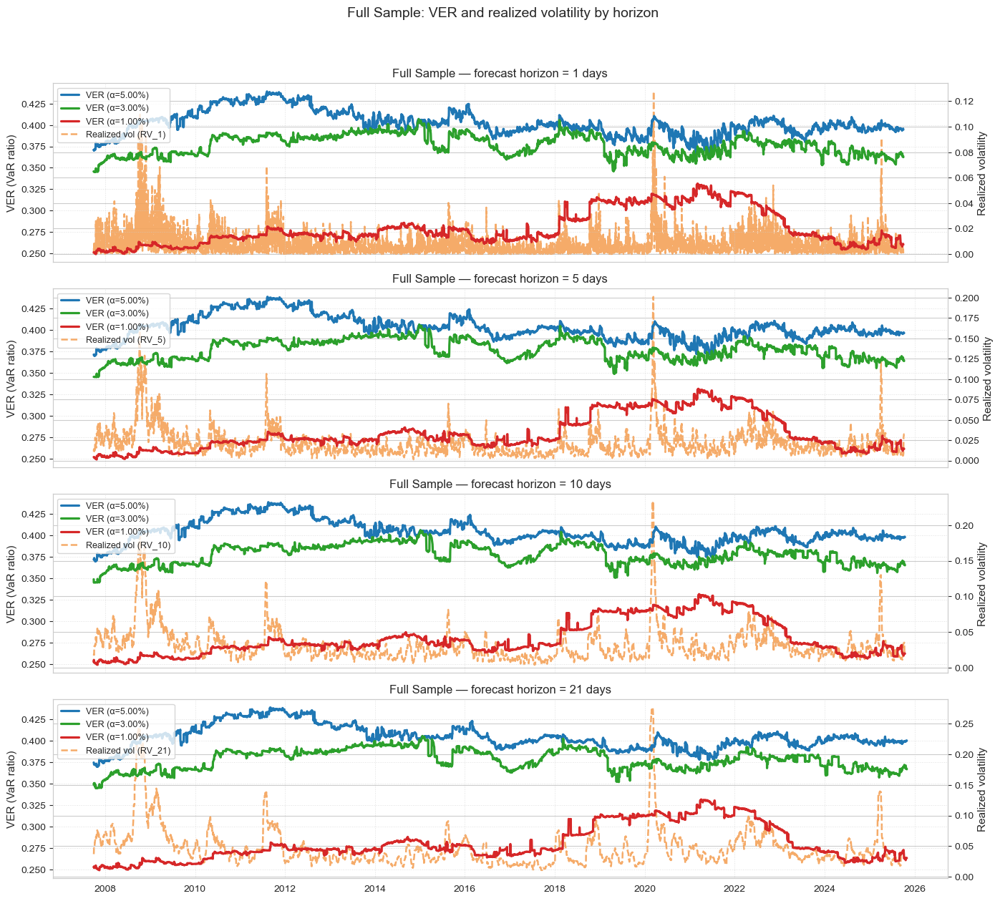

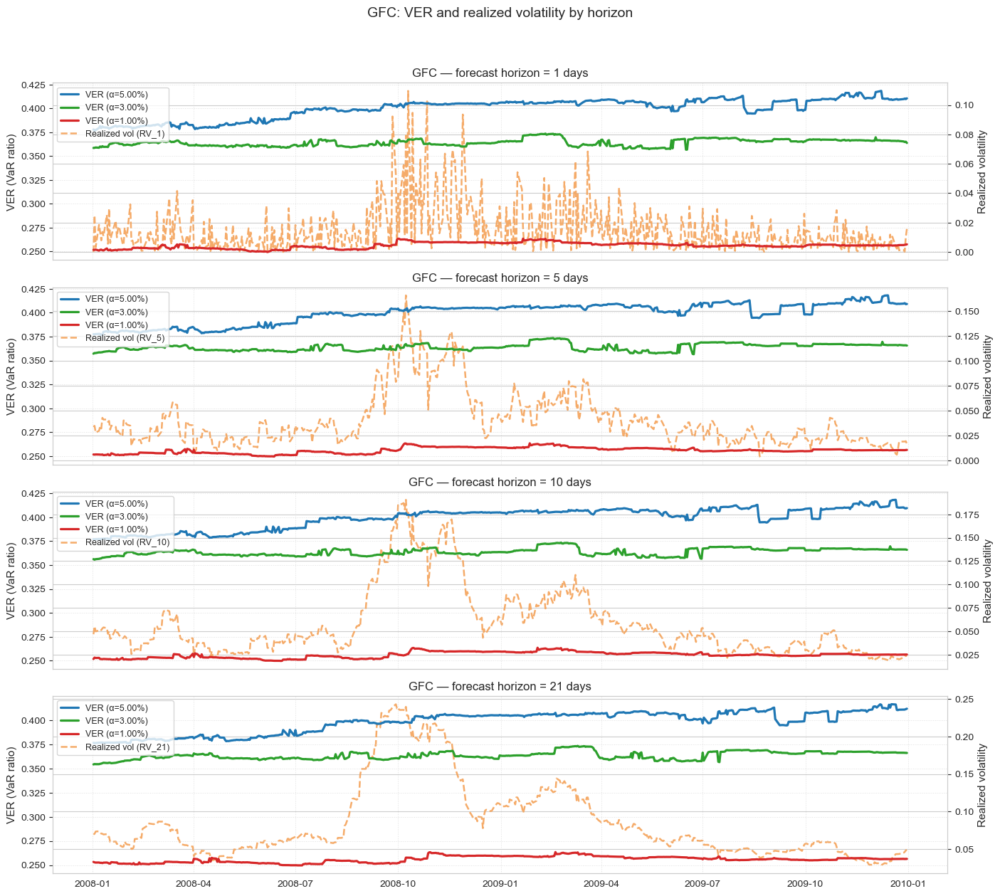

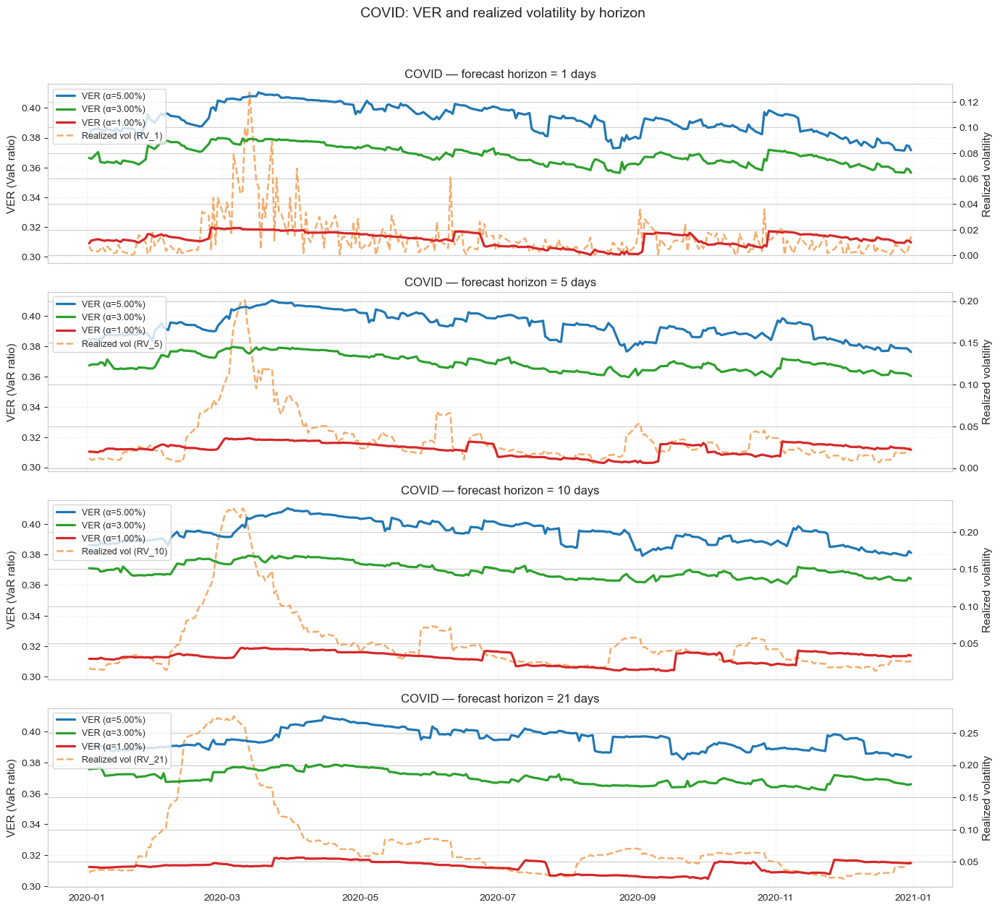

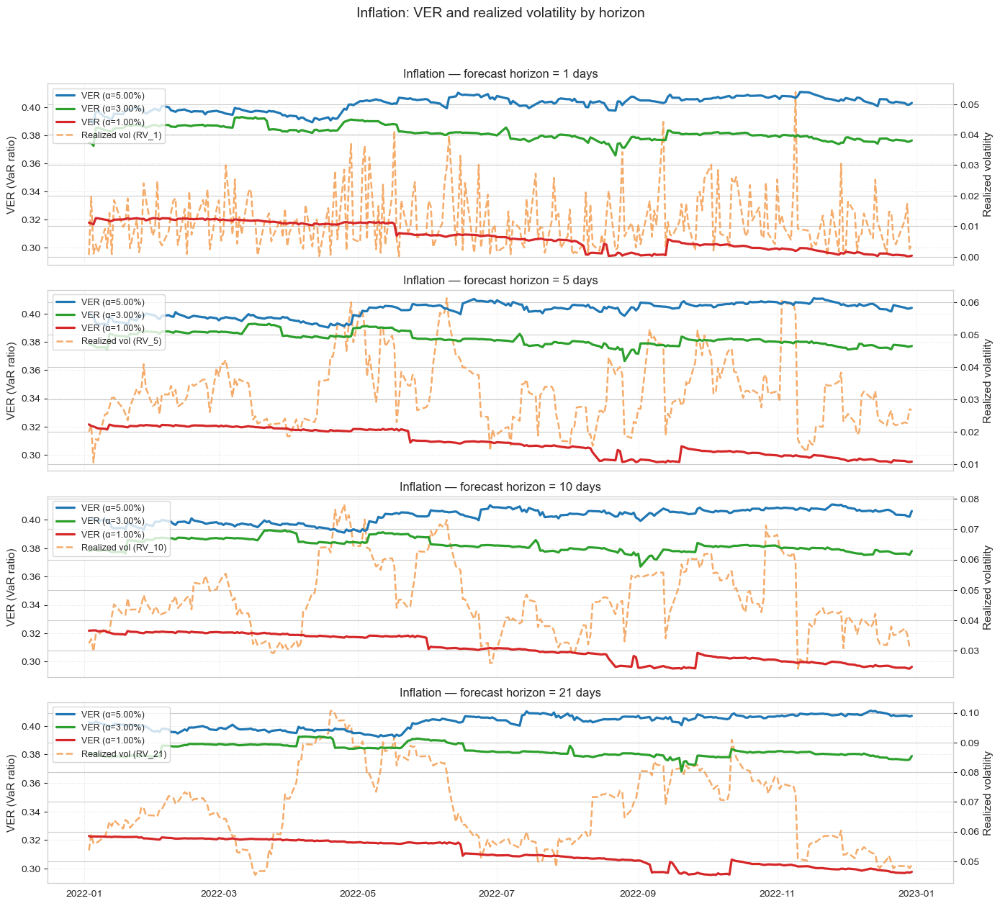

In [12]:
def compute_realized_vol(returns, horizons):
    rv = {}
    r = returns.values
    idx = returns.index

    for h in horizons:
        arr = np.full(len(r), np.nan)
        for i in range(len(r) - h):
            # forward h-day realised vol
            arr[i] = np.sqrt(np.sum(r[i+1:i+h+1] ** 2))
        rv[h] = pd.Series(arr, index=idx, name=f"RV_{h}")

    return rv


def plot_scope_single_figure(df, rv_dict, alphas, horizons, name):
    
    alpha_colors = {
        0.05: "tab:blue",
        0.03: "tab:green",
        0.01: "tab:red"
    }

    fig, axes = plt.subplots(
        len(horizons), 1,
        figsize=(14, 3.2 * len(horizons)),
        sharex=True
    )

    if len(horizons) == 1:
        axes = [axes]

    for j, h in enumerate(horizons):
        ax = axes[j]          
        ax2 = ax.twinx()      

        rv_series = rv_dict[h]

        
        df_h = df[df["ForecastHorizon"] == h].copy()
        if df_h.empty:
            continue

        
        all_dates = pd.to_datetime(df_h["VaR_Estimation_Date"].unique())
        all_dates = pd.Index(all_dates).sort_values()        
        rv_aligned = rv_series.reindex(all_dates)

        handles_left = []
        labels_left = []
        
        for a in alphas:
            sub = df_h[df_h["Alpha"] == a].copy()
            if sub.empty:
                continue

            sub = sub.set_index("VaR_Estimation_Date")
            sub.index = pd.to_datetime(sub.index)

            merged = sub.reindex(all_dates)

            line_vr, = ax.plot(
                merged.index,
                merged["VaR_Ratio"],
                lw=2.3,
                color=alpha_colors.get(a, "tab:gray"),
                label=f"VER (α={a:.2%})"
            )
            handles_left.append(line_vr)
            labels_left.append(f"VER (α={a:.2%})")

        
        line_rv, = ax2.plot(
            rv_aligned.index,
            rv_aligned.values,
            ls="--",
            lw=1.8,
            color="#f4a259",       
            alpha=0.9,
            label=f"Realized vol (RV_{h})"
        )

        
        ax.set_zorder(ax2.get_zorder() + 1)
        ax.patch.set_visible(False)

        
        ax.set_title(f"{name} — forecast horizon = {h} days", fontsize=12)
        ax.set_ylabel("VER (VaR ratio)", fontsize=11)
        ax2.set_ylabel("Realized volatility", fontsize=11)
        ax.grid(True, linestyle=":", linewidth=0.7, alpha=0.6)

        
        handles = handles_left + [line_rv]
        labels = labels_left + [f"Realized vol (RV_{h})"]
        if handles:
            ax.legend(handles, labels, loc="upper left", fontsize=9)

    fig.suptitle(f"{name}: VER and realized volatility by horizon", fontsize=14)
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()


alphas=[0.05,0.03,0.01]
horizons=[1,5,10,21]
rolling_window=252*5
rv_dict=compute_realized_vol(sp_ret,horizons)

plot_scope_single_figure(df_full, rv_dict, alphas, horizons, "Full Sample")
plot_scope_single_figure(df_crisis, rv_dict, alphas, horizons, "GFC")
plot_scope_single_figure(df_covid, rv_dict, alphas, horizons, "COVID")
plot_scope_single_figure(df_infl, rv_dict, alphas, horizons, "Inflation")


## 3.3 Horizon Effect Test: Panel Regression

In [14]:
def run_ver_panel_regression(df, ratio_col="VaR_Ratio",
                             date_col="VaR_Estimation_Date",
                             alpha_col="Alpha",
                             horizon_col="ForecastHorizon",
                             nw_lags=5):
    df_reg = df.copy()
    df_reg[date_col] = pd.to_datetime(df_reg[date_col])
    df_reg = df_reg.rename(columns={ratio_col: "VER"})
    df_reg = df_reg[[date_col, "VER", alpha_col, horizon_col]].dropna()
    df_reg = df_reg.sort_values(date_col)

    df_reg["Alpha_cat"] = df_reg[alpha_col].astype("category")
    df_reg["Horizon_cat"] = df_reg[horizon_col].astype("category")
    df_reg["Alpha_cat"] = df_reg["Alpha_cat"].cat.reorder_categories([0.05, 0.03, 0.01], ordered=True)
    df_reg["Horizon_cat"] = df_reg["Horizon_cat"].cat.reorder_categories([1, 5, 10, 21], ordered=True)

    df_reg = df_reg.set_index(date_col)

    formula = "VER ~ C(Alpha_cat) + C(Horizon_cat)"
    ols_model = smf.ols(formula=formula, data=df_reg).fit()
    ols_nw = ols_model.get_robustcov_results(cov_type="HAC", maxlags=nw_lags)
    return ols_nw

ols_nw = run_ver_panel_regression(df_covid)
ols_nw.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                    VER   R-squared:                       0.969
Model:                            OLS   Adj. R-squared:                  0.969
Method:                 Least Squares   F-statistic:                 2.570e+04
Date:                Sat, 27 Jun 2026   Prob (F-statistic):               0.00
Time:                        16:56:30   Log-Likelihood:                 11153.
No. Observations:                3036   AIC:                        -2.229e+04
Df Residuals:                    3030   BIC:                        -2.226e+04
Df Model:                           5                                         
Covariance Type:                  HAC                                         
========================================================================================
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept                0.3928      0.000    849.534      0.000       0.392       0.394
C(Alpha_cat)[T.0.03]    -0.0244      0.000    -96.133      0.000      -0.025      -0.024
C(Alpha_cat)[T.0.01]    -0.0814      0.000   -259.709      0.000      -0.082      -0.081
C(Horizon_cat)[T.5]      0.0006      0.000      2.092      0.037    3.89e-05       0.001
C(Horizon_cat)[T.10]     0.0011      0.000      2.597      0.009       0.000       0.002
C(Horizon_cat)[T.21]     0.0017      0.000      4.271      0.000       0.001       0.002
==============================================================================
Omnibus:                        0.078   Durbin-Watson:                   0.876
Prob(Omnibus):                  0.962   Jarque-Bera (JB):                0.114
Skew:                          -0.003   Prob(JB):                        0.945
Kurtosis:                       2.971   Cond. No.                         5.35
==============================================================================

Notes:
[1] Standard Errors are heteroscedasticity and autocorrelation robust (HAC) using 5 lags and without small sample correction
"""

In [15]:
# Joint test: all horizon dummies = 0
hypothesis_horizon = "C(Horizon_cat)[T.5] = 0, C(Horizon_cat)[T.10] = 0, C(Horizon_cat)[T.21] = 0"
print(ols_nw.f_test(hypothesis_horizon))

# Joint test: all alpha dummies = 0
hypothesis_alpha = "C(Alpha_cat)[T.0.03] = 0, C(Alpha_cat)[T.0.01] = 0"
print(ols_nw.f_test(hypothesis_alpha))


<F test: F=6.399461549079896, p=0.00025564844726307985, df_denom=3.03e+03, df_num=3>
<F test: F=60808.68035370158, p=0.0, df_denom=3.03e+03, df_num=2>


## 3.4 Predictive Power: Logit & Probit Model

In [16]:
def run_breach_models_with_newey_west(df, scope_name, max_lags=None):

    results = []

    for (alpha, h), sub in df.groupby(["Alpha", "ForecastHorizon"]):

        sub = sub.dropna(subset=["VaR_Ratio", "Breach_FHS"])
        if sub["Breach_FHS"].nunique() < 2:
            continue

        X = sm.add_constant(sub["VaR_Ratio"])
        y = sub["Breach_FHS"]

        try:
            logit_m = sm.Logit(y, X).fit(cov_type='HAC', 
                                         cov_kwds={'maxlags': max_lags},
                                         disp=False)
            probit_m = sm.Probit(y, X).fit(cov_type='HAC', 
                                           cov_kwds={'maxlags': max_lags},
                                           disp=False)

            logit_p = logit_m.predict(X)
            probit_p = probit_m.predict(X)

            auc_logit = roc_auc_score(y, logit_p)
            auc_probit = roc_auc_score(y, probit_p)

            results.append({
                "Scope": scope_name,
                "Alpha": alpha,
                "ForecastHorizon": h,
                "Obs": len(sub),

                "Logit_Beta_Ratio": logit_m.params["VaR_Ratio"],
                "Logit_p_NeweyWest": logit_m.pvalues["VaR_Ratio"],
                "Logit_StdErr_NeweyWest": logit_m.bse["VaR_Ratio"],
                "AUC_Logit": auc_logit,
                "AR_Logit": 2*auc_logit - 1,

                "Probit_Beta_Ratio": probit_m.params["VaR_Ratio"],
                "Probit_p_NeweyWest": probit_m.pvalues["VaR_Ratio"],
                "Probit_StdErr_NeweyWest": probit_m.bse["VaR_Ratio"],
                "AUC_Probit": auc_probit,
                "AR_Probit": 2*auc_probit - 1,

                "Max_Lags": max_lags,
                "Cov_Type": "HAC"
            })

        except:
            continue

    return pd.DataFrame(results)


def run_robustness_analysis(df, scope_name):
    lag_specs = [None, 5, 10, 22]
    out = []
    for L in lag_specs:
        r = run_breach_models_with_newey_west(df, scope_name, max_lags=L)
        if not r.empty:
            out.append(r)
    return pd.concat(out, ignore_index=True) if out else pd.DataFrame()

res_full_nw  = run_breach_models_with_newey_west(df_full,  "FullSample", max_lags=10)
res_crisis_nw = run_breach_models_with_newey_west(df_crisis, "Crisis", max_lags=5)
res_covid_nw  = run_breach_models_with_newey_west(df_covid,  "COVID", max_lags=5)
res_infl_nw   = run_breach_models_with_newey_west(df_infl,   "Inflation", max_lags=5)

final_nw = pd.concat([res_full_nw, res_crisis_nw, res_covid_nw, res_infl_nw], ignore_index=True)

final_nw[
    ["Scope","Alpha","ForecastHorizon",
     "Logit_Beta_Ratio","Logit_p_NeweyWest","AUC_Logit",
     "Probit_Beta_Ratio","Probit_p_NeweyWest","AUC_Probit"]
].round(6)
final_nw

,Scope,Alpha,ForecastHorizon,Obs,Logit_Beta_Ratio,Logit_p_NeweyWest,Logit_StdErr_NeweyWest,AUC_Logit,AR_Logit,Probit_Beta_Ratio,Probit_p_NeweyWest,Probit_StdErr_NeweyWest,AUC_Probit,AR_Probit,Max_Lags,Cov_Type
0,FullSample,0.01,1,4530,-17.254503,0.044102,8.571007,0.618623,0.237246,-6.260232,0.036837,2.998817,0.618623,0.237246,10,HAC
1,FullSample,0.01,5,4534,-9.316181,0.268842,8.425335,0.577702,0.155405,-3.503253,0.259470,3.106702,0.577702,0.155405,10,HAC
2,FullSample,0.01,10,4539,-11.037599,0.395371,12.986671,0.601964,0.203929,-3.999519,0.382643,4.581155,0.601964,0.203929,10,HAC
3,FullSample,0.01,21,4550,-7.413591,0.566013,12.917164,0.586005,0.172010,-2.674585,0.557892,4.564332,0.586005,0.172010,10,HAC
4,FullSample,0.03,1,4530,-28.629149,0.000333,7.979117,0.593064,0.186127,-12.111822,0.000339,3.380188,0.593064,0.186127,10,HAC
5,FullSample,0.03,5,4534,-30.928362,0.000629,9.047077,0.601928,0.203857,-13.032977,0.000664,3.828530,0.601928,0.203857,10,HAC
6,FullSample,0.03,10,4539,-30.165167,0.000484,8.644493,0.600480,0.200960,-12.887416,0.000509,3.707555,0.600480,0.200960,10,HAC
7,FullSample,0.03,21,4550,-37.650658,0.000100,9.677177,0.620896,0.241791,-15.883728,0.000122,4.135237,0.620896,0.241791,10,HAC
8,FullSample,0.05,1,4530,-15.218949,0.003581,5.224618,0.562992,0.125984,-6.877393,0.003735,2.371714,0.562992,0.125984,10,HAC
9,FullSample,0.05,5,4534,-18.564717,0.002207,6.065298,0.570208,0.140417,-8.386655,0.002366,2.758773,0.570208,0.140417,10,HAC


## 3.4.1 Logistic Regression Controlling for Sigma

In [44]:
def run_breach_models_with_sigma_control(
    df,
    scope_name,
    sigma_col="Sigma",
    max_lags=None,
    use_log_sigma=True
):

    results = []

    control_col = "Log_Sigma" if use_log_sigma else sigma_col

    df = df.copy()

    if use_log_sigma:
        df["Log_Sigma"] = np.log(df[sigma_col])

    for (alpha, h), sub in df.groupby(["Alpha", "ForecastHorizon"]):

        sub = sub.dropna(subset=["VaR_Ratio", "Breach_FHS", control_col])

        if sub["Breach_FHS"].nunique() < 2:
            continue

        X = sm.add_constant(sub[["VaR_Ratio", control_col]])
        y = sub["Breach_FHS"]

        try:
            logit_m = sm.Logit(y, X).fit(
                cov_type="HAC",
                cov_kwds={"maxlags": max_lags},
                disp=False
            )

            probit_m = sm.Probit(y, X).fit(
                cov_type="HAC",
                cov_kwds={"maxlags": max_lags},
                disp=False
            )

            logit_p = logit_m.predict(X)
            probit_p = probit_m.predict(X)

            auc_logit = roc_auc_score(y, logit_p)
            auc_probit = roc_auc_score(y, probit_p)

            results.append({
                "Scope": scope_name,
                "Alpha": alpha,
                "ForecastHorizon": h,
                "Obs": len(sub),

                "Logit_Beta_Ratio": logit_m.params["VaR_Ratio"],
                "Logit_p_Ratio_NeweyWest": logit_m.pvalues["VaR_Ratio"],
                "Logit_StdErr_Ratio_NeweyWest": logit_m.bse["VaR_Ratio"],

                "Logit_Beta_Sigma": logit_m.params[control_col],
                "Logit_p_Sigma_NeweyWest": logit_m.pvalues[control_col],
                "Logit_StdErr_Sigma_NeweyWest": logit_m.bse[control_col],

                "AUC_Logit": auc_logit,
                "AR_Logit": 2 * auc_logit - 1,

                "Probit_Beta_Ratio": probit_m.params["VaR_Ratio"],
                "Probit_p_Ratio_NeweyWest": probit_m.pvalues["VaR_Ratio"],
                "Probit_StdErr_Ratio_NeweyWest": probit_m.bse["VaR_Ratio"],

                "Probit_Beta_Sigma": probit_m.params[control_col],
                "Probit_p_Sigma_NeweyWest": probit_m.pvalues[control_col],
                "Probit_StdErr_Sigma_NeweyWest": probit_m.bse[control_col],

                "AUC_Probit": auc_probit,
                "AR_Probit": 2 * auc_probit - 1,

                "Sigma_Control": control_col,
                "Max_Lags": max_lags,
                "Cov_Type": "HAC"
            })

        except Exception as e:
            print(f"Skipped Alpha={alpha}, Horizon={h}, Scope={scope_name}: {e}")
            continue

    return pd.DataFrame(results)

In [45]:
res_full_sigma = run_breach_models_with_sigma_control(df_full,scope_name="FullSample",sigma_col="Sigma",max_lags=10,use_log_sigma=True)


res_crisis_sigma = run_breach_models_with_sigma_control(df_crisis,scope_name="Crisis",sigma_col="Sigma",max_lags=5,use_log_sigma=True)


res_covid_sigma = run_breach_models_with_sigma_control(df_covid,scope_name="COVID",sigma_col="Sigma",max_lags=5,use_log_sigma=True)

res_infl_sigma = run_breach_models_with_sigma_control(df_infl,scope_name="Inflation",sigma_col="Sigma",max_lags=5,use_log_sigma=True)
sigma_results = pd.concat([res_full_sigma,res_crisis_sigma,res_covid_sigma,res_infl_sigma],ignore_index=True).round(4)
sigma_results

,Scope,Alpha,ForecastHorizon,Obs,Logit_Beta_Ratio,Logit_p_Ratio_NeweyWest,Logit_StdErr_Ratio_NeweyWest,Logit_Beta_Sigma,Logit_p_Sigma_NeweyWest,Logit_StdErr_Sigma_NeweyWest,AUC_Logit,AR_Logit,Probit_Beta_Ratio,Probit_p_Ratio_NeweyWest,Probit_StdErr_Ratio_NeweyWest,Probit_Beta_Sigma,Probit_p_Sigma_NeweyWest,Probit_StdErr_Sigma_NeweyWest,AUC_Probit,AR_Probit,Sigma_Control,Max_Lags,Cov_Type
0,FullSample,0.01,1,4530,-17.8255,0.0507,9.1232,-0.5686,0.0793,0.3241,0.6153,0.2306,-6.4471,0.0401,3.1410,-0.2221,0.0696,0.1224,0.6140,0.2281,Log_Sigma,10,HAC
1,FullSample,0.01,5,4534,-9.7913,0.2799,9.0621,-1.0066,0.0485,0.5102,0.6067,0.2134,-3.7968,0.2461,3.2738,-0.3768,0.0431,0.1863,0.6063,0.2126,Log_Sigma,10,HAC
2,FullSample,0.01,10,4539,-11.4137,0.4090,13.8242,-0.7254,0.2531,0.6348,0.6098,0.2195,-4.0503,0.4011,4.8233,-0.2670,0.2472,0.2307,0.6093,0.2185,Log_Sigma,10,HAC
3,FullSample,0.01,21,4550,-7.5150,0.5928,14.0506,-1.7055,0.0372,0.8185,0.6058,0.2115,-3.0007,0.5330,4.8129,-0.6505,0.0244,0.2891,0.6049,0.2098,Log_Sigma,10,HAC
4,FullSample,0.03,1,4530,-28.5593,0.0004,7.9914,-0.0475,0.7988,0.1862,0.5922,0.1844,-12.0861,0.0004,3.3862,-0.0220,0.7891,0.0822,0.5922,0.1844,Log_Sigma,10,HAC
5,FullSample,0.03,5,4534,-31.3299,0.0005,8.9684,-0.4671,0.1451,0.3205,0.6085,0.2170,-13.3460,0.0004,3.7961,-0.2007,0.1321,0.1333,0.6085,0.2171,Log_Sigma,10,HAC
6,FullSample,0.03,10,4539,-31.0826,0.0003,8.5081,-0.4749,0.1159,0.3021,0.6051,0.2102,-13.3672,0.0003,3.6654,-0.2056,0.1059,0.1272,0.6051,0.2102,Log_Sigma,10,HAC
7,FullSample,0.03,21,4550,-39.4452,0.0000,9.0030,-1.5213,0.0020,0.4925,0.6642,0.3285,-17.4050,0.0000,3.9426,-0.6504,0.0009,0.1964,0.6643,0.3285,Log_Sigma,10,HAC
8,FullSample,0.05,1,4530,-16.1615,0.0027,5.3885,0.0940,0.5713,0.1661,0.5685,0.1370,-7.2938,0.0029,2.4461,0.0428,0.5810,0.0775,0.5685,0.1370,Log_Sigma,10,HAC
9,FullSample,0.05,5,4534,-18.3732,0.0037,6.3342,-0.0274,0.9019,0.2225,0.5697,0.1394,-8.2863,0.0039,2.8720,-0.0150,0.8810,0.1003,0.5697,0.1393,Log_Sigma,10,HAC


## 3.4.2 VER Benchmarking Against Sigma and RV/IV

In [40]:
def get_iv_rv_data(start_date="2000-01-01", end_date="2025-10-30"):
    data = yf.download(
        ["^VIX", "SPY"],
        start=start_date,
        end=end_date,
        progress=False
    )["Close"].ffill()

    factors = pd.DataFrame({
        "IV": data["^VIX"] / 100,
        "Realized_Vol": data["SPY"].pct_change().rolling(21).std() * np.sqrt(252)
    }).dropna()

    factors["Log_RV_IV_Ratio"] = np.log(
        factors["Realized_Vol"] / factors["IV"]
    )

    factors.index = pd.to_datetime(factors.index)

    return factors


def add_sigma_iv_rv_controls(
    df,
    factors,
    sigma_col="Sigma",
    breach_col="Breach_FHS",
    date_col="VaR_Estimation_Date"
):
    df = df.copy()
    factors = factors.copy()

    df[date_col] = pd.to_datetime(df[date_col])
    factors.index = pd.to_datetime(factors.index)

    df = df.merge(
        factors[["IV", "Realized_Vol", "Log_RV_IV_Ratio"]],
        left_on=date_col,
        right_index=True,
        how="left"
    )

    df["Log_Sigma"] = np.log(df[sigma_col])

    df = df.replace([np.inf, -np.inf], np.nan)

    return df


def run_breach_models_with_rv_iv_control(
    df,
    factors,
    scope_name,
    sigma_col="Sigma",
    max_lags=None,
    breach_col="Breach_FHS"
):

    df = add_sigma_iv_rv_controls(
        df=df,
        factors=factors,
        sigma_col=sigma_col,
        breach_col=breach_col
    )

    results = []

    regressors = [
        "VaR_Ratio",
        "Log_Sigma",
        "Log_RV_IV_Ratio"
    ]

    for (alpha, h), sub in df.groupby(["Alpha", "ForecastHorizon"]):

        sub = sub.dropna(subset=regressors + [breach_col])

        if sub[breach_col].nunique() < 2:
            continue

        X = sm.add_constant(sub[regressors], has_constant="add")
        y = sub[breach_col]

        try:
            logit_m = sm.Logit(y, X).fit(
                cov_type="HAC",
                cov_kwds={"maxlags": max_lags},
                disp=False
            )

            probit_m = sm.Probit(y, X).fit(
                cov_type="HAC",
                cov_kwds={"maxlags": max_lags},
                disp=False
            )

            logit_pred = logit_m.predict(X)
            probit_pred = probit_m.predict(X)

            auc_logit = roc_auc_score(y, logit_pred)
            auc_probit = roc_auc_score(y, probit_pred)

            row = {
                "Scope": scope_name,
                "Alpha": alpha,
                "ForecastHorizon": h,
                "Obs": len(sub),

                "AUC_Logit": auc_logit,
                "AR_Logit": 2 * auc_logit - 1,
                "AUC_Probit": auc_probit,
                "AR_Probit": 2 * auc_probit - 1,

                "Max_Lags": max_lags,
                "Cov_Type": "HAC"
            }

            for v in regressors:
                row[f"Logit_Beta_{v}"] = logit_m.params[v]
                row[f"Logit_p_{v}_NeweyWest"] = logit_m.pvalues[v]
                row[f"Logit_SE_{v}_NeweyWest"] = logit_m.bse[v]

                row[f"Probit_Beta_{v}"] = probit_m.params[v]
                row[f"Probit_p_{v}_NeweyWest"] = probit_m.pvalues[v]
                row[f"Probit_SE_{v}_NeweyWest"] = probit_m.bse[v]

            results.append(row)

        except Exception as e:
            print(f"Skipped {scope_name}, alpha={alpha}, h={h}: {e}")
            continue

    return pd.DataFrame(results)


factors = get_iv_rv_data(
    start_date="2000-01-01",
    end_date="2025-10-30"
)

res_full_rviv = run_breach_models_with_rv_iv_control(
    df_full,
    factors,
    scope_name="FullSample",
    max_lags=10
)

res_crisis_rviv = run_breach_models_with_rv_iv_control(
    df_crisis,
    factors,
    scope_name="Crisis",
    max_lags=5
)

res_covid_rviv = run_breach_models_with_rv_iv_control(
    df_covid,
    factors,
    scope_name="COVID",
    max_lags=5
)

res_infl_rviv = run_breach_models_with_rv_iv_control(
    df_infl,
    factors,
    scope_name="Inflation",
    max_lags=5
)

final_rviv = pd.concat(
    [
        res_full_rviv,
        res_crisis_rviv,
        res_covid_rviv,
        res_infl_rviv
    ],
    ignore_index=True
)

final_rviv.round(6)
final_rviv[
    [
        "Scope", "Alpha", "ForecastHorizon", "Obs",

        "Logit_Beta_VaR_Ratio",
        "Logit_p_VaR_Ratio_NeweyWest",

        "Logit_Beta_Log_Sigma",
        "Logit_p_Log_Sigma_NeweyWest",

        "Logit_Beta_Log_RV_IV_Ratio",
        "Logit_p_Log_RV_IV_Ratio_NeweyWest",

        "AUC_Logit",

        "Probit_Beta_VaR_Ratio",
        "Probit_p_VaR_Ratio_NeweyWest",

        "Probit_Beta_Log_Sigma",
        "Probit_p_Log_Sigma_NeweyWest",

        "Probit_Beta_Log_RV_IV_Ratio",
        "Probit_p_Log_RV_IV_Ratio_NeweyWest",

        "AUC_Probit"
    ]
].round(6)

,Scope,Alpha,ForecastHorizon,Obs,Logit_Beta_VaR_Ratio,Logit_p_VaR_Ratio_NeweyWest,Logit_Beta_Log_Sigma,Logit_p_Log_Sigma_NeweyWest,Logit_Beta_Log_RV_IV_Ratio,Logit_p_Log_RV_IV_Ratio_NeweyWest,AUC_Logit,Probit_Beta_VaR_Ratio,Probit_p_VaR_Ratio_NeweyWest,Probit_Beta_Log_Sigma,Probit_p_Log_Sigma_NeweyWest,Probit_Beta_Log_RV_IV_Ratio,Probit_p_Log_RV_IV_Ratio_NeweyWest,AUC_Probit
0,FullSample,0.01,1,4530,-17.528179,0.035201,0.407968,0.243407,-2.233978,0.000001,0.693122,-6.578182,0.029543,0.159883,0.231662,-0.915087,0.000001,0.693585
1,FullSample,0.01,5,4534,-9.616869,0.263433,-0.190886,0.737358,-1.424438,0.002084,0.656215,-3.742155,0.240038,-0.052904,0.801720,-0.618924,0.001285,0.656650
2,FullSample,0.01,10,4539,-11.344907,0.406060,-0.467664,0.518565,-0.458085,0.312408,0.605994,-4.040005,0.399180,-0.161868,0.538770,-0.202184,0.269019,0.604119
3,FullSample,0.01,21,4550,-7.280813,0.603451,-1.892816,0.017235,0.689743,0.145955,0.627538,-3.021468,0.526732,-0.742306,0.008140,0.300160,0.121513,0.628321
4,FullSample,0.03,1,4530,-23.719333,0.003562,0.903058,0.000025,-2.384844,0.000000,0.684365,-10.043020,0.003655,0.393536,0.000043,-1.083429,0.000000,0.685252
5,FullSample,0.03,5,4534,-25.742937,0.006566,0.510889,0.175826,-1.892474,0.000002,0.665284,-10.754401,0.007461,0.219908,0.168548,-0.862938,0.000001,0.666581
6,FullSample,0.03,10,4539,-28.266101,0.001805,0.089055,0.802858,-1.049248,0.004521,0.625514,-12.056218,0.001863,0.040781,0.789380,-0.480775,0.003915,0.625751
7,FullSample,0.03,21,4550,-39.292002,0.000009,-1.597581,0.001067,0.282545,0.378111,0.665990,-17.446795,0.000007,-0.693476,0.000433,0.145493,0.311983,0.666390
8,FullSample,0.05,1,4530,-15.919555,0.001770,0.784791,0.000014,-1.757397,0.000000,0.632789,-7.419917,0.001436,0.366750,0.000017,-0.852549,0.000000,0.633455
9,FullSample,0.05,5,4534,-17.502832,0.003983,0.913819,0.000202,-1.918248,0.000000,0.645004,-8.058446,0.004102,0.429391,0.000177,-0.936403,0.000000,0.645790


## 3.5 Regime Persistence Under a Markov Process

In [22]:
alphas = [0.05, 0.03, 0.01]
rolling_window = 252 * 5
forecast_horizons = [1, 5, 10, 21]  

def create_ratio_regimes(df, alpha_level=alphas, horizon=forecast_horizons, q=0.33):
    d = df[(df['Alpha']==alpha_level) & (df['ForecastHorizon']==horizon)].copy()
    lo = d['VaR_Ratio'].quantile(q)
    hi = d['VaR_Ratio'].quantile(1-q)
    d['Regime'] = np.where(d['VaR_Ratio']<=lo,'Low_Ratio',
                   np.where(d['VaR_Ratio']>=hi,'High_Ratio','Normal_Ratio'))
    return d, lo, hi

def markov_transition_matrix(s):
    uniq = list(s.unique())
    m = {u:i for i,u in enumerate(uniq)}
    k = len(uniq)
    c = np.zeros((k,k))
    for i in range(len(s)-1):
        c[m[s.iloc[i]], m[s.iloc[i+1]]] += 1
    p = c / c.sum(axis=1, keepdims=True)
    return np.nan_to_num(p), m

def christoffersen_independence_test(s, target='Low_Ratio'):
    n00=n01=n10=n11=0
    for i in range(len(s)-1):
        a=(s.iloc[i]==target); b=(s.iloc[i+1]==target)
        if not a and not b: n00+=1
        elif not a and b: n01+=1
        elif a and not b: n10+=1
        else: n11+=1
    n0,n1=n00+n01,n10+n11
    pi=(n01+n11)/(n0+n1) if (n0+n1)>0 else 0
    L_ind=((1-pi)**n0)*(pi**n1) if pi>0 else 0
    p01=n01/n0 if n0>0 else 0
    p11=n11/n1 if n1>0 else 0
    L_m=((1-p01)**n00)*(p01**n01)*((1-p11)**n10)*(p11**n11)
    LR=-2*np.log(L_ind/L_m) if L_ind>0 and L_m>0 else 0
    p=1-chi2.cdf(LR,1)
    return {"LR":LR,"p_value":p,"p01":p01,"p11":p11,"pi":pi,"persist":p11/pi if pi>0 else 0}

def early_warning_system(df, alpha, horizon):
    d,lo,hi = create_ratio_regimes(df,alpha,horizon)
    mat,map_ = markov_transition_matrix(d['Regime'])
    ctest = christoffersen_independence_test(d['Regime'])
    warns=[]; count=0; flag=False
    for date,row in d.iterrows():
        if row['Regime']=='Low_Ratio':
            count+=1
            if ctest['p_value']<0.05 and count>=2 and not flag:
                warns.append({"warning_start":date,"span":count,
                              "Alpha":alpha,"Horizon":horizon})
                flag=True
        else:
            count=0; flag=False
    return {"data":d,"mat":mat,"map":map_,"ctest":ctest,
            "warn":warns,"thr":{"low":lo,"high":hi}}

def plot_regime_analysis(res, alpha, horizon):
    d=res["data"]; warns=res["warn"]; thr=res["thr"]
    fig,(ax1,ax2)=plt.subplots(2,1,figsize=(15,9))
    colors={'Low_Ratio':'red','Normal_Ratio':'gray','High_Ratio':'green'}
    for r,c in colors.items():
        idx=d[d['Regime']==r].index
        ax1.scatter(idx,d.loc[idx,'VaR_Ratio'],color=c,s=10,label=r,alpha=0.6)
    ax1.axhline(thr['low'],color='red',ls='--')
    ax1.axhline(thr['high'],color='green',ls='--')
    for w in warns: ax1.axvline(w['warning_start'],color='orange',lw=2)
    ax1.set_title(f"Regime Map α={alpha}, h={horizon}")
    mat=res["mat"]; mp=res["map"]
    inv={v:k for k,v in mp.items()}
    im=ax2.imshow(mat,cmap="YlOrRd",vmin=0,vmax=1)
    lbl=[inv[i] for i in range(len(inv))]
    ax2.set_xticks(range(len(lbl))); ax2.set_yticks(range(len(lbl)))
    ax2.set_xticklabels(lbl); ax2.set_yticklabels(lbl)
    for i in range(len(lbl)):
        for j in range(len(lbl)):
            ax2.text(j,i,f"{mat[i,j]:.2f}",ha='center',va='center',
                     color="white" if mat[i,j]>0.5 else "black")
    plt.colorbar(im,ax=ax2)
    plt.tight_layout(); plt.show()

def comprehensive_regime_analysis(df, alphas=alphas, horizons=forecast_horizons):
    out={}
    for a in alphas:
        for h in horizons:
            try:
                r=early_warning_system(df,a,h)
                out[(a,h)]=r
                print(f"α={a:.1%}, h={h}: p={r['ctest']['p_value']:.4f}, warnings={len(r['warn'])}")
                plot_regime_analysis(r,a,h)
            except:
                continue
    return out

α=5.0%, h=1: p=1.0000, warnings=0


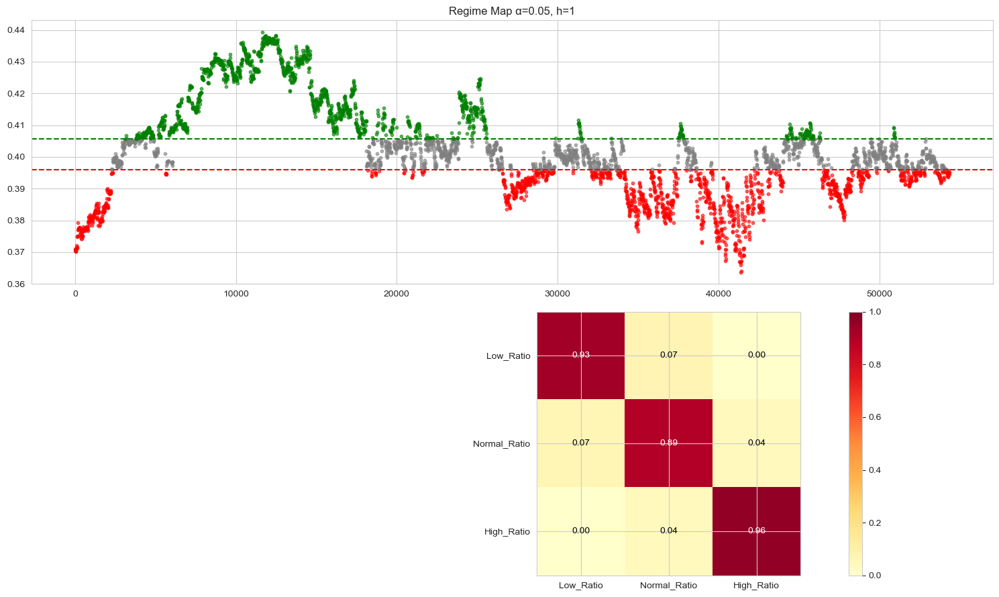

α=5.0%, h=5: p=1.0000, warnings=0


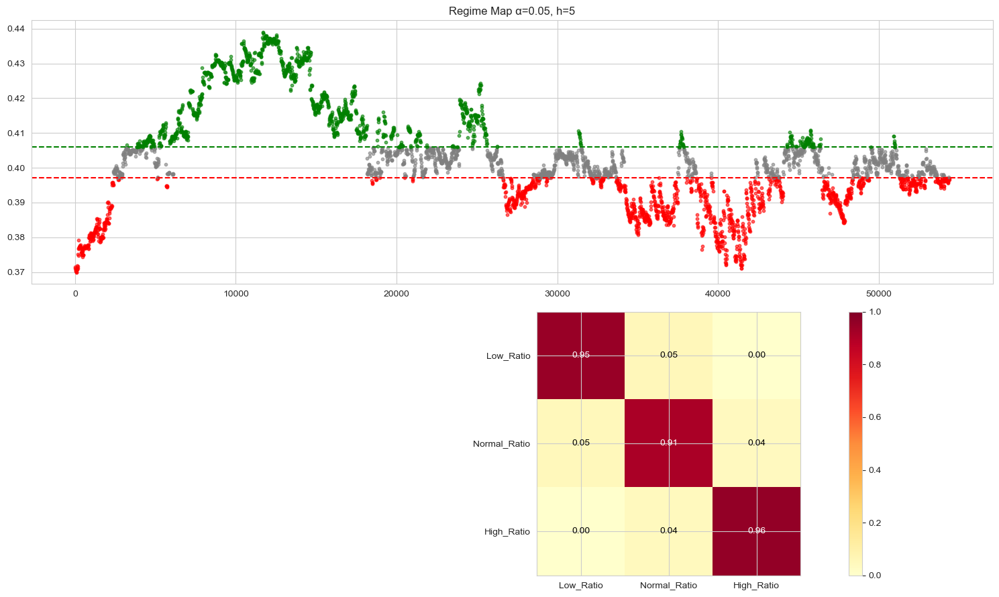

α=5.0%, h=10: p=1.0000, warnings=0


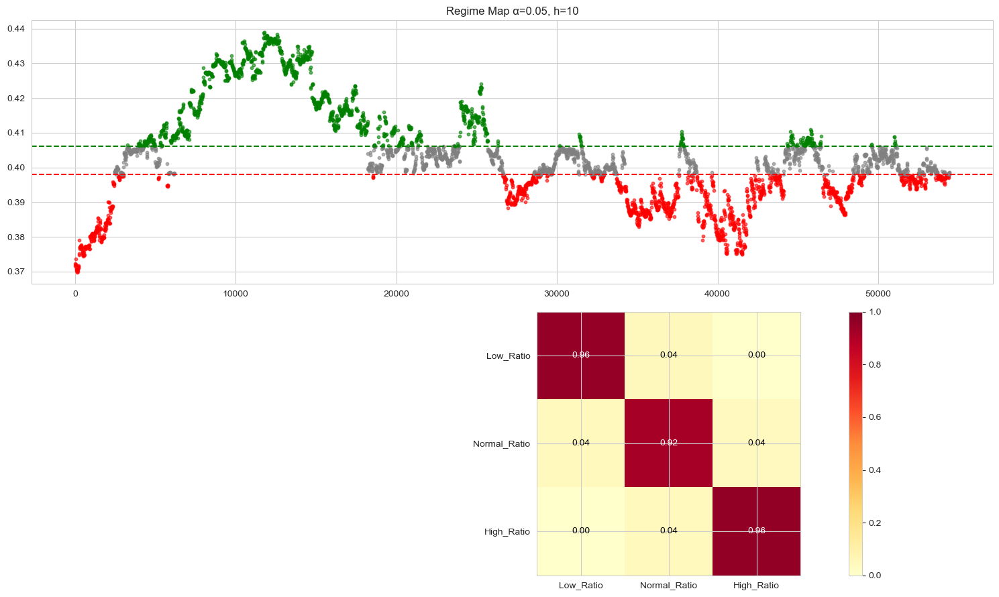

α=5.0%, h=21: p=1.0000, warnings=0


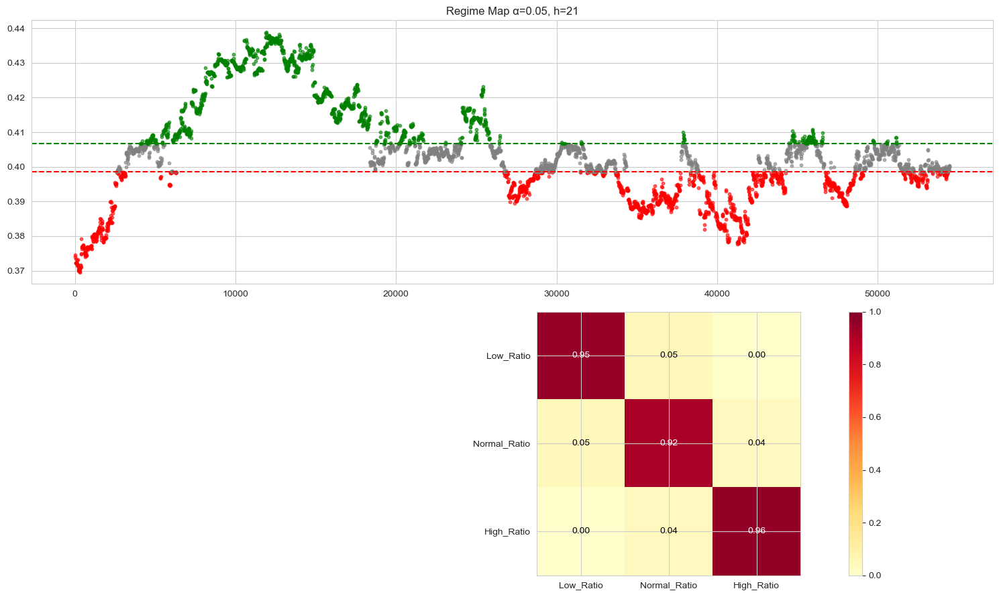

α=3.0%, h=1: p=1.0000, warnings=0


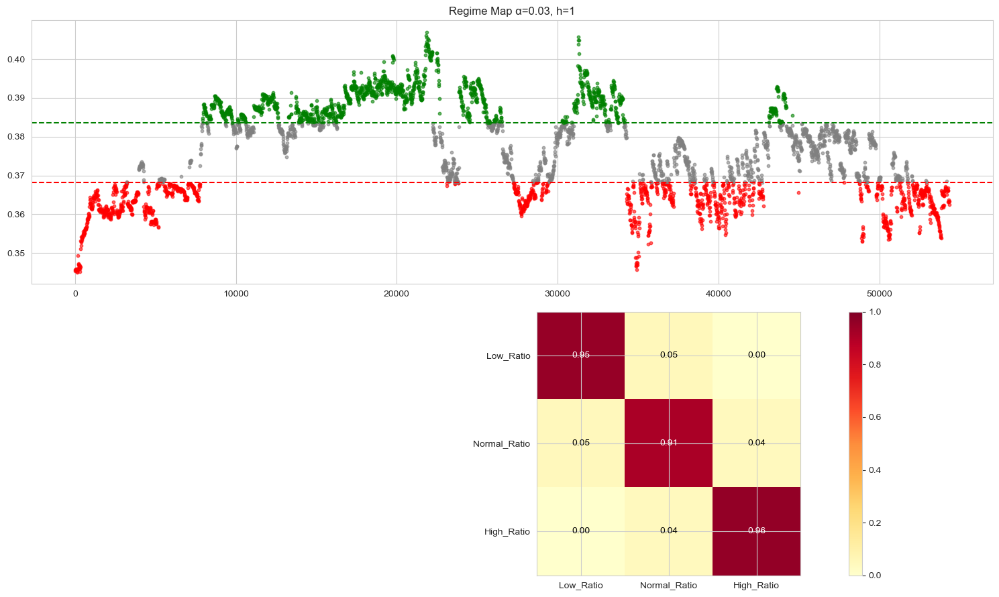

α=3.0%, h=5: p=1.0000, warnings=0


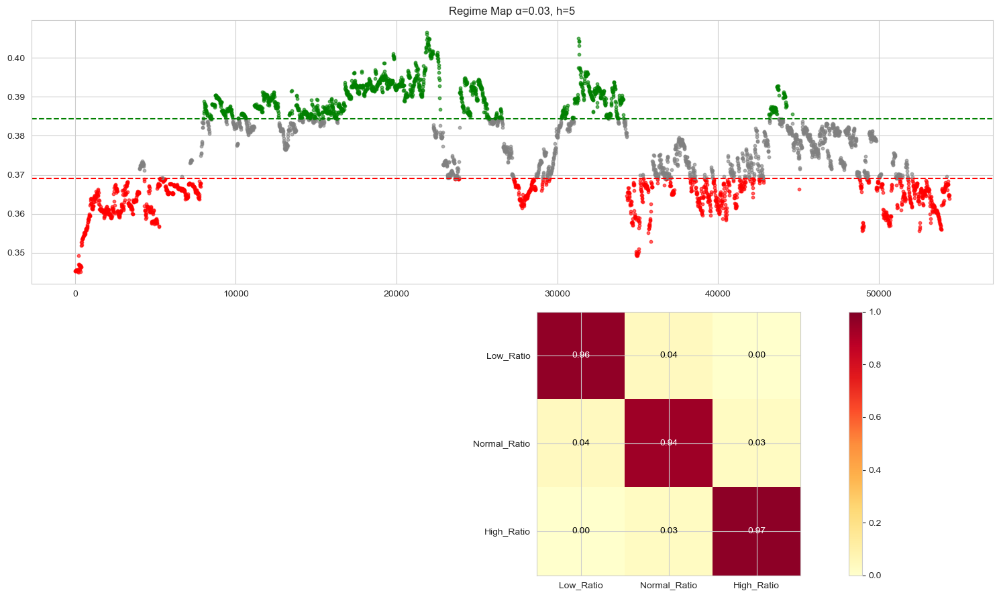

α=3.0%, h=10: p=1.0000, warnings=0


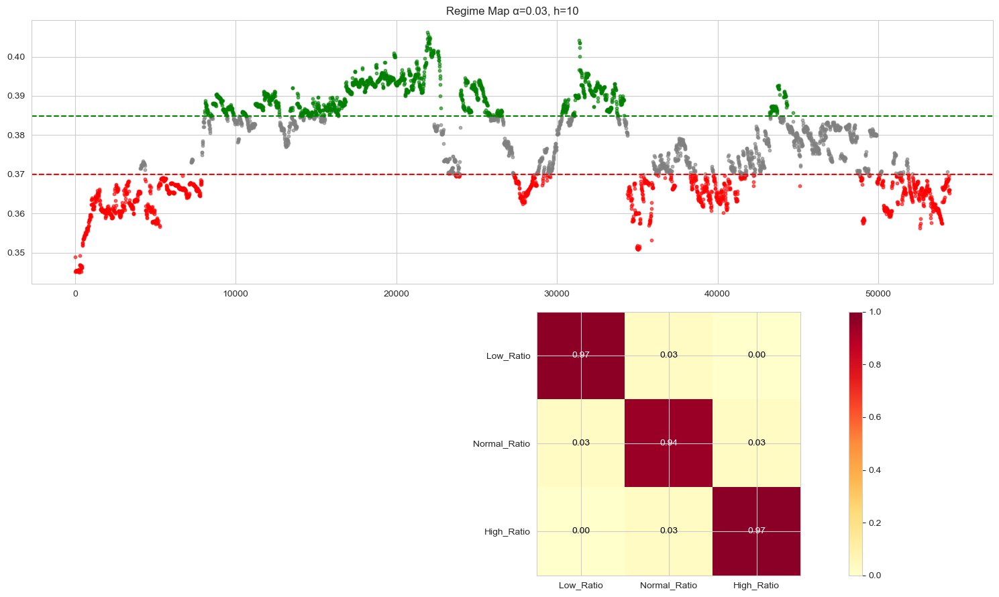

α=3.0%, h=21: p=1.0000, warnings=0


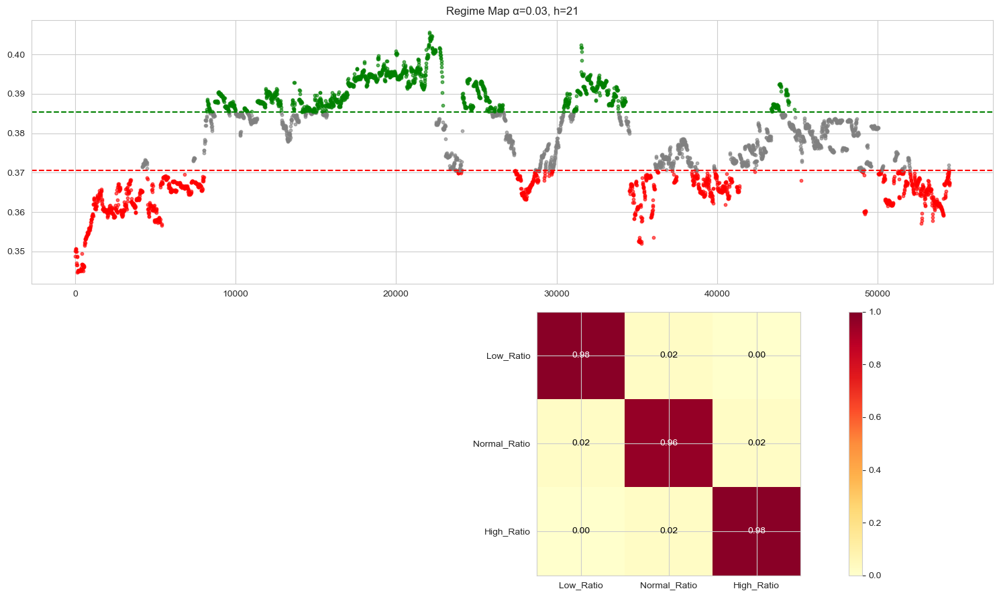

α=1.0%, h=1: p=1.0000, warnings=0


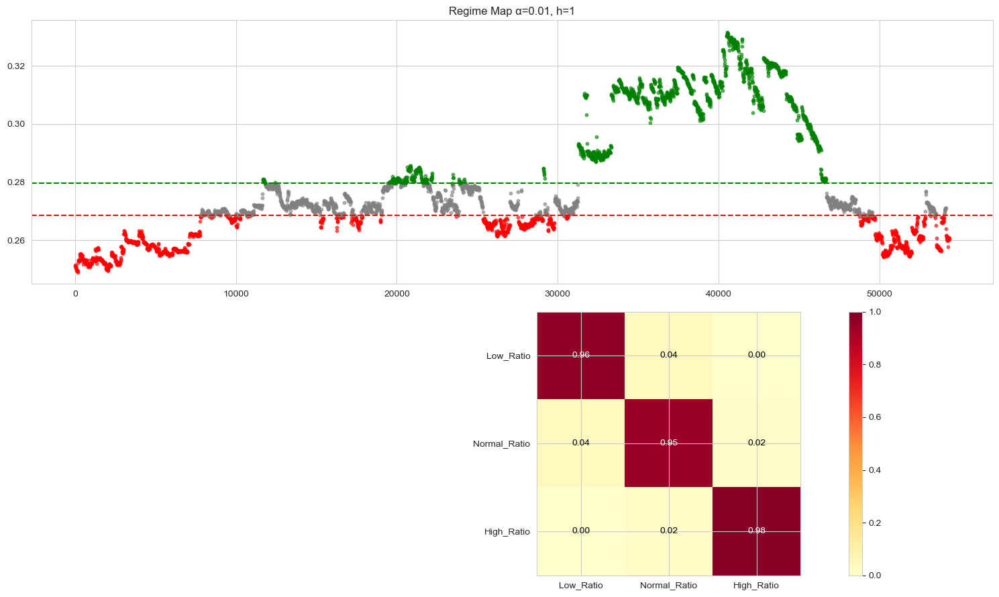

α=1.0%, h=5: p=1.0000, warnings=0


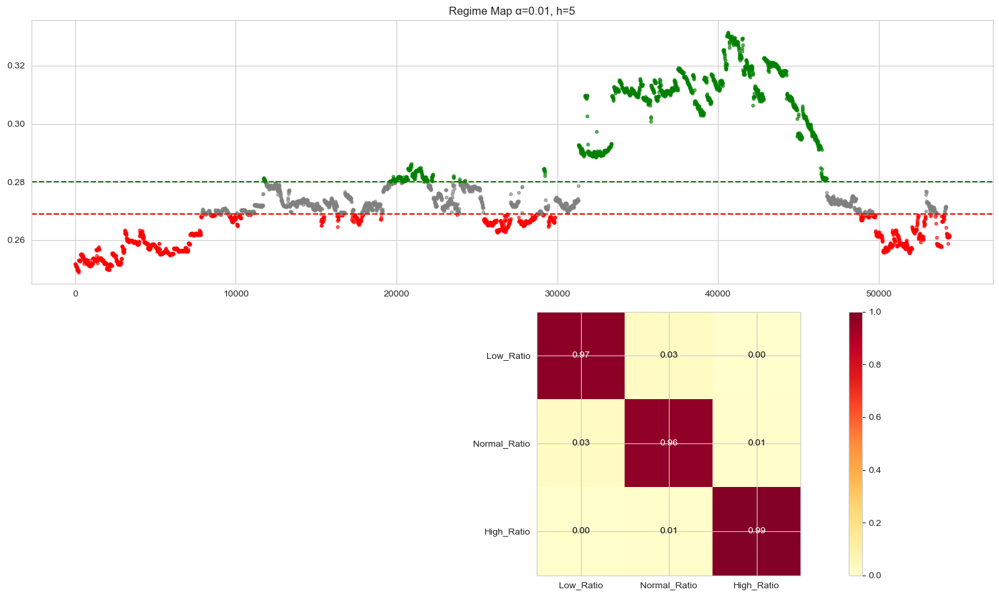

α=1.0%, h=10: p=1.0000, warnings=0


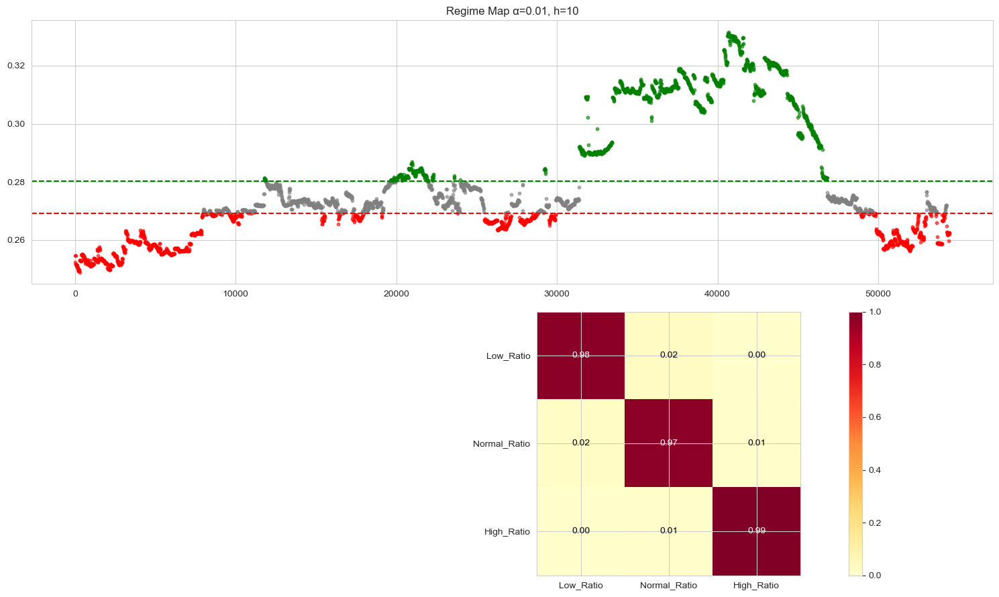

α=1.0%, h=21: p=1.0000, warnings=0


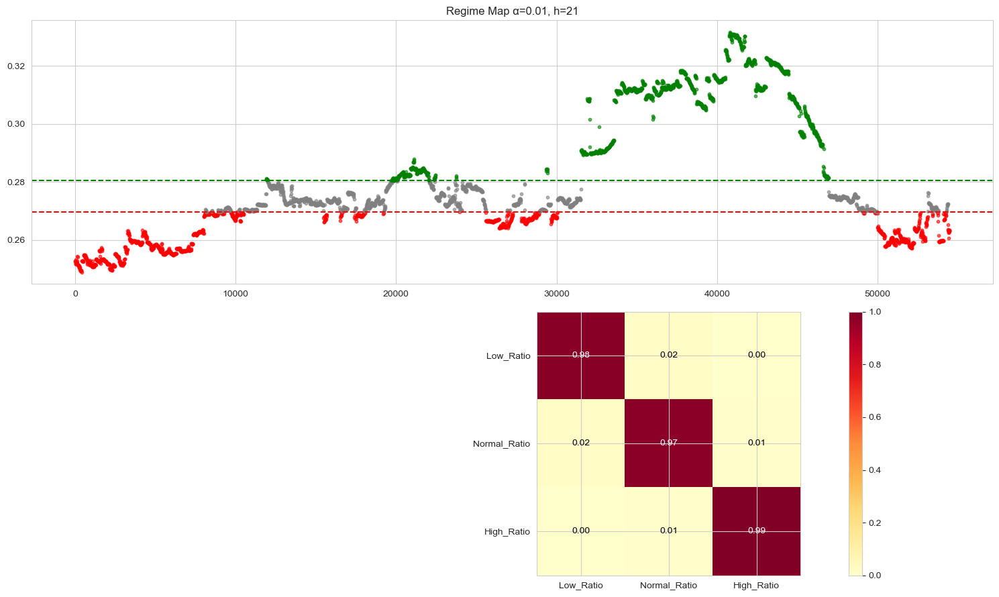

In [23]:
regime_results_full = comprehensive_regime_analysis(df_full)

α=5.0%, h=1: p=0.0000, warnings=7


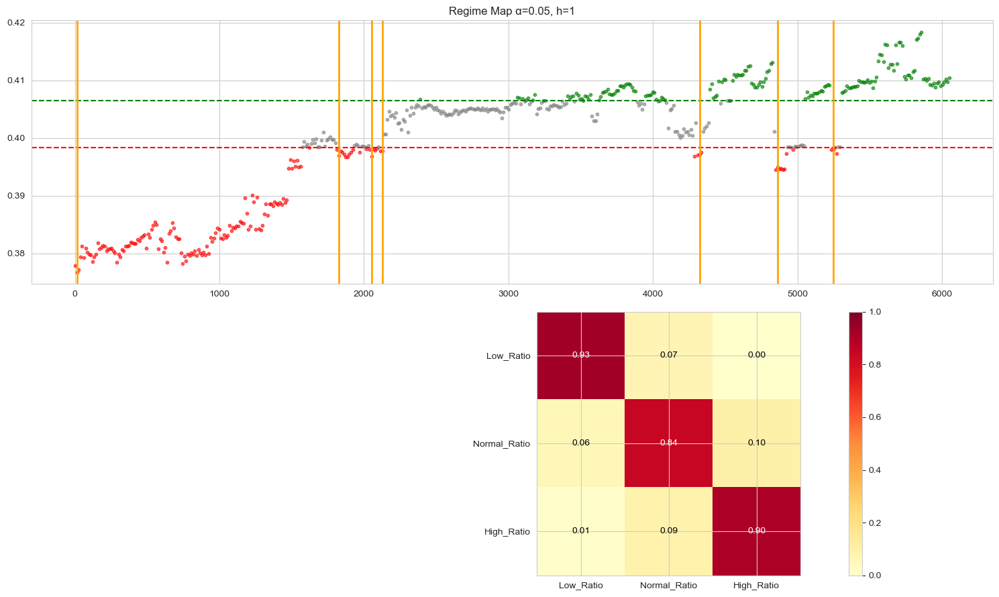

α=5.0%, h=5: p=0.0000, warnings=8


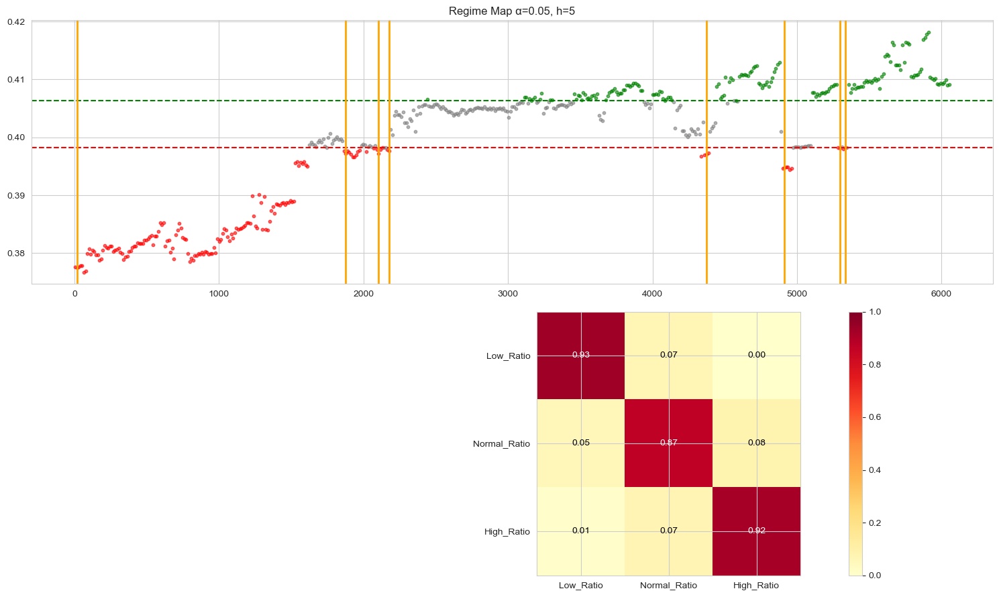

α=5.0%, h=10: p=0.0000, warnings=6


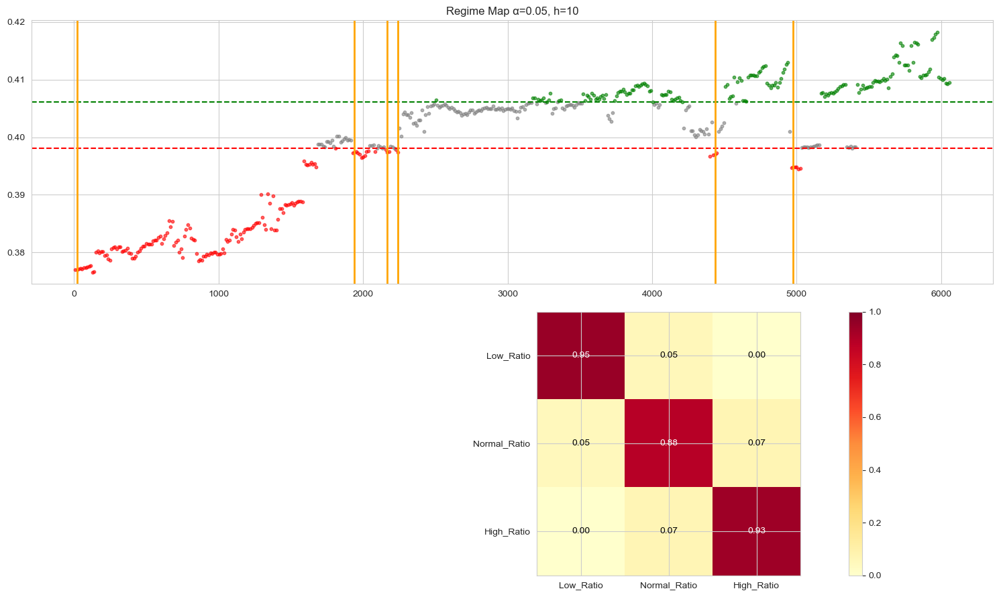

α=5.0%, h=21: p=0.0000, warnings=5


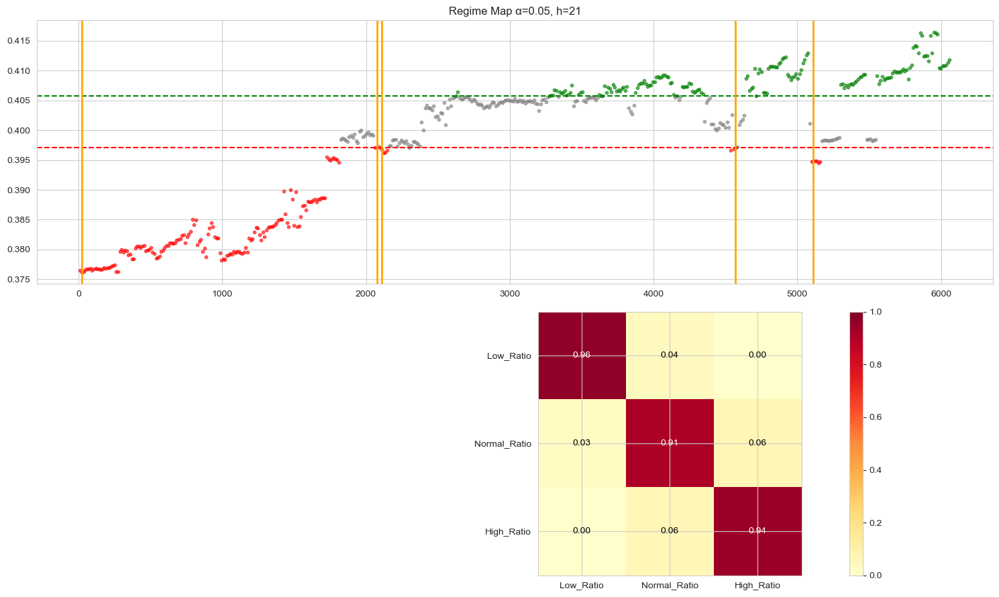

α=3.0%, h=1: p=0.0000, warnings=16


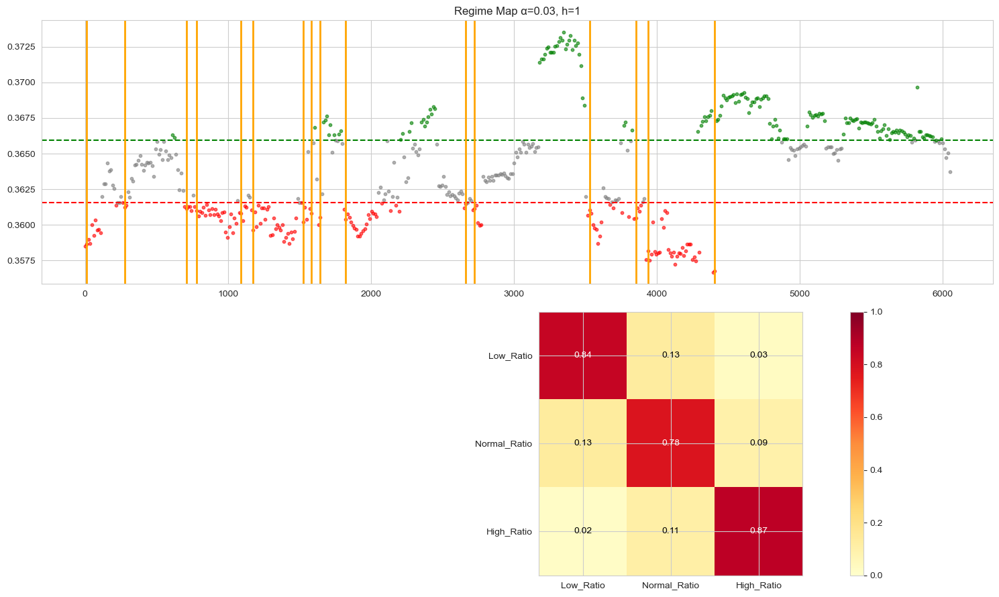

α=3.0%, h=5: p=0.0000, warnings=16


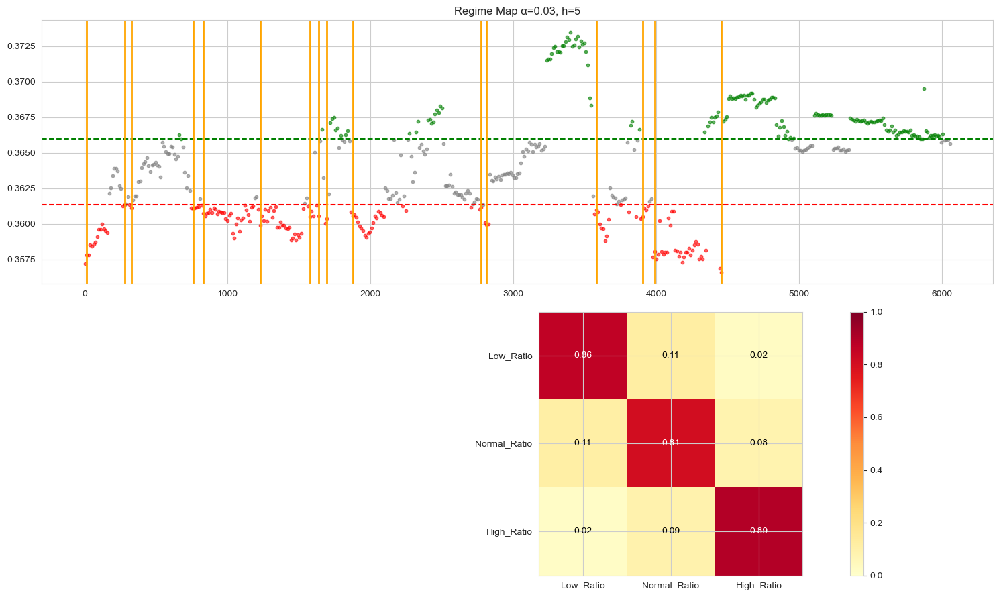

α=3.0%, h=10: p=0.0000, warnings=15


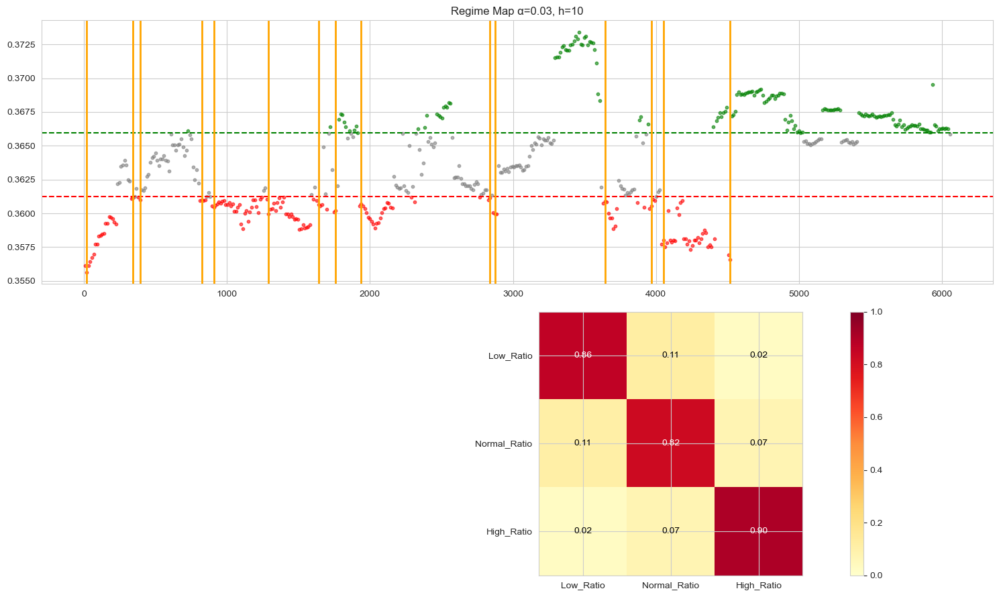

α=3.0%, h=21: p=0.0000, warnings=16


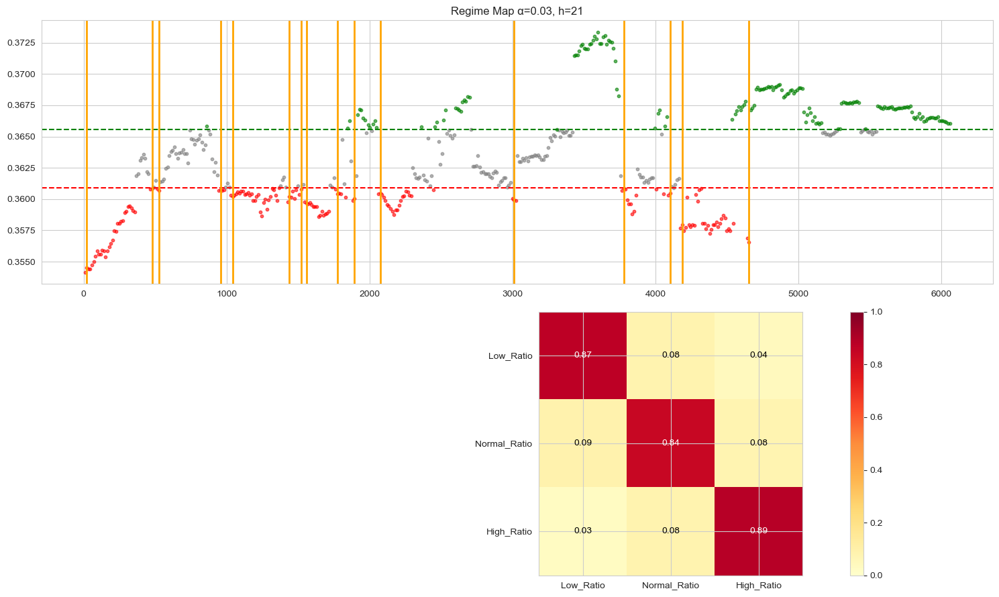

α=1.0%, h=1: p=0.0000, warnings=5


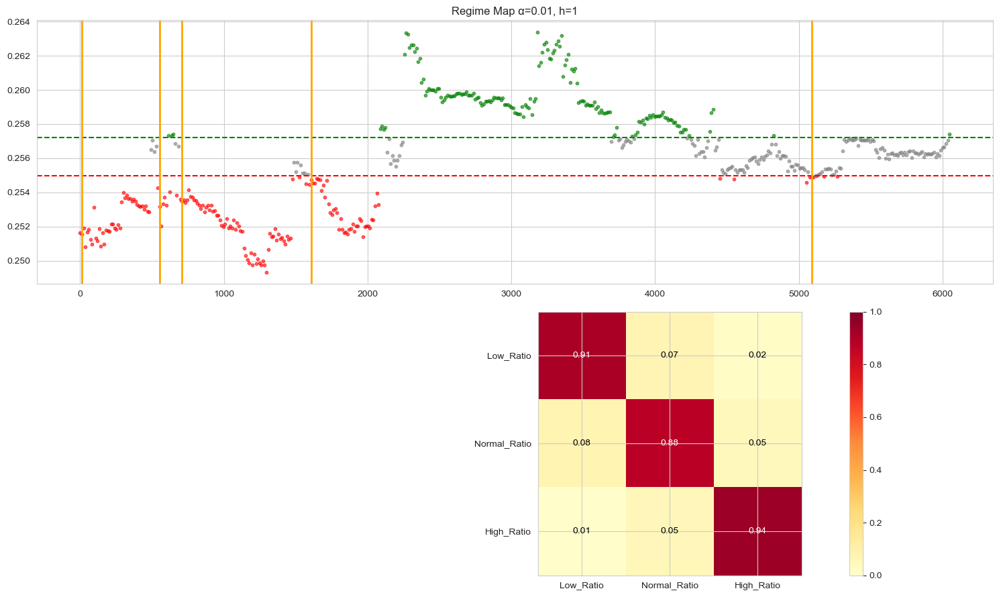

α=1.0%, h=5: p=0.0000, warnings=5


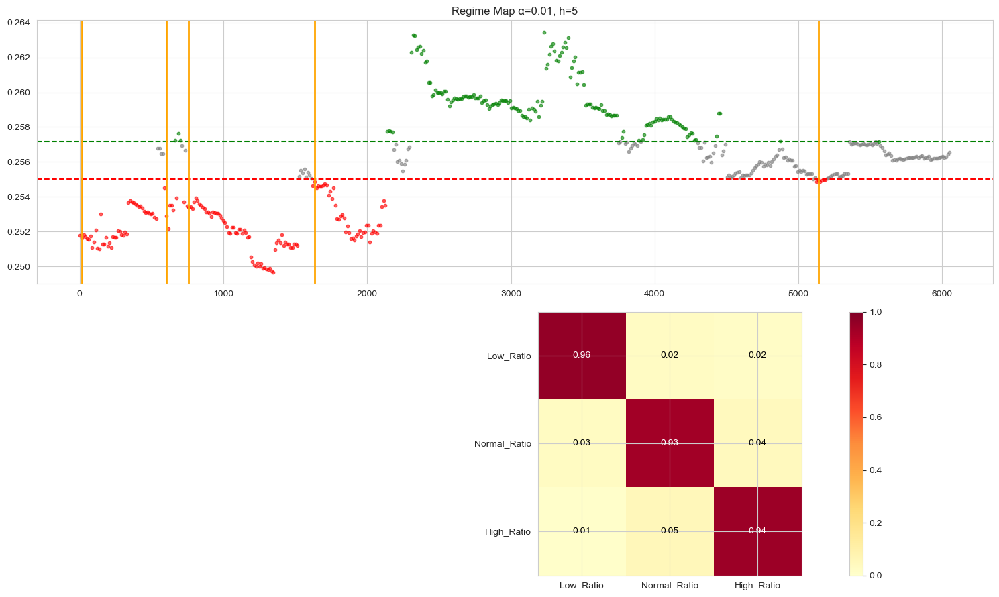

α=1.0%, h=10: p=0.0000, warnings=4


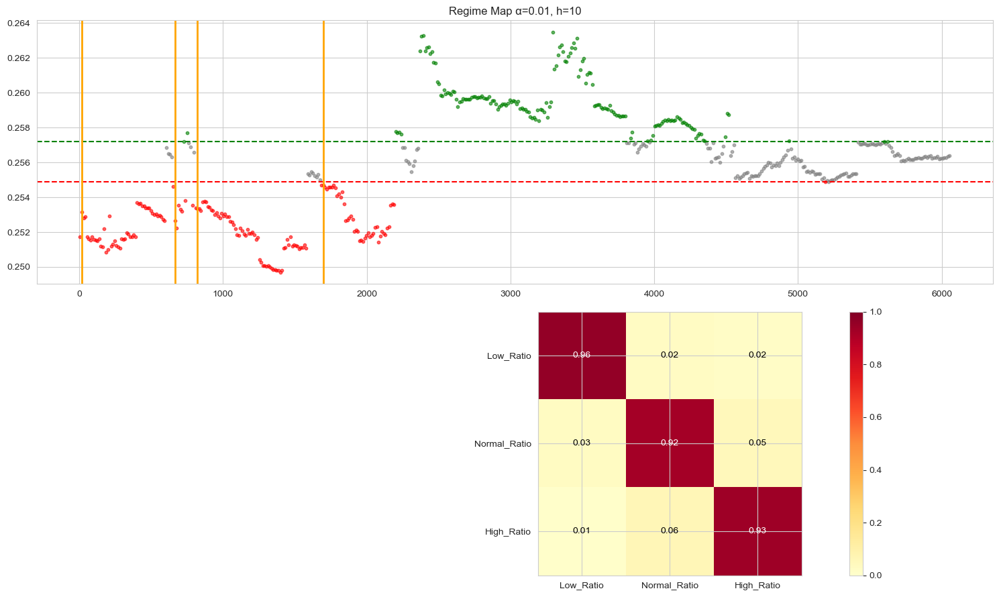

α=1.0%, h=21: p=0.0000, warnings=4


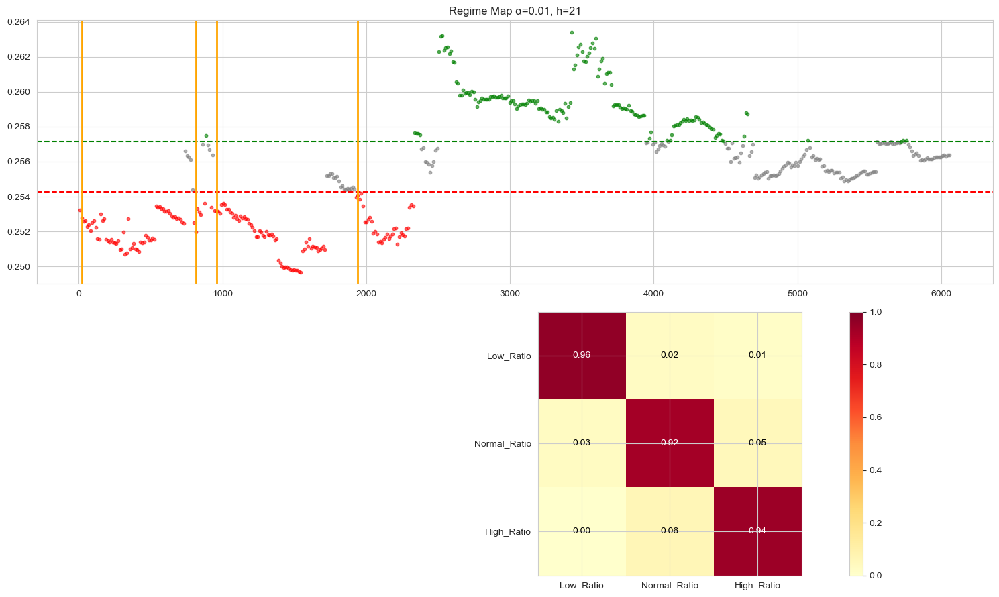

In [24]:
regime_results_crisis = comprehensive_regime_analysis(df_crisis)

α=5.0%, h=1: p=0.0000, warnings=8


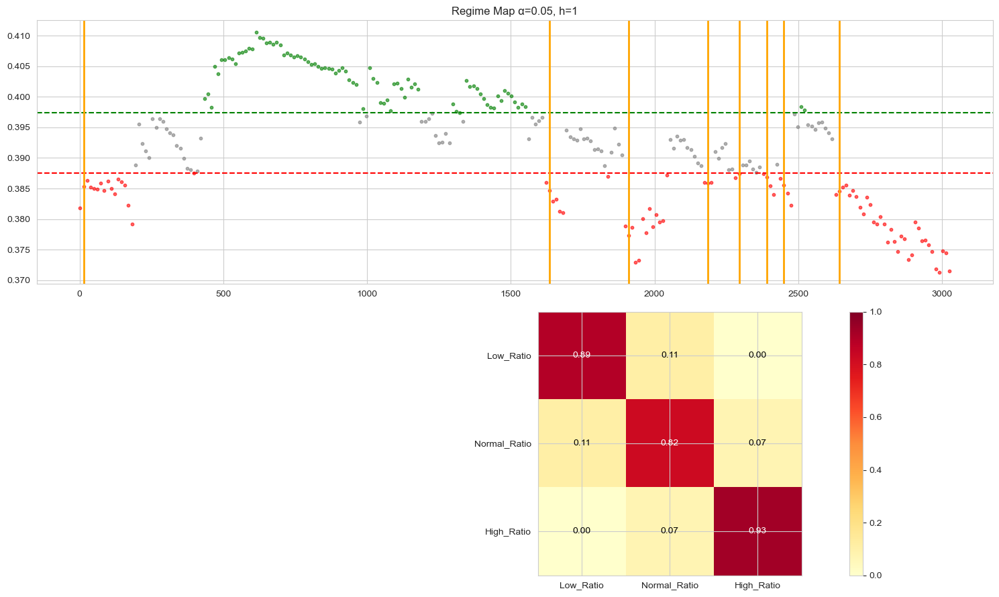

α=5.0%, h=5: p=0.0000, warnings=9


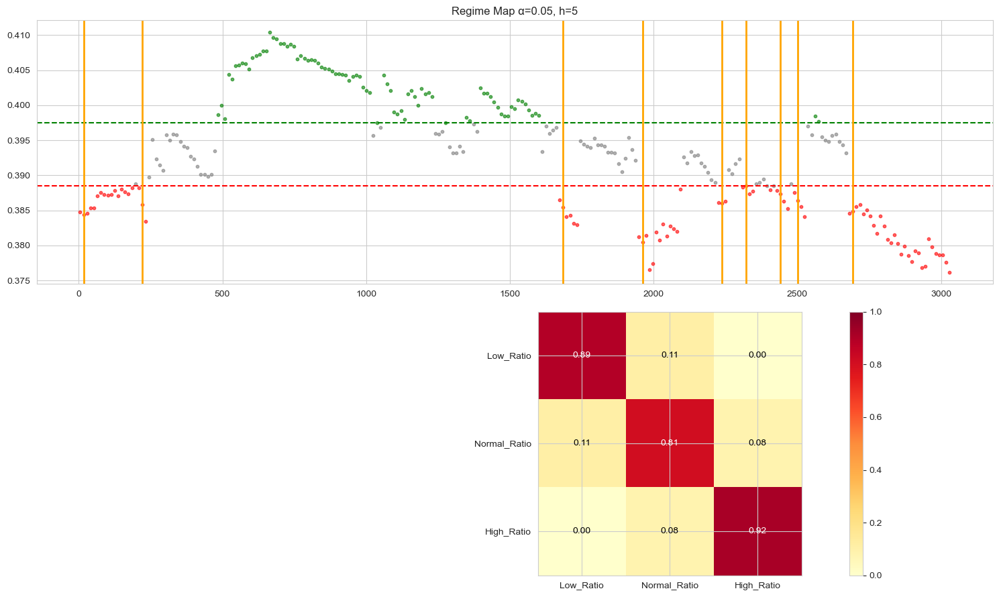

α=5.0%, h=10: p=0.0000, warnings=8


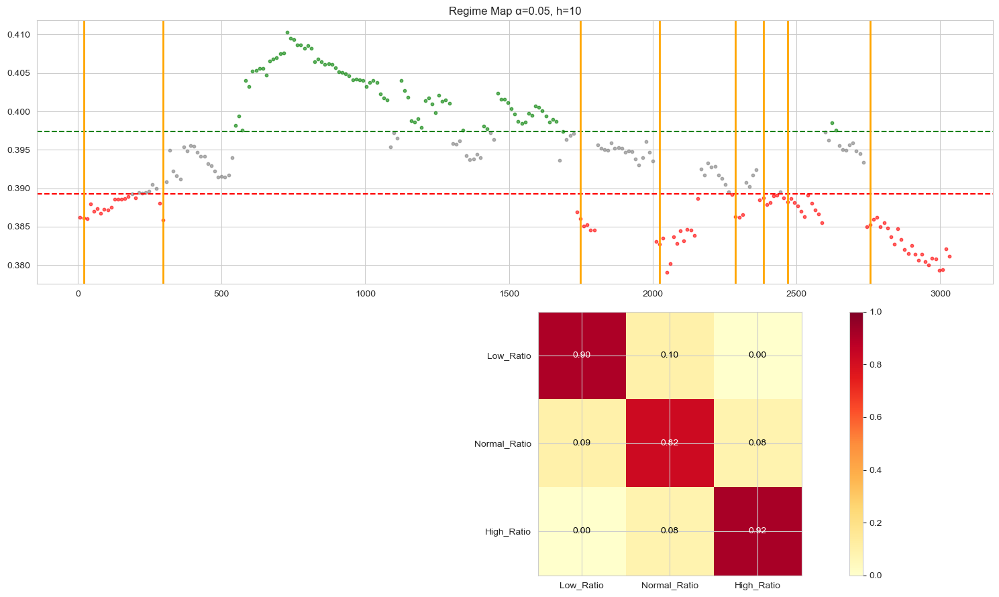

α=5.0%, h=21: p=0.0000, warnings=8


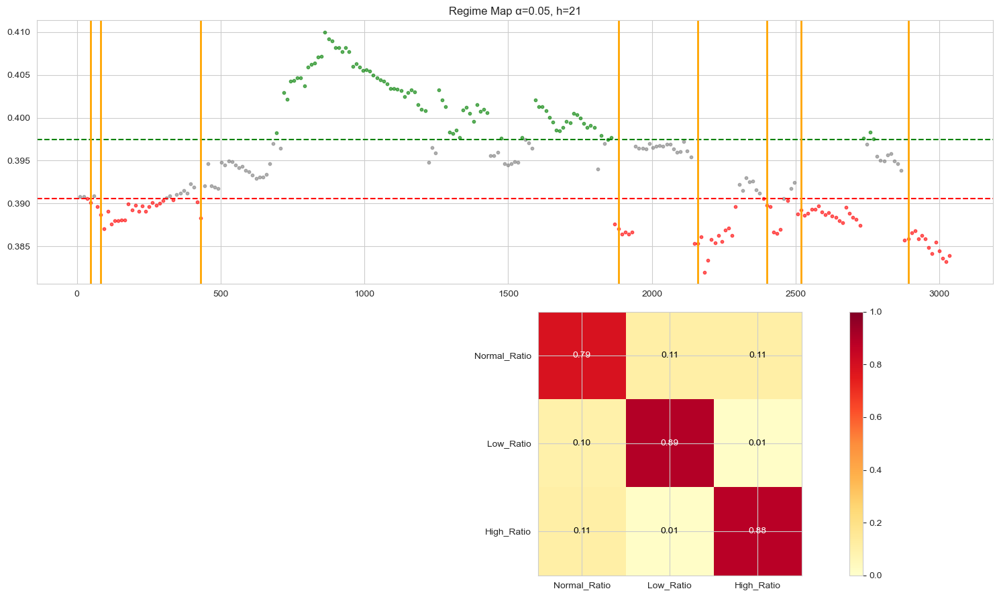

α=3.0%, h=1: p=0.0000, warnings=7


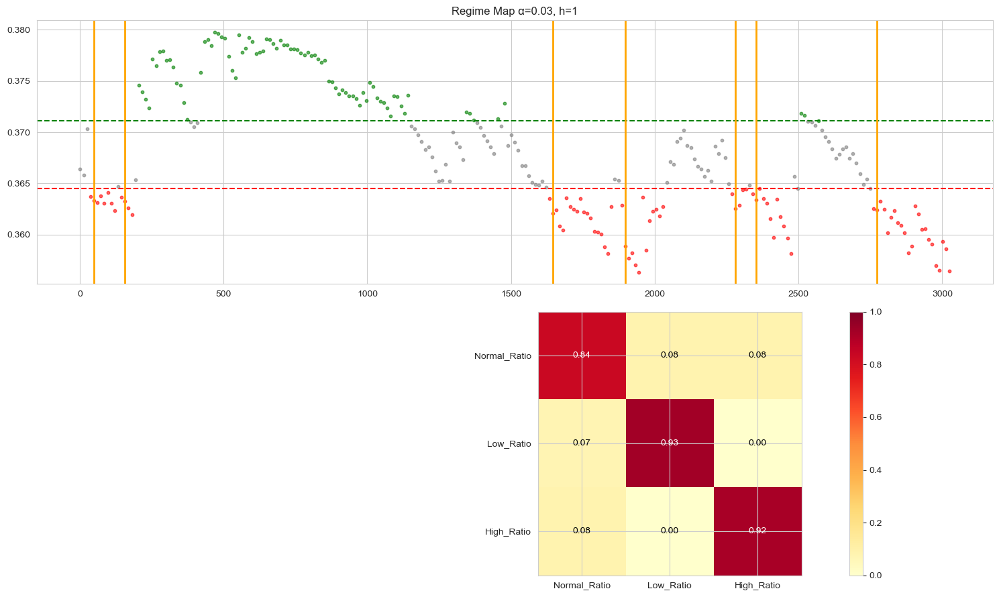

α=3.0%, h=5: p=0.0000, warnings=7


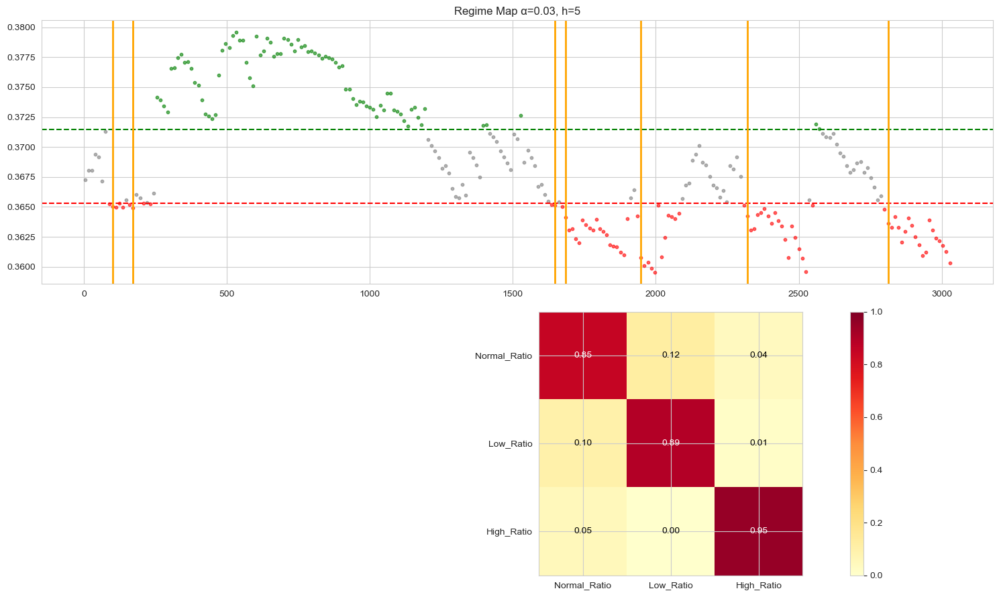

α=3.0%, h=10: p=0.0000, warnings=7


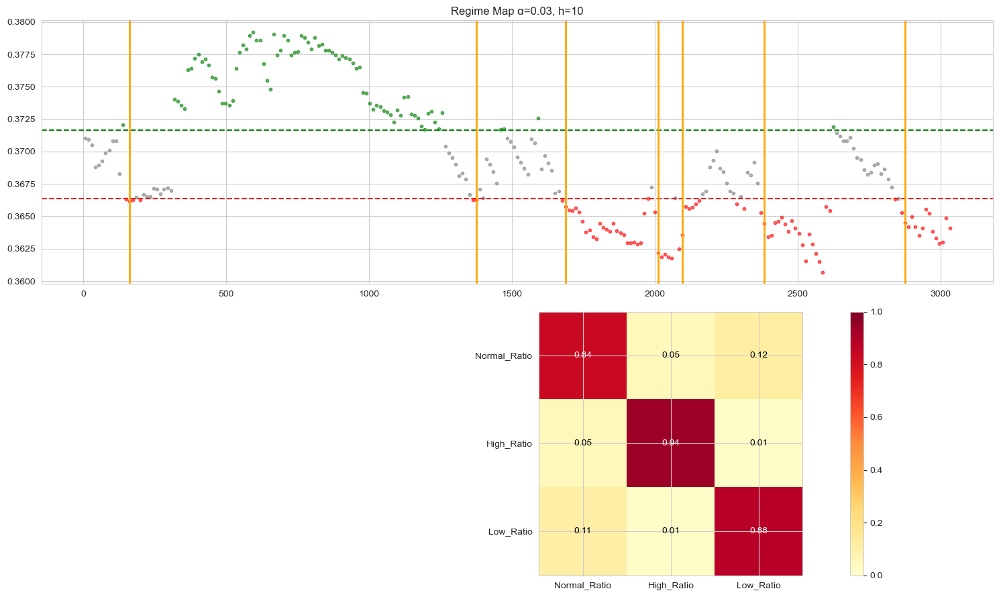

α=3.0%, h=21: p=0.0000, warnings=9


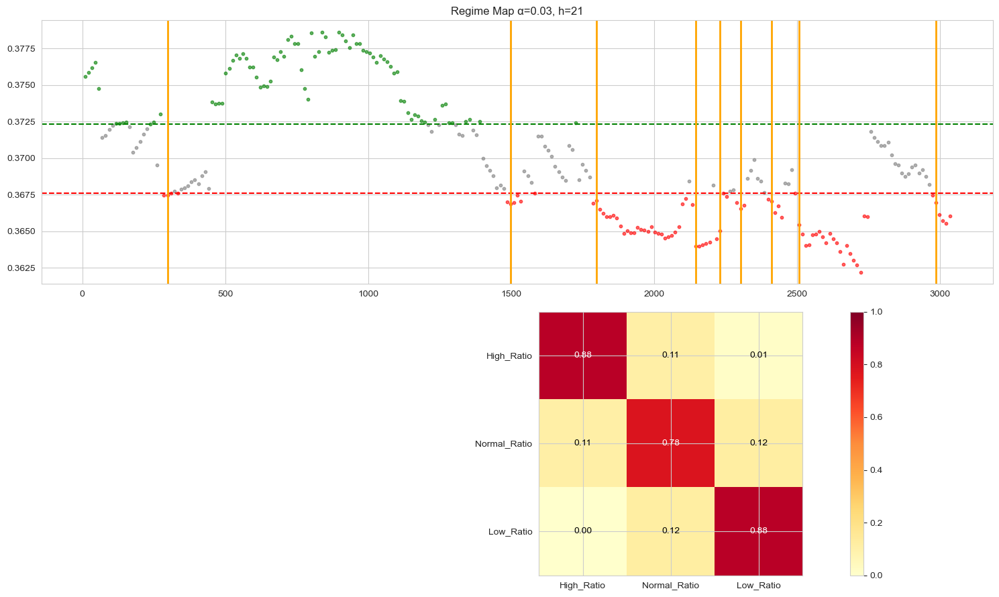

α=1.0%, h=1: p=0.0000, warnings=5


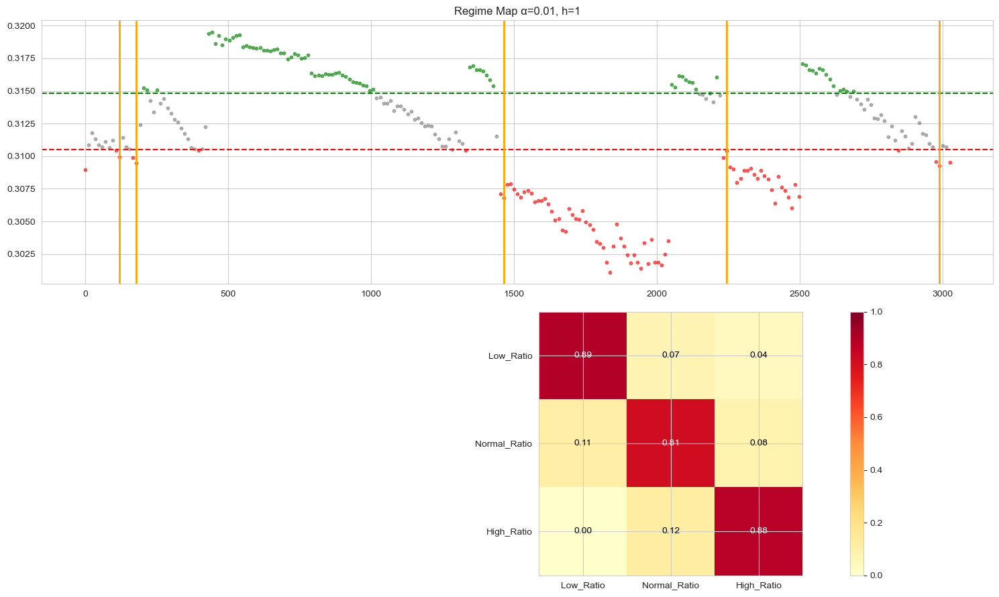

α=1.0%, h=5: p=0.0000, warnings=5


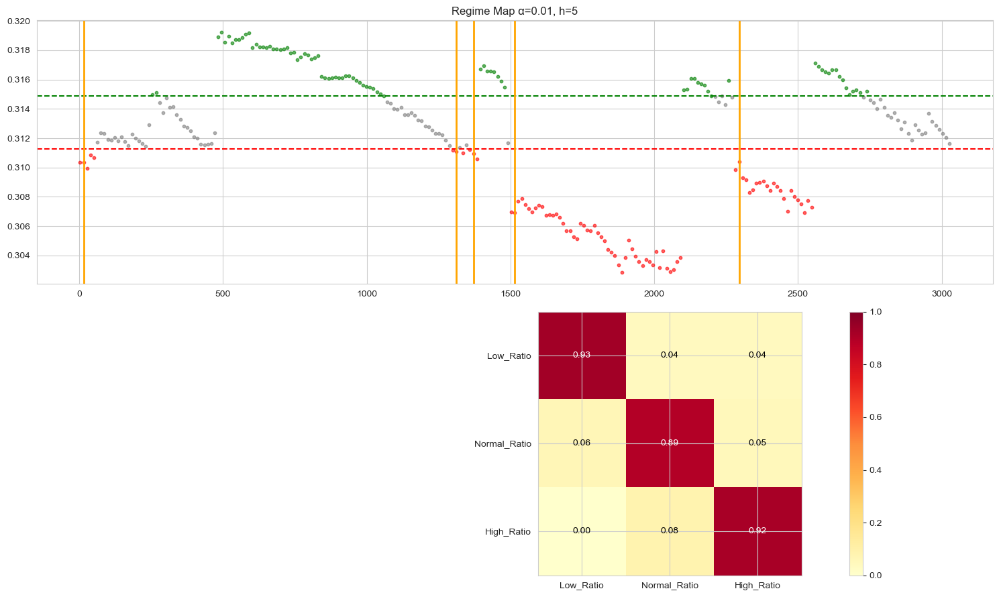

α=1.0%, h=10: p=0.0000, warnings=4


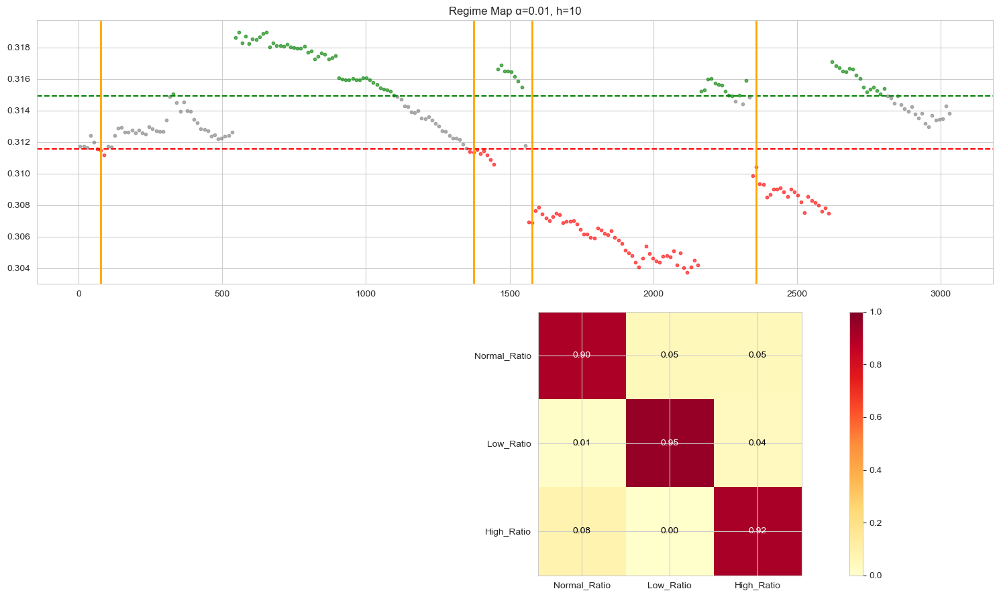

α=1.0%, h=21: p=0.0000, warnings=3


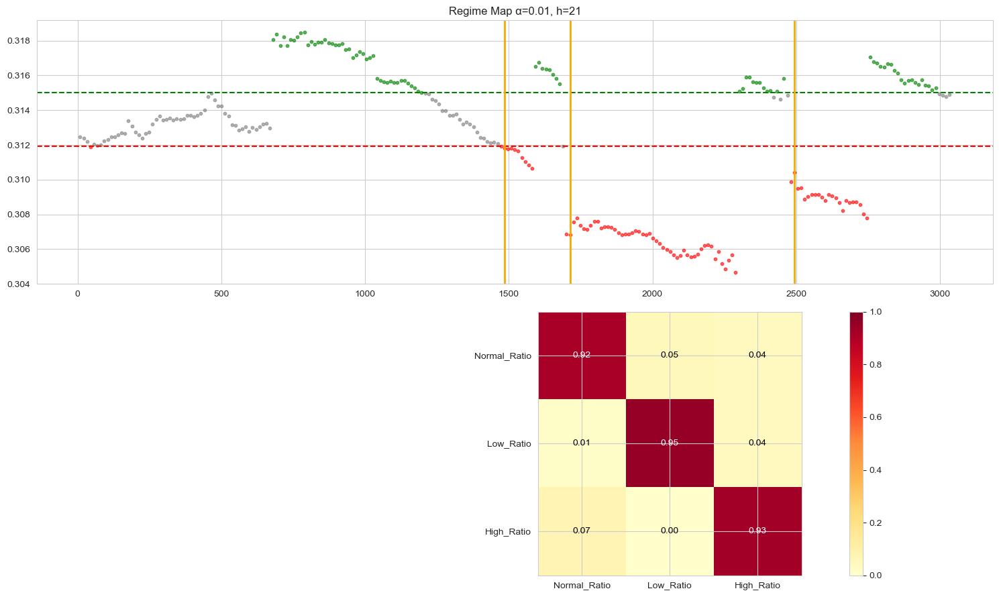

In [25]:
regime_results_covid = comprehensive_regime_analysis(df_covid)

α=5.0%, h=1: p=0.0000, warnings=3


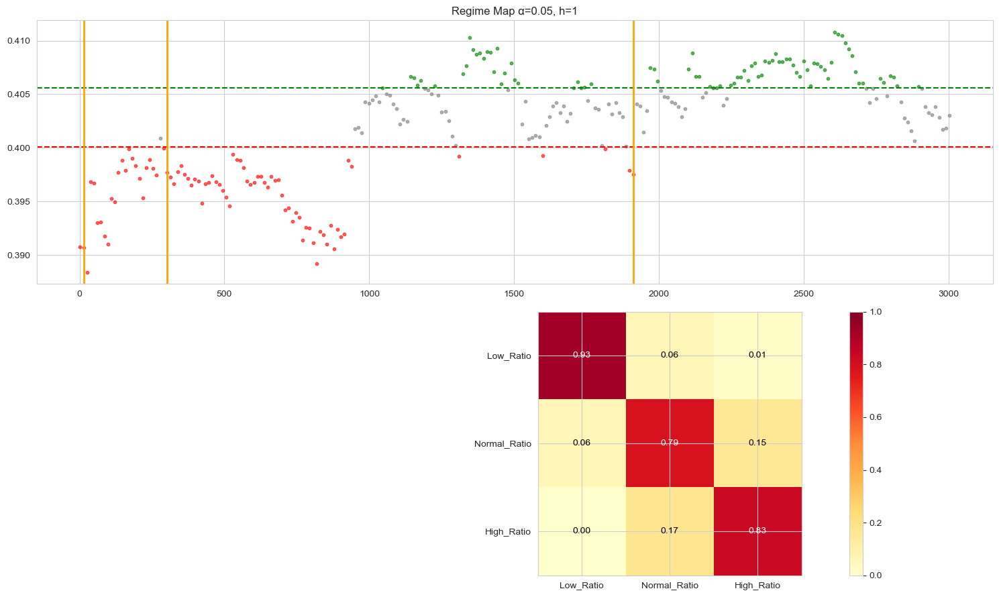

α=5.0%, h=5: p=0.0000, warnings=4


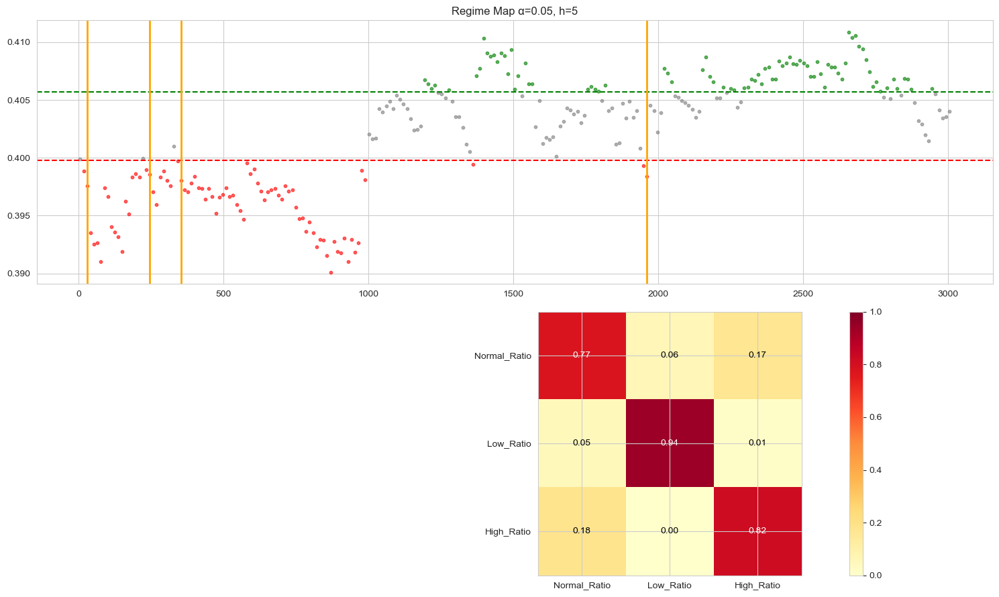

α=5.0%, h=10: p=0.0000, warnings=3


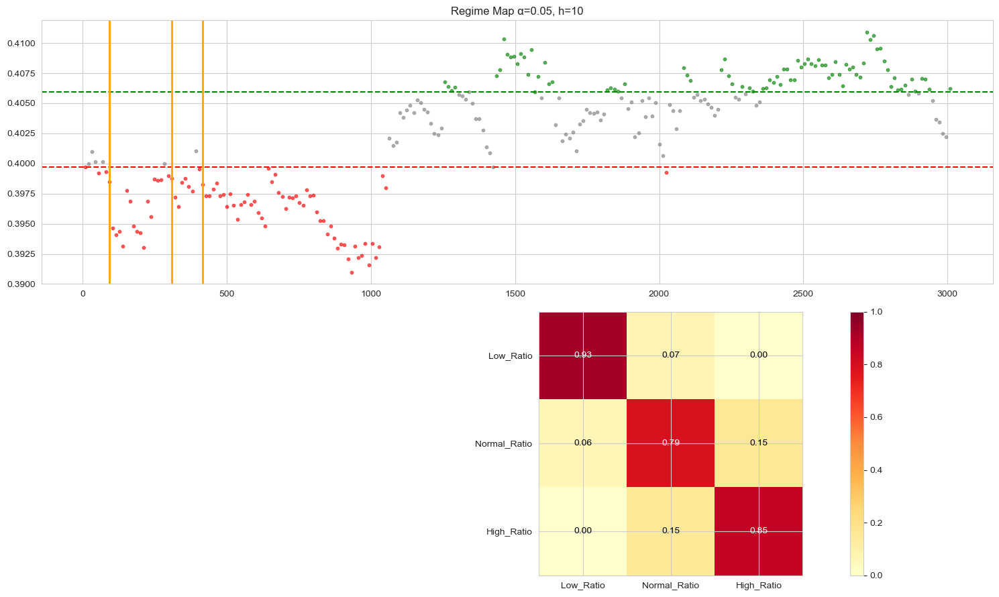

α=5.0%, h=21: p=0.0000, warnings=3


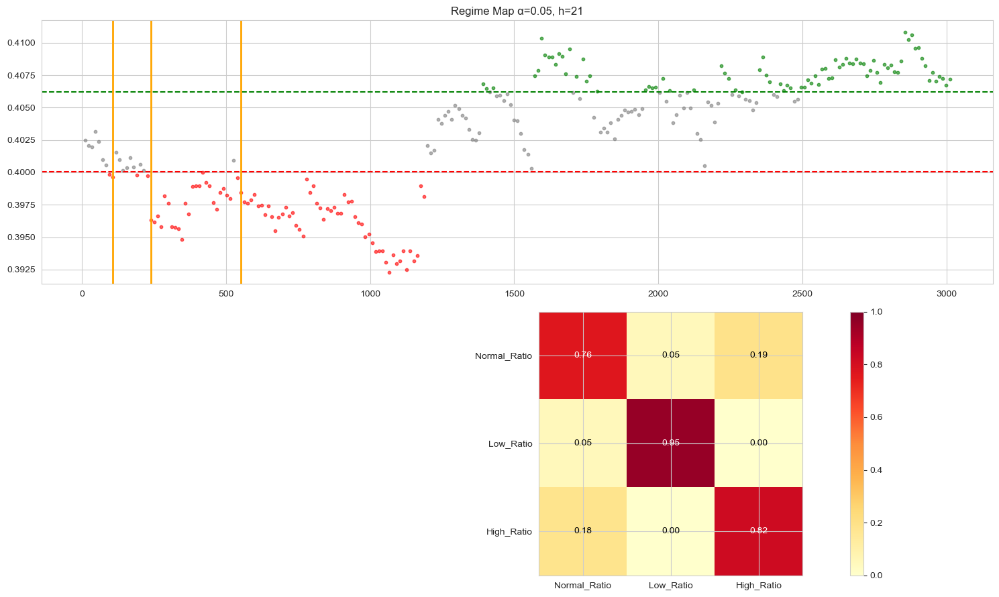

α=3.0%, h=1: p=0.0000, warnings=6


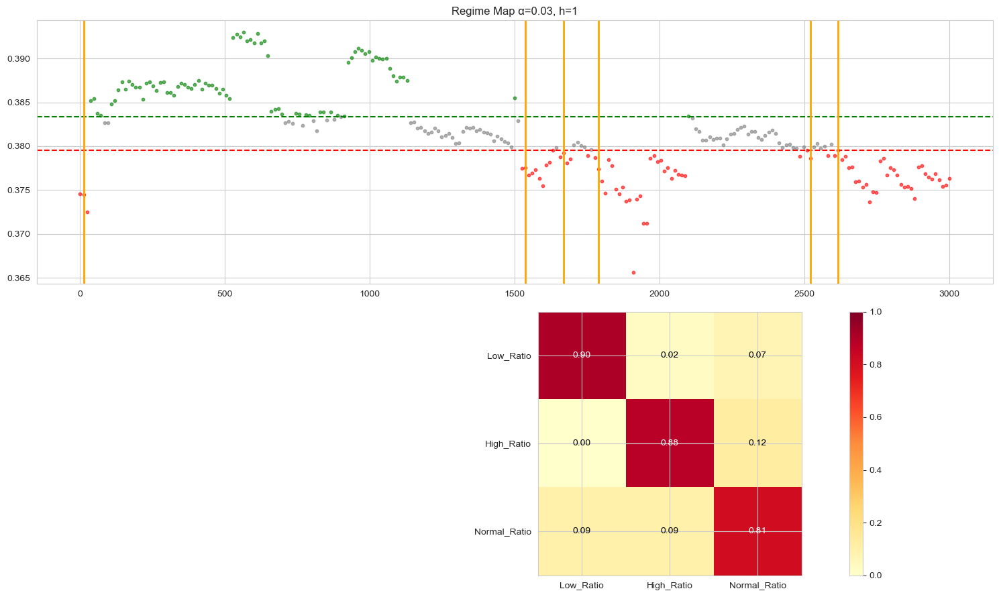

α=3.0%, h=5: p=0.0000, warnings=7


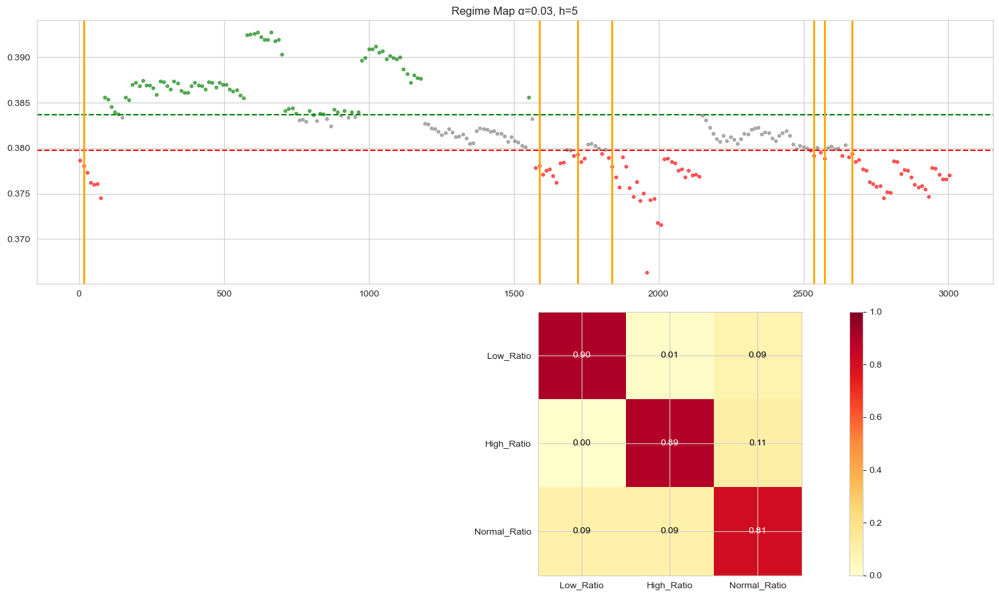

α=3.0%, h=10: p=0.0000, warnings=7


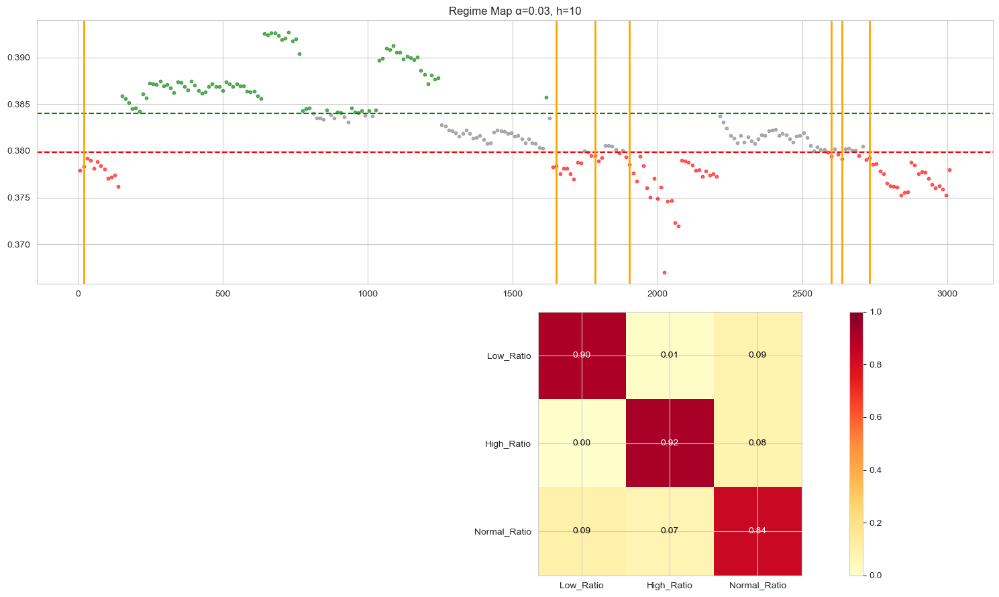

α=3.0%, h=21: p=0.0000, warnings=6


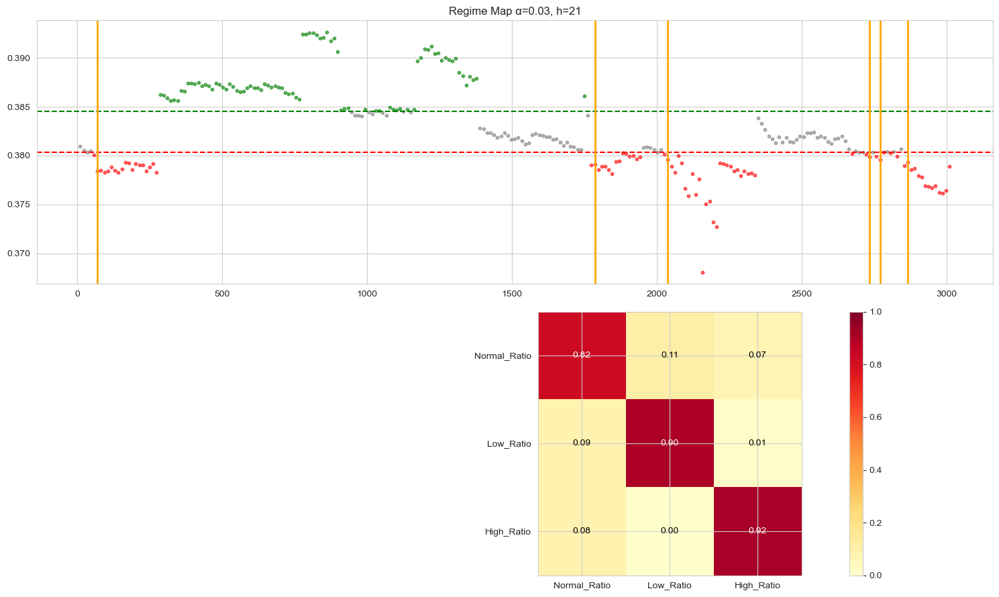

α=1.0%, h=1: p=0.0000, warnings=4


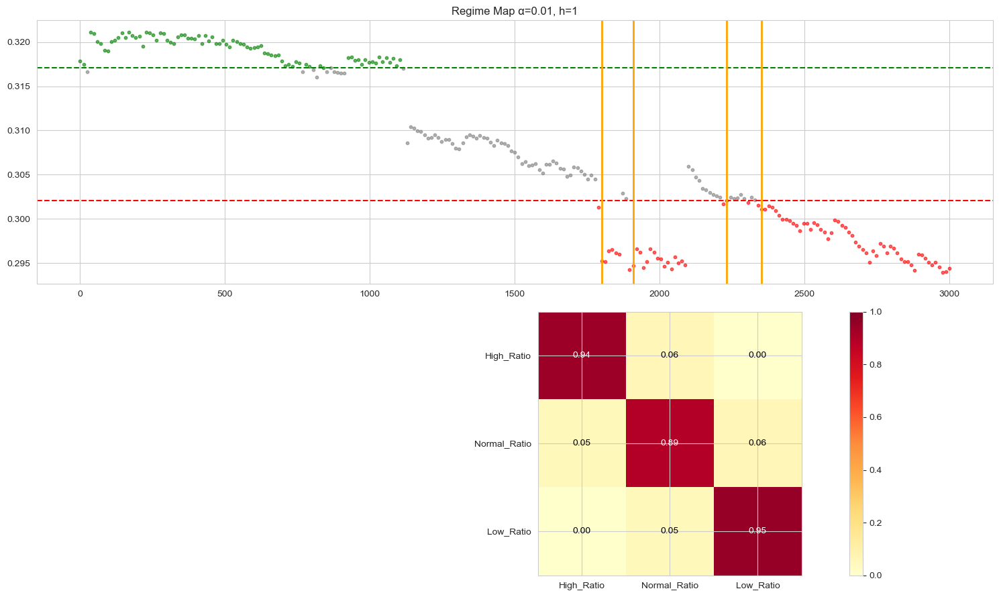

α=1.0%, h=5: p=0.0000, warnings=5


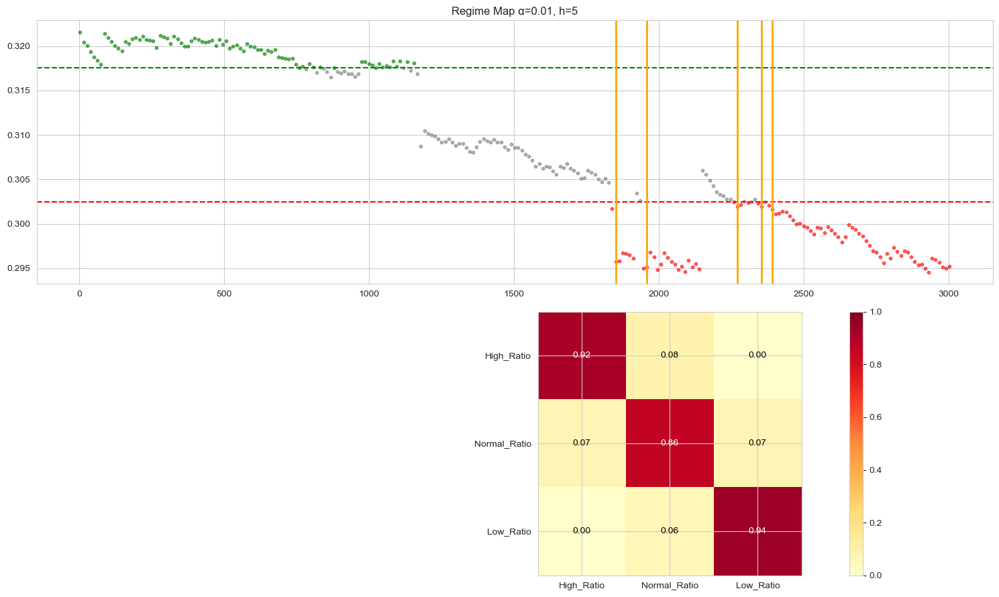

α=1.0%, h=10: p=0.0000, warnings=3


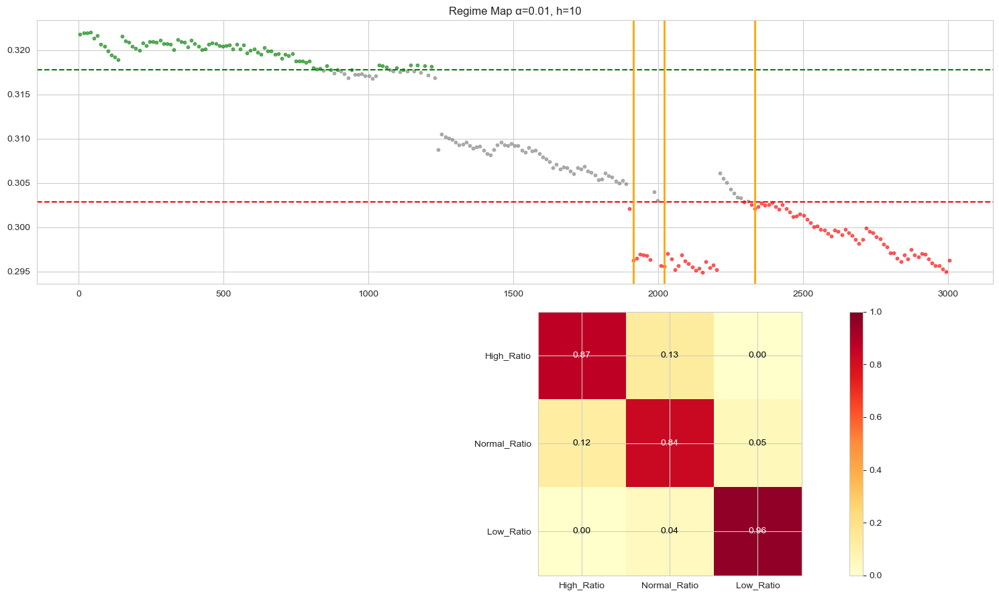

α=1.0%, h=21: p=0.0000, warnings=3


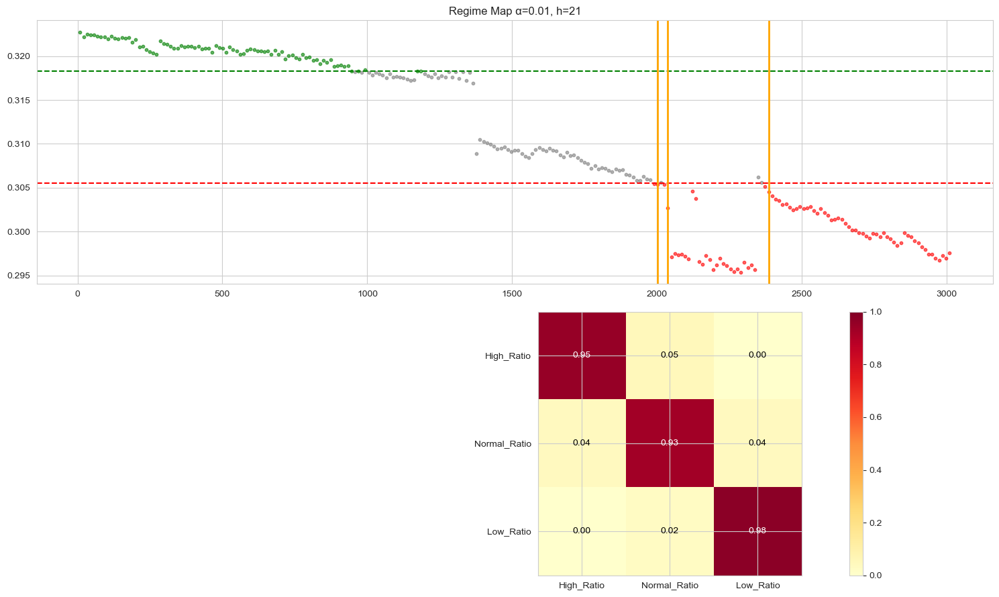

In [26]:
regime_results_infl = comprehensive_regime_analysis(df_infl)

## 3.5.1. Rearranging the Above Plot

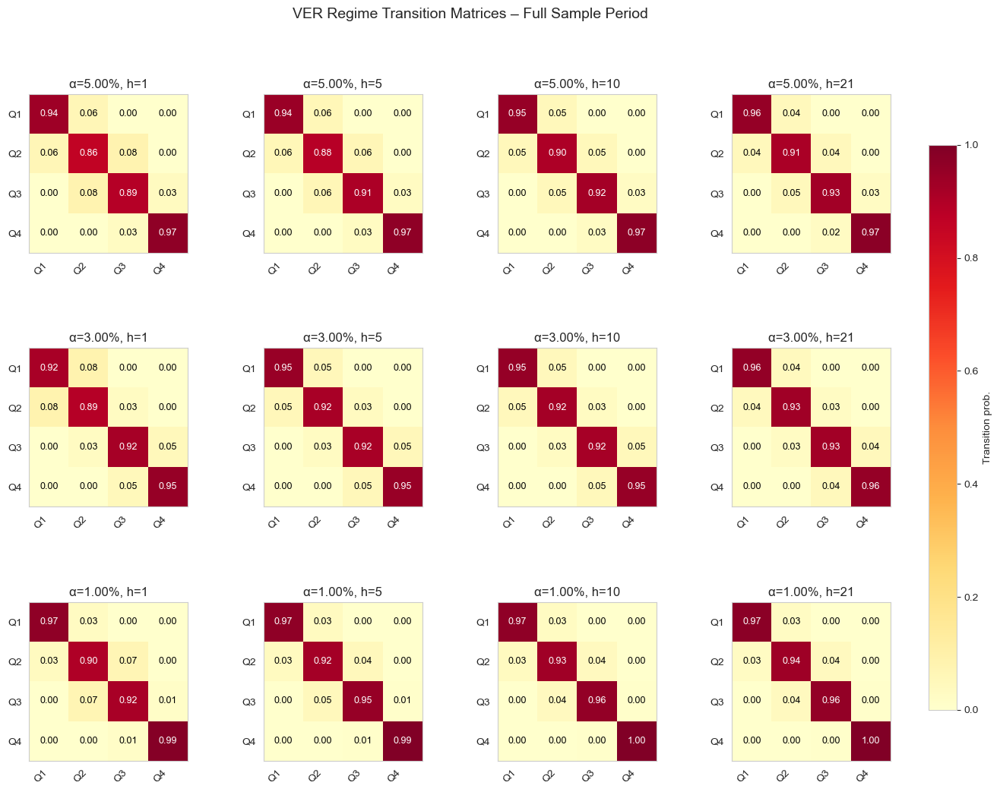

{(0.05,
  1): array([[9.37334510e-01, 6.09002648e-02, 1.76522507e-03, 0.00000000e+00],
        [6.18921309e-02, 8.58532272e-01, 7.95755968e-02, 0.00000000e+00],
        [0.00000000e+00, 8.03886926e-02, 8.87809187e-01, 3.18021201e-02],
        [0.00000000e+00, 8.82612533e-04, 3.08914387e-02, 9.68225949e-01]]),
 (0.05,
  5): array([[9.43562610e-01, 5.55555556e-02, 8.81834215e-04, 0.00000000e+00],
        [5.56537102e-02, 8.83392226e-01, 6.00706714e-02, 8.83392226e-04],
        [0.00000000e+00, 6.00176523e-02, 9.09090909e-01, 3.08914387e-02],
        [0.00000000e+00, 1.76366843e-03, 2.99823633e-02, 9.68253968e-01]]),
 (0.05,
  10): array([[9.51541850e-01, 4.75770925e-02, 8.81057269e-04, 0.00000000e+00],
        [4.76190476e-02, 9.02998236e-01, 4.85008818e-02, 8.81834215e-04],
        [0.00000000e+00, 4.85008818e-02, 9.24162257e-01, 2.73368607e-02],
        [0.00000000e+00, 1.76211454e-03, 2.64317181e-02, 9.71806167e-01]]),
 (0.05,
  21): array([[9.55184534e-01, 4.30579965e-02, 1.75746924e

In [27]:
def compute_regime_series(df, alpha, horizon):
    d = df[(df["Alpha"] == alpha) & (df["ForecastHorizon"] == horizon)].copy()
    if d.empty:
        return None, None

    q1, q2, q3 = d["VaR_Ratio"].quantile([0.25, 0.50, 0.75])

    d["Regime"] = np.select(
        [
            d["VaR_Ratio"] <= q1,
            (d["VaR_Ratio"] > q1) & (d["VaR_Ratio"] <= q2),
            (d["VaR_Ratio"] > q2) & (d["VaR_Ratio"] <= q3),
            d["VaR_Ratio"] > q3,
        ],
        ["Q1", "Q2", "Q3", "Q4"],
        default="Q1"
    )
    
    return d["Regime"], (q1, q2, q3)

def markov_matrix_from_regimes(regimes, states=("Q1", "Q2", "Q3", "Q4")):
    idx = {s: i for i, s in enumerate(states)}
    k = len(states)
    counts = np.zeros((k, k))
    r = regimes.to_numpy()
    for t in range(len(r) - 1):
        s0, s1 = r[t], r[t + 1]
        if s0 in idx and s1 in idx:
            counts[idx[s0], idx[s1]] += 1
    with np.errstate(divide="ignore", invalid="ignore"):
        P = counts / counts.sum(axis=1, keepdims=True)
    return np.nan_to_num(P), states

def plot_all_transition_matrices(
    df,
    title="VER Regime Transition Matrices (Quartiles)",
    alphas=(0.05, 0.03, 0.01),
    horizons=(1, 5, 10, 21),
):
    n_rows, n_cols = len(alphas), len(horizons)
    fig, axes = plt.subplots(
        n_rows, n_cols, figsize=(4 * n_cols, 3.8 * n_rows), squeeze=False
    )

    mats = {}
    im = None

    for i, alpha in enumerate(alphas):
        for j, h in enumerate(horizons):
            ax = axes[i, j]
            regimes, _ = compute_regime_series(df, alpha, h)
            if regimes is None or len(regimes) < 2:
                ax.set_axis_off()
                continue

            P, states = markov_matrix_from_regimes(regimes)
            mats[(alpha, h)] = P

            im = ax.imshow(P, vmin=0, vmax=1, cmap="YlOrRd")
            ax.set_title(f"α={alpha:.2%}, h={h}")
            ax.set_xticks(range(len(states)))
            ax.set_yticks(range(len(states)))
            ax.set_xticklabels(states, rotation=45, ha="right")
            ax.set_yticklabels(states)
            ax.grid(False)

            for r in range(len(states)):
                for c in range(len(states)):
                    ax.text(
                        c, r,
                        f"{P[r, c]:.2f}",
                        ha="center", va="center",
                        color="black" if P[r, c] < 0.6 else "white",
                        fontsize=9,
                    )

    fig.suptitle(title, fontsize=14)
    fig.subplots_adjust(top=0.88, wspace=0.35, hspace=0.6)

    if im is not None:
        cbar = fig.colorbar(im, ax=axes, location="right", fraction=0.03, pad=0.04)
        cbar.set_label("Transition prob.")

    plt.show()
    return mats


plot_all_transition_matrices(df_full, title="VER Regime Transition Matrices – Full Sample Period")


## 3.6 Comparision of VER for Breach vs Non-breach Days

It asks:*
*Do Breach Days have systematically lower VaR Ratios than Non-Breach days?

*Do VaR ratios behave differently on days when breaches occur?*

*Can VaR Ratio be used as a leading indicator of upcoming VaR breaches?*

*What percentile threshold of VaR Ratio gives the best prediction of breach risk?*

*This is cross-sectional analysis, not temporal/regime analysis*

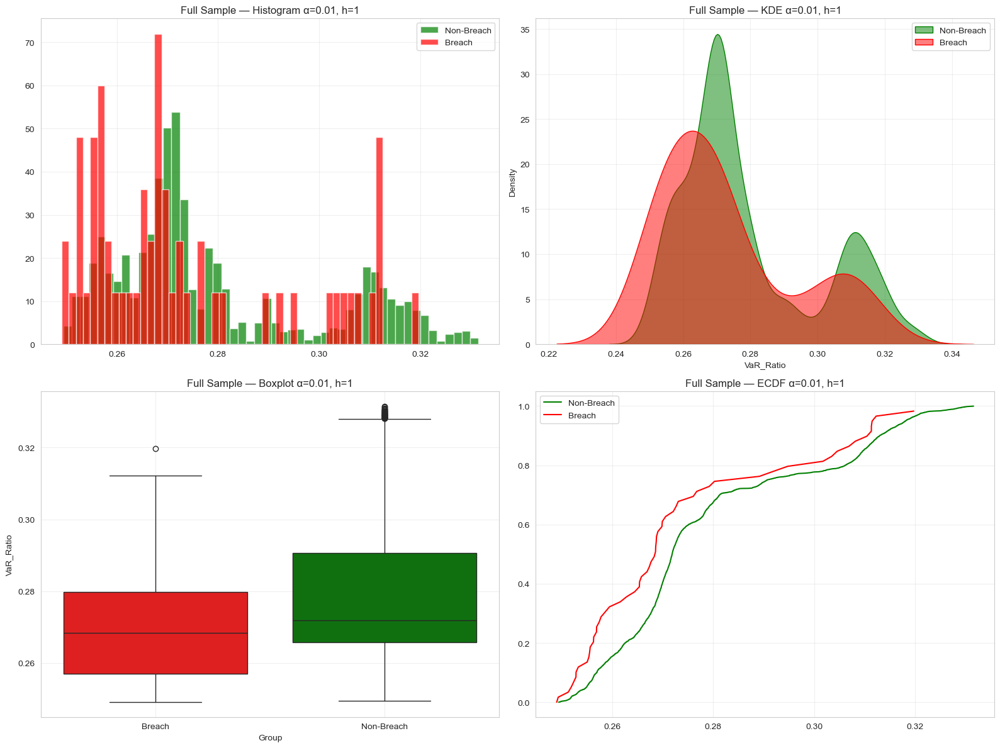

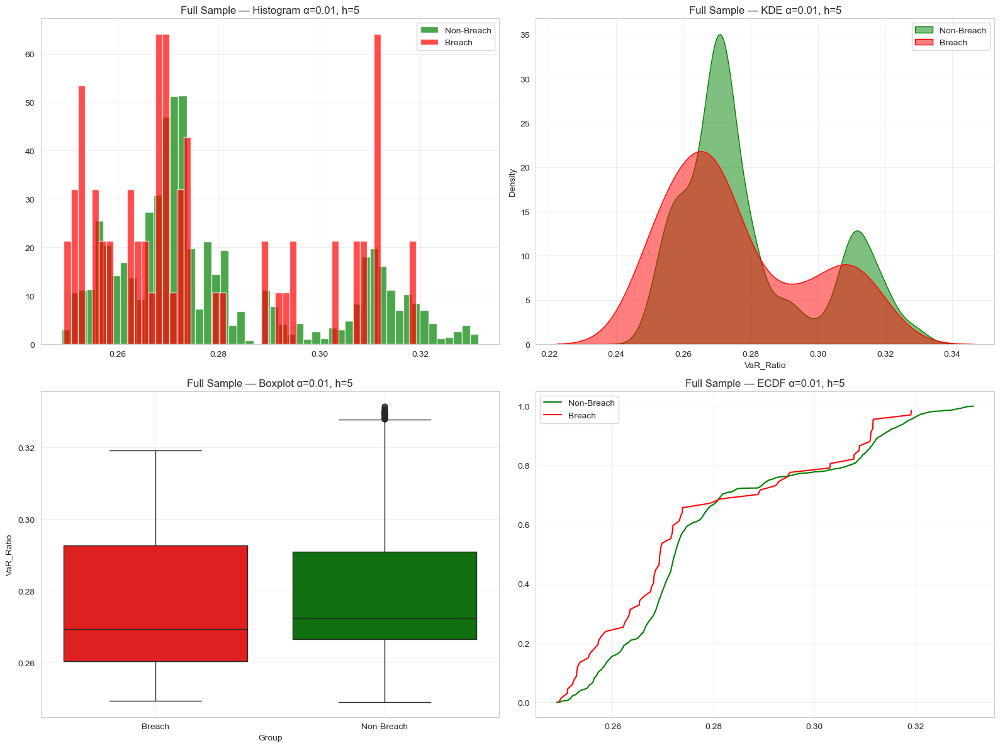

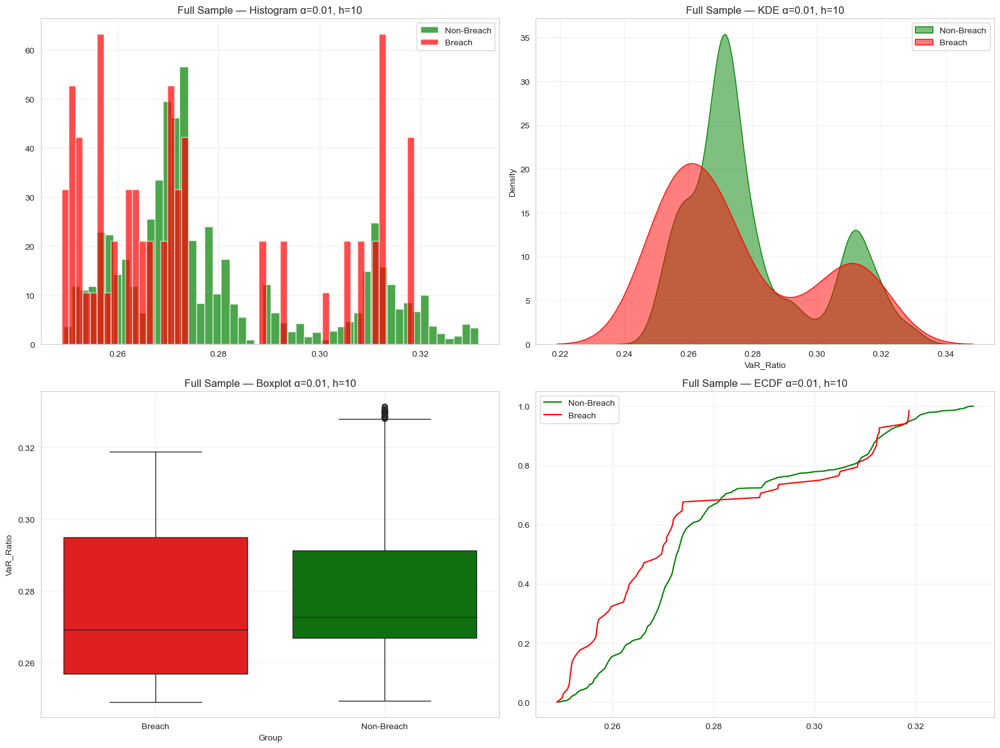

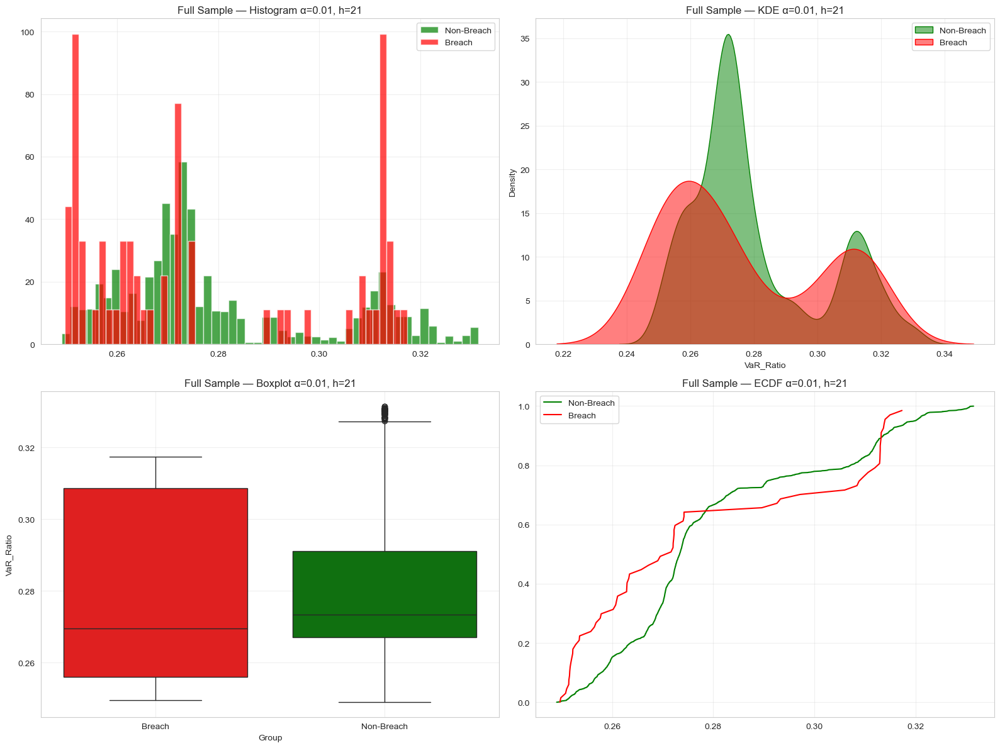

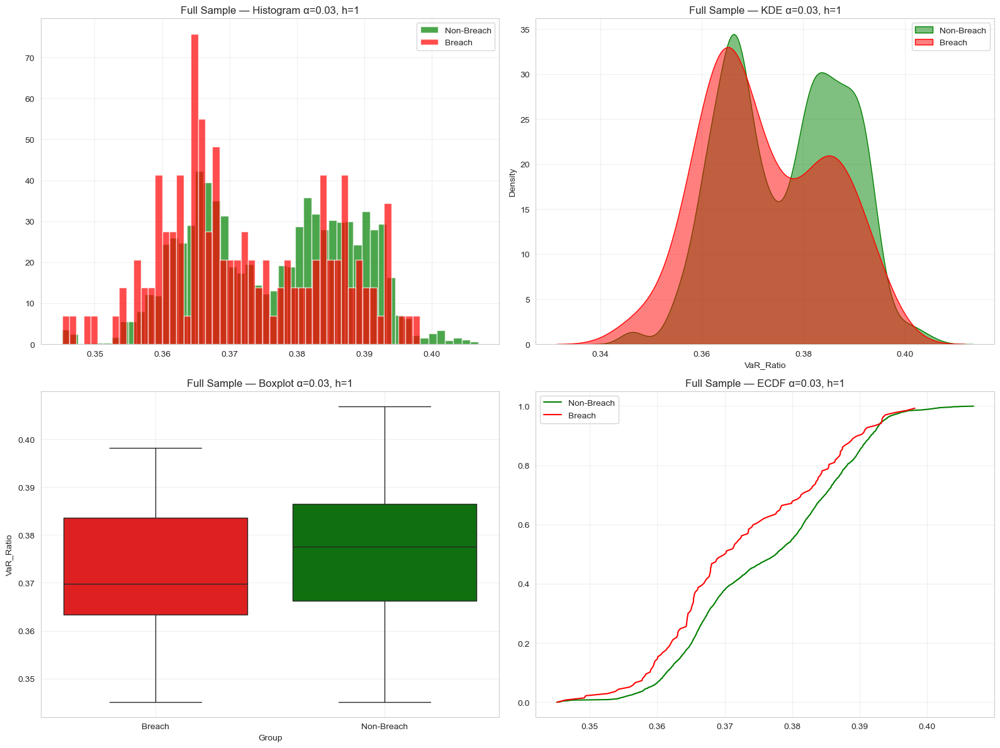

...

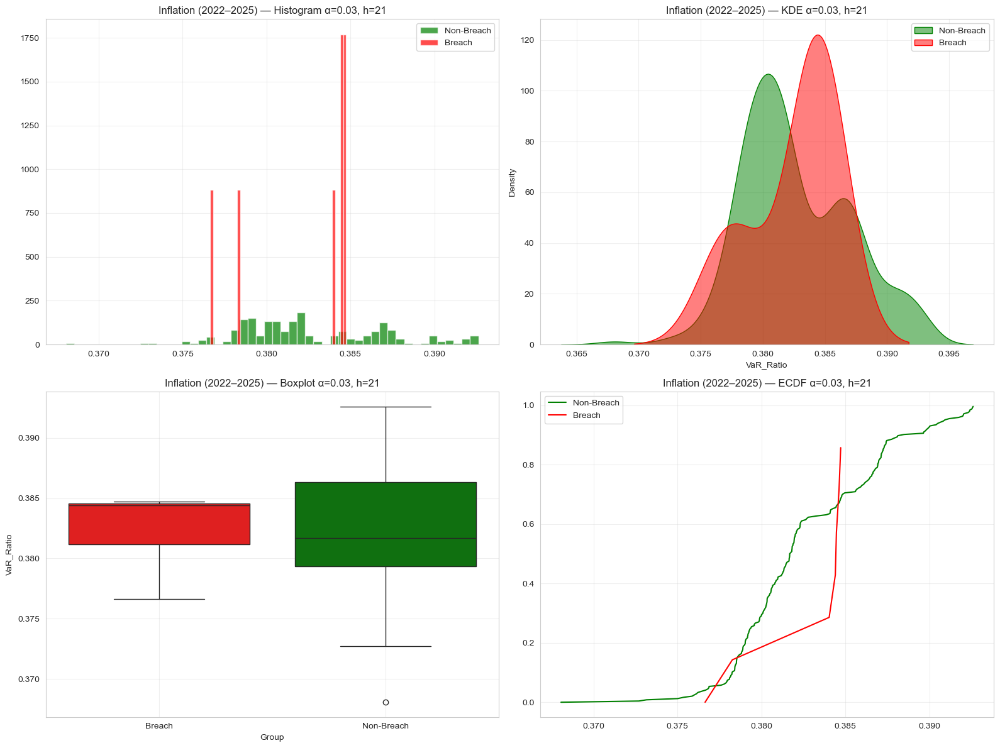

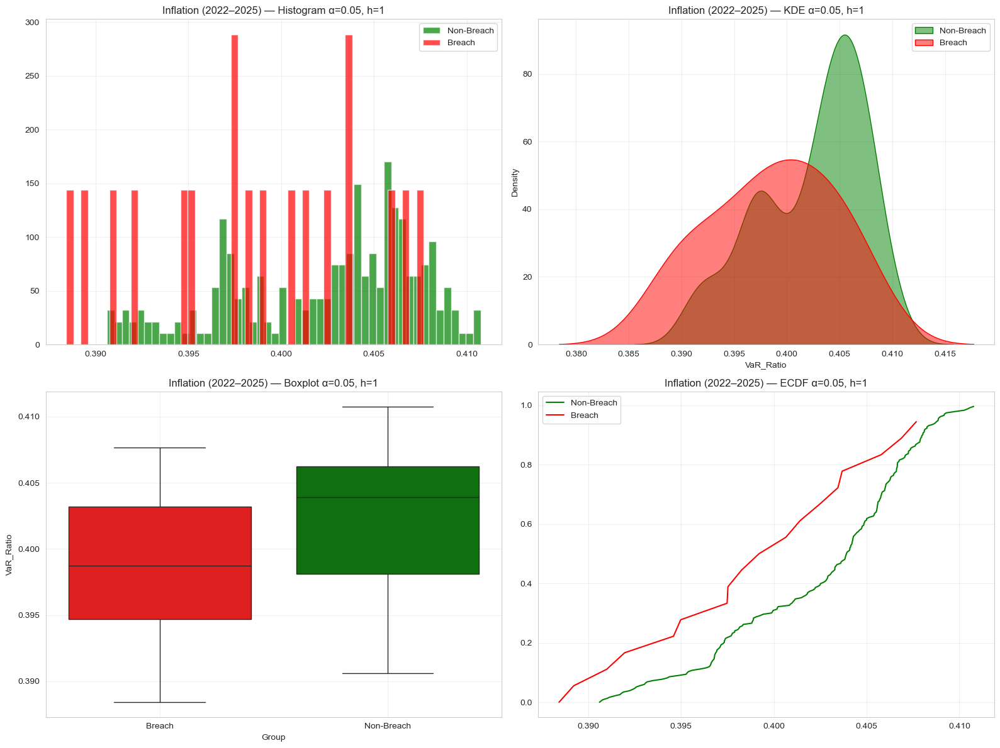

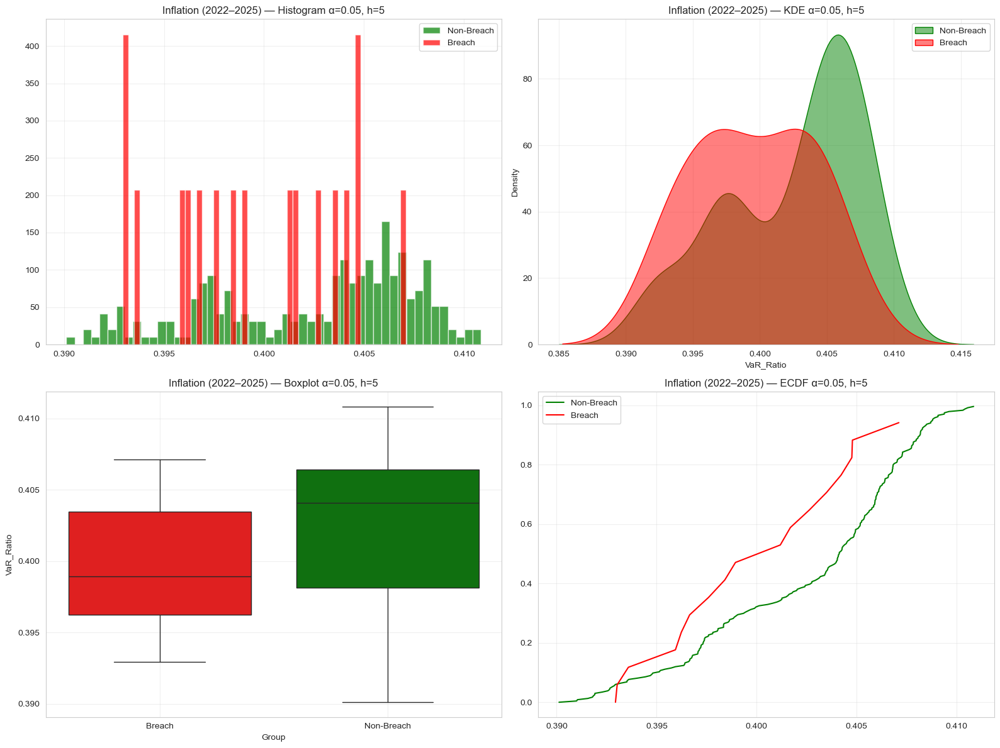

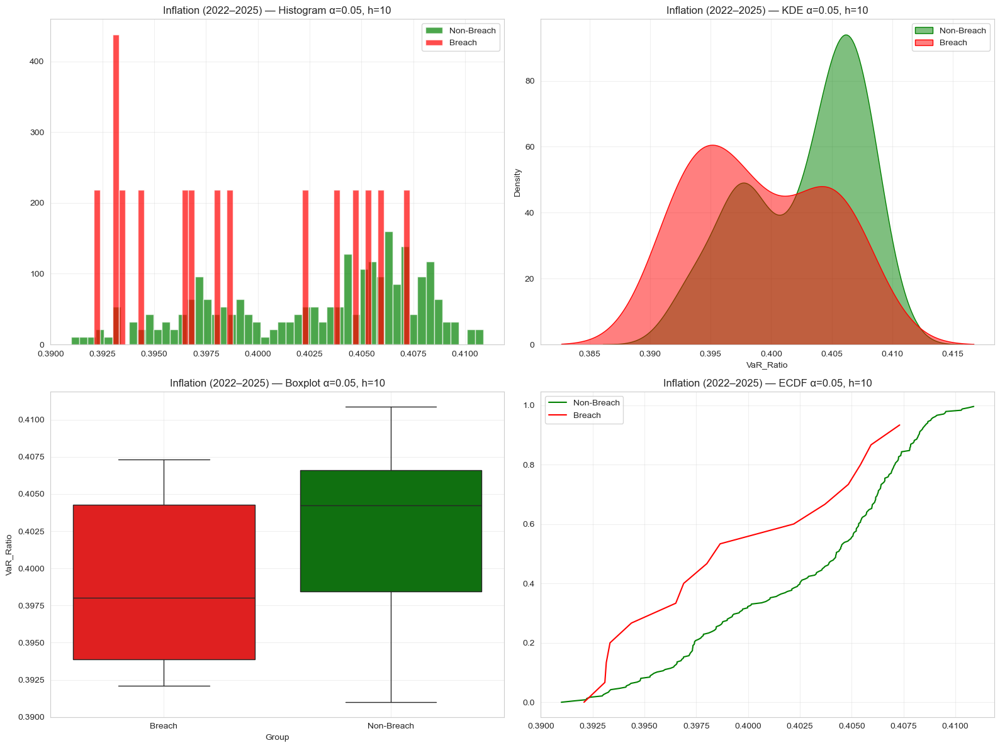

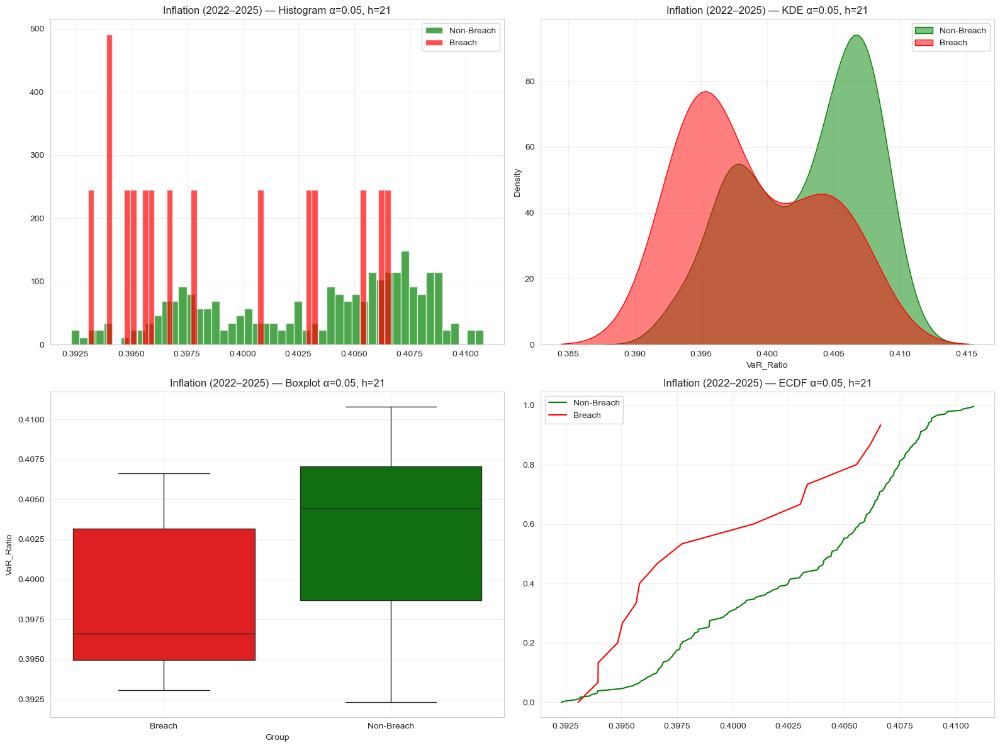

In [28]:
def analyze_ratio_distributions(df, alpha_level, forecast_horizon):
    
    df_filtered = df[
        (df["Alpha"] == alpha_level) &
        (df["ForecastHorizon"] == forecast_horizon)
    ].copy()

    if df_filtered.empty:
        return None

    
    df_filtered["Breach"] = df_filtered["ActualReturn"] <= df_filtered["FHS_VaR"]

    breach_days     = df_filtered[df_filtered["Breach"]]
    non_breach_days = df_filtered[~df_filtered["Breach"]]

    b  = breach_days["VaR_Ratio"].dropna()
    nb = non_breach_days["VaR_Ratio"].dropna()
    ks_stat, ks_p = ks_2samp(b, nb) if (len(b) > 0 and len(nb) > 0) else (np.nan, np.nan)
    t_stat, t_p = ttest_ind(b, nb, equal_var=False) if (len(b) > 1 and len(nb) > 1) else (np.nan, np.nan)

    if len(b) > 1 and len(nb) > 1:
        pooled_std = np.sqrt((b.std()**2 + nb.std()**2) / 2)
        effect_size = (b.mean() - nb.mean()) / pooled_std if pooled_std > 0 else np.nan
    else:
        effect_size = np.nan

    
    summary = {
        "alpha": alpha_level,
        "forecast_horizon": forecast_horizon,
        "n_breaches": len(breach_days),
        "n_non_breaches": len(non_breach_days),

        "ratio_mean_breach": b.mean(),
        "ratio_min_breach": b.min(),
        "ratio_max_breach": b.max(),
        "ratio_std_breach": b.std(),

        "ratio_mean_nonbreach": nb.mean(),
        "ratio_min_nonbreach": nb.min(),
        "ratio_max_nonbreach": nb.max(),
        "ratio_std_nonbreach": nb.std()
    }

    return {
        "breach_days": breach_days,
        "non_breach_days": non_breach_days,
        "summary": summary,
        "ks_test": (ks_stat, ks_p),
        "t_test": (t_stat, t_p),
        "effect_size": effect_size
    }


def plot_distribution_comparison(analysis_results, alpha_level, forecast_horizon, dataset_name):
    breach_days = analysis_results["breach_days"]
    non_breach_days = analysis_results["non_breach_days"]

    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    ax1, ax2, ax3, ax4 = axes.flat

    # Histogram
    ax1.hist(non_breach_days["VaR_Ratio"], bins=50, alpha=0.7, color="green", density=True, label="Non-Breach")
    ax1.hist(breach_days["VaR_Ratio"], bins=50, alpha=0.7, color="red", density=True, label="Breach")
    ax1.set_title(f"{dataset_name} — Histogram α={alpha_level}, h={forecast_horizon}")
    ax1.grid(alpha=0.3); ax1.legend()

    # KDE
    sns.kdeplot(non_breach_days["VaR_Ratio"], ax=ax2, color="green", label="Non-Breach", fill=True, alpha=0.5)
    sns.kdeplot(breach_days["VaR_Ratio"], ax=ax2, color="red", label="Breach", fill=True, alpha=0.5)
    ax2.set_title(f"{dataset_name} — KDE α={alpha_level}, h={forecast_horizon}")
    ax2.grid(alpha=0.3); ax2.legend()

    # Boxplot
    df_box = pd.DataFrame({
        "VaR_Ratio": pd.concat([breach_days["VaR_Ratio"], non_breach_days["VaR_Ratio"]]),
        "Group": ["Breach"] * len(breach_days) + ["Non-Breach"] * len(non_breach_days)
    })
    sns.boxplot(data=df_box, x="Group", y="VaR_Ratio", ax=ax3, palette=["red", "green"])
    ax3.set_title(f"{dataset_name} — Boxplot α={alpha_level}, h={forecast_horizon}")
    ax3.grid(alpha=0.3)

    # ECDF
    b_sorted = np.sort(breach_days["VaR_Ratio"])
    nb_sorted = np.sort(non_breach_days["VaR_Ratio"])
    ax4.plot(nb_sorted, np.arange(len(nb_sorted))/len(nb_sorted), color="green", label="Non-Breach")
    ax4.plot(b_sorted, np.arange(len(b_sorted))/len(b_sorted), color="red", label="Breach")
    ax4.set_title(f"{dataset_name} — ECDF α={alpha_level}, h={forecast_horizon}")
    ax4.grid(alpha=0.3); ax4.legend()

    plt.tight_layout()
    plt.show()
    return fig

def predictive_power_analysis(analysis_results):
    """
    Produces predictive metrics table including:
    - breach count
    - breach %
    - ratio mean/min/max/std
    - KS test
    - t-test
    - effect size
    """

    breach_days = analysis_results["breach_days"]
    non_breach_days = analysis_results["non_breach_days"]

    total_obs = len(breach_days) + len(non_breach_days)
    breach_count = len(breach_days)
    breach_pct = breach_count / total_obs if total_obs > 0 else np.nan

    b  = breach_days["VaR_Ratio"].dropna()
    nb = non_breach_days["VaR_Ratio"].dropna()

    ks_stat, ks_p = analysis_results["ks_test"]
    t_stat, t_p = analysis_results["t_test"]
    eff = analysis_results["effect_size"]

    return pd.DataFrame({
        "Total_Obs": [total_obs],
        "Breach_Count": [breach_count],
        "Breach_Percent": [breach_pct],

        "Ratio_Mean_Breach": [b.mean()],
        "Ratio_Min_Breach": [b.min()],
        "Ratio_Max_Breach": [b.max()],
        "Ratio_Std_Breach": [b.std()],

        "Ratio_Mean_NonBreach": [nb.mean()],
        "Ratio_Min_NonBreach": [nb.min()],
        "Ratio_Max_NonBreach": [nb.max()],
        "Ratio_Std_NonBreach": [nb.std()],

        "KS_pvalue": [ks_p],
        "T_pvalue": [t_p],
        "Effect_Size_d": [eff]
    })


def comprehensive_distribution_analysis(df, dataset_name, alpha_levels=[0.01, 0.03, 0.05], forecast_horizons=None):
    if forecast_horizons is None:
        forecast_horizons = sorted(df["ForecastHorizon"].unique())

    all_results = {}

    for alpha in alpha_levels:
        for h in forecast_horizons:

            res = analyze_ratio_distributions(df, alpha, h)
            if res is None:
                continue

            plot_distribution_comparison(res, alpha, h, dataset_name)

            pred = predictive_power_analysis(res)

            all_results[(alpha, h)] = {
                "distribution_analysis": res,
                "predictive_power": pred
            }

    return all_results


def collect_predictive_power(all_analysis_dict, dataset_name):
    rows = []
    for (alpha, h), result in all_analysis_dict.items():
        df_pred = result["predictive_power"].copy()
        df_pred["Alpha"] = alpha
        df_pred["ForecastHorizon"] = h
        df_pred["Dataset"] = dataset_name
        rows.append(df_pred)
    return pd.concat(rows, ignore_index=True)


def stats_table(all_analysis_dict, dataset_name):
    rows = []

    for (alpha, h), result in all_analysis_dict.items():

        stats_res = result["distribution_analysis"]
        ks_stat, ks_p = stats_res["ks_test"]
        t_stat, t_p = stats_res["t_test"]
        eff = stats_res["effect_size"]

        breach_days = stats_res["breach_days"]
        non_breach_days = stats_res["non_breach_days"]

        total_obs = len(breach_days) + len(non_breach_days)
        breach_pct = len(breach_days) / total_obs if total_obs > 0 else 0

        rows.append({
            "Dataset": dataset_name,
            "Alpha": alpha,
            "ForecastHorizon": h,
            "Total_Obs": total_obs,
            "Breach_Count": len(breach_days),
            "Breach_Percent": breach_pct,
            "KS_pvalue": ks_p,
            "T_pvalue": t_p,
            "Effect_Size_d": eff
        })

    return pd.DataFrame(rows)


distribution_analysis_full   = comprehensive_distribution_analysis(df_full,   "Full Sample")
distribution_analysis_crisis = comprehensive_distribution_analysis(df_crisis, "FY08–09 Crisis")
distribution_analysis_covid  = comprehensive_distribution_analysis(df_covid,  "COVID (2020)")
distribution_analysis_infl   = comprehensive_distribution_analysis(df_infl,   "Inflation (2022–2025)")

predictive_master = pd.concat([
    collect_predictive_power(distribution_analysis_full,   "Full Sample"),
    collect_predictive_power(distribution_analysis_crisis, "Crisis"),
    collect_predictive_power(distribution_analysis_covid,  "COVID"),
    collect_predictive_power(distribution_analysis_infl,   "Inflation")
], ignore_index=True)

stats_master = pd.concat([
    stats_table(distribution_analysis_full,   "Full Sample"),
    stats_table(distribution_analysis_crisis, "Crisis"),
    stats_table(distribution_analysis_covid,  "COVID"),
    stats_table(distribution_analysis_infl,   "Inflation")
], ignore_index=True)


first_cols = ["Dataset", "ForecastHorizon", "Alpha"]
other_cols = [c for c in predictive_master.columns if c not in first_cols]
predictive_master = predictive_master[first_cols + other_cols]


In [29]:
ratio_all=predictive_master[predictive_master['Dataset']=='Full Sample']
ratio_all

,Dataset,ForecastHorizon,Alpha,Total_Obs,Breach_Count,Breach_Percent,Ratio_Mean_Breach,Ratio_Min_Breach,Ratio_Max_Breach,Ratio_Std_Breach,Ratio_Mean_NonBreach,Ratio_Min_NonBreach,Ratio_Max_NonBreach,Ratio_Std_NonBreach,KS_pvalue,T_pvalue,Effect_Size_d
0,Full Sample,1,0.01,4530,59,0.013024,0.273095,0.249042,0.319714,0.020101,0.279285,0.249431,0.331543,0.020505,0.002127,0.022134,-0.304882
1,Full Sample,5,0.01,4534,67,0.014777,0.276015,0.249352,0.319190,0.020926,0.279645,0.248922,0.331505,0.020556,0.025301,0.163215,-0.174992
2,Full Sample,10,0.01,4539,68,0.014981,0.275684,0.248953,0.318726,0.023213,0.279937,0.249307,0.331490,0.020562,0.000241,0.137778,-0.193921
3,Full Sample,21,0.01,4550,67,0.014725,0.277232,0.249639,0.317342,0.024545,0.280206,0.249006,0.331500,0.020614,0.000411,0.327384,-0.131213
4,Full Sample,1,0.03,4530,137,0.030243,0.372445,0.345153,0.398187,0.012248,0.376445,0.345094,0.406882,0.011855,0.002775,0.000239,-0.331931
5,Full Sample,5,0.03,4534,137,0.030216,0.372823,0.345210,0.397056,0.012322,0.377060,0.345038,0.406522,0.011711,0.000104,0.000114,-0.352449
6,Full Sample,10,0.03,4539,150,0.033047,0.373363,0.345420,0.399655,0.012369,0.377512,0.345017,0.406233,0.011690,0.000003,0.000081,-0.344712
7,Full Sample,21,0.03,4550,140,0.030769,0.372752,0.345022,0.396175,0.012712,0.378013,0.344728,0.405639,0.011732,0.000010,0.000003,-0.430073
8,Full Sample,1,0.05,4530,230,0.050773,0.399508,0.368543,0.439251,0.014606,0.402578,0.363742,0.438311,0.014513,0.001779,0.002108,-0.210849
9,Full Sample,5,0.05,4534,215,0.047419,0.399877,0.371160,0.437142,0.013545,0.403365,0.369991,0.438969,0.014123,0.002208,0.000292,-0.252042


In [30]:
datasets = ["Crisis", "COVID", "Inflation"]   
ratio_sel = (
    predictive_master
    .loc[predictive_master["Dataset"].isin(datasets),
         ["Dataset",
          "ForecastHorizon",
          "Alpha",
          "Breach_Percent",
          "Ratio_Mean_Breach",
          "Ratio_Mean_NonBreach",
          "KS_pvalue",
          "T_pvalue",
          "Effect_Size_d"]]
    .reset_index(drop=True)
)

ratio_sel

,Dataset,ForecastHorizon,Alpha,Breach_Percent,Ratio_Mean_Breach,Ratio_Mean_NonBreach,KS_pvalue,T_pvalue,Effect_Size_d
0,Crisis,1,0.01,0.019802,0.254075,0.256132,0.094908,7.444689e-02,-0.653967
1,Crisis,5,0.01,0.023762,0.254234,0.256075,0.103043,1.024146e-01,-0.551480
2,Crisis,10,0.01,0.029703,0.253750,0.256033,0.005785,2.487205e-02,-0.687870
3,Crisis,21,0.01,0.029703,0.252822,0.255905,0.000700,9.336464e-05,-1.110541
4,Crisis,1,0.03,0.043564,0.363580,0.364018,0.598041,5.907852e-01,-0.119026
5,Crisis,5,0.03,0.051485,0.363310,0.363951,0.273415,4.648940e-01,-0.159641
6,Crisis,10,0.03,0.057426,0.363340,0.363807,0.559812,5.542729e-01,-0.118295
7,Crisis,21,0.03,0.057426,0.361157,0.363566,0.005132,5.912441e-04,-0.656241
8,Crisis,1,0.05,0.073267,0.395917,0.400062,0.046844,2.572663e-02,-0.392758
9,Crisis,5,0.05,0.081188,0.395366,0.399832,0.026618,1.401467e-02,-0.415294


## 3.7. Sensitivity to Threshold Selection

In [47]:
def quantile_ratio_analysis(
    df,
    dataset_name,
    alpha_levels=[0.01, 0.03, 0.05],
    forecast_horizons=None,
    quantile_list=[3, 4, 5]
):

    if forecast_horizons is None:
        forecast_horizons = sorted(df["ForecastHorizon"].unique())

    rows = []

    for n_quantiles in quantile_list:

        labels = [f"Q{i+1}" for i in range(n_quantiles)]

        for alpha in alpha_levels:
            for h in forecast_horizons:

                sub = df[
                    (df["Alpha"] == alpha) &
                    (df["ForecastHorizon"] == h)
                ].copy()

                if sub.empty:
                    continue

                sub["Breach"] = sub["ActualReturn"] <= sub["FHS_VaR"]

                sub = sub.dropna(subset=["VaR_Ratio"])

                if sub.empty:
                    continue

                try:
                    sub["Ratio_Quantile"] = pd.qcut(
                        sub["VaR_Ratio"],
                        q=n_quantiles,
                        labels=labels,
                        duplicates="drop"
                    )
                except ValueError:
                    continue

                grp = sub.groupby("Ratio_Quantile", observed=False)

                obs = grp.size().rename("Obs")
                breach_count = grp["Breach"].sum().rename("Breach_Count")
                breach_pct = grp["Breach"].mean().rename("Breach_Percent")

                mean_ratio = grp["VaR_Ratio"].mean().rename("Mean_Ratio")

                mean_ratio_breach = (
                    sub[sub["Breach"]]
                    .groupby("Ratio_Quantile", observed=False)["VaR_Ratio"]
                    .mean()
                    .rename("Mean_Ratio_Breach")
                )

                mean_ratio_nonbreach = (
                    sub[~sub["Breach"]]
                    .groupby("Ratio_Quantile", observed=False)["VaR_Ratio"]
                    .mean()
                    .rename("Mean_Ratio_NonBreach")
                )

                qtable = pd.concat(
                    [
                        obs,
                        breach_count,
                        breach_pct,
                        mean_ratio,
                        mean_ratio_breach,
                        mean_ratio_nonbreach
                    ],
                    axis=1
                ).reset_index()

                qtable["Dataset"] = dataset_name
                qtable["Alpha"] = alpha
                qtable["ForecastHorizon"] = h
                qtable["N_Quantiles"] = n_quantiles

                qtable = qtable[
                    [
                        "Dataset",
                        "Alpha",
                        "ForecastHorizon",
                        "N_Quantiles",
                        "Ratio_Quantile",
                        "Obs",
                        "Breach_Count",
                        "Breach_Percent",
                        "Mean_Ratio",
                        "Mean_Ratio_Breach",
                        "Mean_Ratio_NonBreach"
                    ]
                ]

                rows.append(qtable)

    return pd.concat(rows, ignore_index=True) if rows else pd.DataFrame()

alphas = [0.01, 0.03, 0.05]
horizons = [1, 5, 10, 21]

sens_full = quantile_ratio_analysis(
    df_full,
    "Full Sample",
    alpha_levels=alphas,
    forecast_horizons=horizons,
    quantile_list=[3, 4, 5]
)

sens_crisis = quantile_ratio_analysis(
    df_crisis,
    "FY08–09 Crisis",
    alpha_levels=alphas,
    forecast_horizons=horizons,
    quantile_list=[3, 4, 5]
)

sens_covid = quantile_ratio_analysis(
    df_covid,
    "COVID (2020)",
    alpha_levels=alphas,
    forecast_horizons=horizons,
    quantile_list=[3, 4, 5]
)

sens_infl = quantile_ratio_analysis(
    df_infl,
    "Inflation (2022–2025)",
    alpha_levels=alphas,
    forecast_horizons=horizons,
    quantile_list=[3, 4, 5]
)

quantile_sensitivity_master = pd.concat(
    [sens_full, sens_crisis, sens_covid, sens_infl],
    ignore_index=True
)

quantile_sensitivity_master.round(6)

,Dataset,Alpha,ForecastHorizon,N_Quantiles,Ratio_Quantile,Obs,Breach_Count,Breach_Percent,Mean_Ratio,Mean_Ratio_Breach,Mean_Ratio_NonBreach
0,Full Sample,0.01,1,3,Q1,1510,30,0.019868,0.260589,0.258359,0.260634
1,Full Sample,0.01,1,3,Q2,1510,14,0.009272,0.272581,0.271732,0.272589
2,Full Sample,0.01,1,3,Q3,1510,15,0.009934,0.304443,0.303838,0.304449
3,Full Sample,0.01,5,3,Q1,1512,31,0.020503,0.260945,0.259204,0.260982
4,Full Sample,0.01,5,3,Q2,1511,15,0.009927,0.272947,0.271818,0.272958
...,...,...,...,...,...,...,...,...,...,...,...
571,Inflation (2022–2025),0.05,21,5,Q1,51,8,0.156863,0.395625,0.394864,0.395766
572,Inflation (2022–2025),0.05,21,5,Q2,50,2,0.040000,0.399457,0.399321,0.399463
573,Inflation (2022–2025),0.05,21,5,Q3,50,2,0.040000,0.404031,0.403185,0.404066
574,Inflation (2022–2025),0.05,21,5,Q4,50,3,0.060000,0.406471,0.406114,0.406494


In [51]:
sensitivity_summary = quantile_sensitivity_master[
    [
        "Dataset",
        "Alpha",
        "ForecastHorizon",
        "N_Quantiles",
        "Ratio_Quantile",
        "Obs",
        "Breach_Count",
        "Breach_Percent"
    ]
].copy()

sensitivity_summary["Breach_Percent"] = (
    100 * sensitivity_summary["Breach_Percent"]
)

sensitivity_summary.round(2)

,Dataset,Alpha,ForecastHorizon,N_Quantiles,Ratio_Quantile,Obs,Breach_Count,Breach_Percent
0,Full Sample,0.01,1,3,Q1,1510,30,1.99
1,Full Sample,0.01,1,3,Q2,1510,14,0.93
2,Full Sample,0.01,1,3,Q3,1510,15,0.99
3,Full Sample,0.01,5,3,Q1,1512,31,2.05
4,Full Sample,0.01,5,3,Q2,1511,15,0.99
...,...,...,...,...,...,...,...,...
571,Inflation (2022–2025),0.05,21,5,Q1,51,8,15.69
572,Inflation (2022–2025),0.05,21,5,Q2,50,2,4.00
573,Inflation (2022–2025),0.05,21,5,Q3,50,2,4.00
574,Inflation (2022–2025),0.05,21,5,Q4,50,3,6.00


In [77]:
df = sensitivity_summary[
    sensitivity_summary["Dataset"] == "FY08–09 Crisis"
].copy()


summary = (
    df.pivot_table(
        index=["Alpha", "ForecastHorizon", "N_Quantiles"],
        columns="Ratio_Quantile",
        values="Breach_Percent"
    )
    .reset_index()
)

summary.columns.name = None



def monotonic(row):
    qcols = [c for c in ["Q1", "Q2", "Q3", "Q4", "Q5"] if c in row.index and pd.notna(row[c])]
    vals = row[qcols].values.astype(float)

    return "Monotonic" if np.all(np.diff(vals) <= 0) else "Non-monotonic"


summary["Remarks"] = summary.apply(monotonic, axis=1)

sample_size = (
    df.groupby(["Alpha", "ForecastHorizon", "N_Quantiles"])["Obs"]
      .sum()
      .reset_index(name="N_Sample")
)

summary = summary.merge(
    sample_size,
    on=["Alpha","ForecastHorizon","N_Quantiles"]
)

cols = [
    "Alpha",
    "ForecastHorizon",
    "N_Quantiles",
    "Q1",
    "Q2",
    "Q3",
    "Q4",
    "Q5",
    "Remarks"
]

summary = summary[cols].round(2)
summary = summary.sort_values(
    by=["N_Quantiles", "Alpha", "ForecastHorizon"],
    ascending=[True, True, True]
).reset_index(drop=True)

summary.to_excel("VER_Sensitivity_GFC.xlsx", index=False)

summary

,Alpha,ForecastHorizon,N_Quantiles,Q1,Q2,Q3,Q4,Q5,Remarks
0,0.01,1,3,3.55,1.19,1.19,NaN,NaN,Monotonic
1,0.01,5,3,4.14,1.79,1.19,NaN,NaN,Monotonic
2,0.01,10,3,5.92,2.38,0.60,NaN,NaN,Monotonic
3,0.01,21,3,7.10,1.19,0.60,NaN,NaN,Monotonic
4,0.03,1,3,4.73,5.36,2.98,NaN,NaN,Non-monotonic
5,0.03,5,3,7.10,5.36,2.98,NaN,NaN,Monotonic
6,0.03,10,3,6.51,6.55,4.17,NaN,NaN,Non-monotonic
7,0.03,21,3,9.47,5.36,2.38,NaN,NaN,Monotonic
8,0.05,1,3,10.65,7.74,3.57,NaN,NaN,Monotonic
9,0.05,5,3,12.43,7.14,4.76,NaN,NaN,Monotonic


# 3.8. Supplementary Test

### Characteristics of Each Regimes

In [34]:
start_date= "2000-01-01"
end_date= "2025-10-30"
sp = yf.download("^GSPC", start=start_date, end=end_date)['Close']
sp_ret = np.log(sp).diff().dropna()
realized_vol = sp_ret.rolling(21).std() * np.sqrt(252)
tickers = ["^VIX", "SPY", "TLT", "HYG"]
data = yf.download(tickers, start=start_date, end=end_date)["Close"].ffill()

factors = pd.DataFrame({
    "IV": data["^VIX"] / 100,
    "VoV": (data["^VIX"] / 100).rolling(21).std(),
    "Credit_Spread": (data["HYG"] / data["TLT"]) - 1,
    "Yield_Curve": data["TLT"] / data["SPY"],
    "Realized_Vol": data["SPY"].pct_change().rolling(21).std() * np.sqrt(252)
}).dropna()

alphas = [0.05, 0.03, 0.01]
window = 252*3 

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  4 of 4 completed


In [35]:
def prepare_with_factors(df, factors):
    df = df.copy()
    df["VaR_Estimation_Date"] = pd.to_datetime(df["VaR_Estimation_Date"])
    merged = df.merge(
        factors,
        left_on="VaR_Estimation_Date",
        right_index=True,
        how="inner"
    )
    return merged

def run_multifactor_logit(df, scope_name, factors, breach_col="Breach_FHS", decimals=4):
    dfm = prepare_with_factors(df, factors)
    rows = []

    for (alpha, h), sub in dfm.groupby(["Alpha", "ForecastHorizon"]):
        sub = sub.dropna(subset=[
            "VaR_Ratio", breach_col,
            "IV", "VoV", "Credit_Spread",
            "Yield_Curve", "Realized_Vol"
        ])
        if sub[breach_col].nunique() < 2:
            continue

        y = sub[breach_col]
        X = sub[["VaR_Ratio", "IV", "VoV", "Credit_Spread", "Yield_Curve", "Realized_Vol"]]
        X = sm.add_constant(X)

        maxlags = int(h) if h > 1 else 1

        try:
            m = sm.Logit(y, X).fit(
                cov_type="HAC",
                cov_kwds={"maxlags": maxlags},
                disp=False
            )
        except:
            continue

        tail_count = int(y.sum())
        obs = len(sub)
        params = m.params
        pvals = m.pvalues

        y_hat = m.predict(X)
        auc = roc_auc_score(y, y_hat)
        ar = 2 * auc - 1

        row = {
            "Scope": scope_name,
            "Alpha": alpha,
            "ForecastHorizon": h,
            "Obs": obs,
            "Tail_Count": tail_count,
            

            "Beta_const": params.get("const", np.nan),
            "p_const": pvals.get("const", np.nan),

            "Beta_Ratio": params.get("VaR_Ratio", np.nan),
            "p_Ratio": pvals.get("VaR_Ratio", np.nan),

            "Beta_IV": params.get("IV", np.nan),
            "p_IV": pvals.get("IV", np.nan),

            "Beta_VoV": params.get("VoV", np.nan),
            "p_VoV": pvals.get("VoV", np.nan),

            "Beta_Credit_Spread": params.get("Credit_Spread", np.nan),
            "p_Credit_Spread": pvals.get("Credit_Spread", np.nan),

            "Beta_Yield_Curve": params.get("Yield_Curve", np.nan),
            "p_Yield_Curve": pvals.get("Yield_Curve", np.nan),

            "Beta_Realized_Vol": params.get("Realized_Vol", np.nan),
            "p_Realized_Vol": pvals.get("Realized_Vol", np.nan),

            "AUC": auc,
            "AR": ar,
        }

        rows.append(row)

    res = pd.DataFrame(rows)

    # round p-values, AUC, AR to nice decimals
    p_cols = [c for c in res.columns if c.startswith("p_")]
    round_map = {c: decimals for c in p_cols + ["AUC", "AR"]}
    res = res.round(round_map)

    return res

# run for all scopes
res_full   = run_multifactor_logit(df_full,   "Full Sample", factors)
res_crisis = run_multifactor_logit(df_crisis, "Crisis",      factors)
res_covid  = run_multifactor_logit(df_covid,  "COVID",       factors)
res_infl   = run_multifactor_logit(df_infl,   "Inflation",   factors)

multi_factor_results = pd.concat(
    [res_full, res_crisis, res_covid, res_infl],
    ignore_index=True
)

multi_factor_results[multi_factor_results['Scope']=='Full Sample']

,Scope,Alpha,ForecastHorizon,Obs,Tail_Count,Beta_const,p_const,Beta_Ratio,p_Ratio,Beta_IV,...,Beta_VoV,p_VoV,Beta_Credit_Spread,p_Credit_Spread,Beta_Yield_Curve,p_Yield_Curve,Beta_Realized_Vol,p_Realized_Vol,AUC,AR
0,Full Sample,0.01,1,4530,59,6.903797,0.0427,-51.158485,0.0003,28.670024,...,-17.973598,0.1025,-6.997528,0.0149,-5.723814,0.0006,-19.325578,0.0,0.8296,0.6592
1,Full Sample,0.01,5,4534,67,5.606650,0.0938,-47.673553,0.0007,25.073941,...,5.589167,0.5531,-8.195277,0.0085,-5.437574,0.0024,-18.590371,0.0,0.8473,0.6946
2,Full Sample,0.01,10,4539,68,7.723266,0.0382,-55.380744,0.0003,23.093150,...,23.919538,0.0083,-8.451840,0.0076,-6.199322,0.0008,-17.284413,0.0,0.8823,0.7645
3,Full Sample,0.01,21,4550,67,6.262943,0.1495,-50.223251,0.0047,19.893439,...,29.832268,0.0003,-8.135798,0.0373,-6.326444,0.0068,-13.252914,0.0,0.8944,0.7889
4,Full Sample,0.03,1,4530,137,-2.197539,0.5179,-8.252856,0.3598,24.639917,...,-12.076266,0.1002,0.335198,0.7067,-1.040797,0.0410,-16.496898,0.0,0.8129,0.6258
5,Full Sample,0.03,5,4534,137,-2.594412,0.5329,-7.167721,0.5170,24.243725,...,2.638853,0.6996,1.147690,0.2110,-0.624088,0.2809,-17.404222,0.0,0.8248,0.6495
6,Full Sample,0.03,10,4539,150,-3.125916,0.4768,-6.080964,0.6014,22.568371,...,12.212325,0.1298,0.554050,0.5778,-0.939217,0.1189,-15.793261,0.0,0.8351,0.6701
7,Full Sample,0.03,21,4550,140,0.142944,0.9802,-15.058721,0.3264,17.781730,...,19.437306,0.0034,0.047288,0.9653,-1.173501,0.1129,-11.126374,0.0,0.8382,0.6765
8,Full Sample,0.05,1,4530,230,0.414870,0.8720,-12.172990,0.0563,21.442391,...,-16.227435,0.0061,0.816109,0.3300,-0.813722,0.1330,-12.239058,0.0,0.7690,0.5381
9,Full Sample,0.05,5,4534,215,0.863570,0.7640,-13.823192,0.0526,22.636387,...,-4.100226,0.5091,1.413723,0.1231,-0.456012,0.4794,-14.407055,0.0,0.7972,0.5944


In [43]:
multi_factor_results.to_excel('muti.xlsx')

In [36]:
pd.set_option("display.max_columns", None)
res_alpha3_h1 = multi_factor_results[
    (multi_factor_results["Alpha"] == 0.03) &
    (multi_factor_results["ForecastHorizon"] == 1)
]

res_alpha3_h1

,Scope,Alpha,ForecastHorizon,Obs,Tail_Count,Beta_const,p_const,Beta_Ratio,p_Ratio,Beta_IV,p_IV,Beta_VoV,p_VoV,Beta_Credit_Spread,p_Credit_Spread,Beta_Yield_Curve,p_Yield_Curve,Beta_Realized_Vol,p_Realized_Vol,AUC,AR
4,Full Sample,0.03,1,4530,137,-2.197539,0.5179,-8.252856,0.3598,24.639917,0.000,-12.076266,0.1002,0.335198,0.7067,-1.040797,0.0410,-16.496898,0.0000,0.8129,0.6258
16,Crisis,0.03,1,505,22,5.032785,0.8445,-46.439487,0.5155,27.701204,0.000,-51.307441,0.0377,-42.292759,0.0262,-19.262187,0.0022,-17.363337,0.0000,0.8286,0.6573
28,COVID,0.03,1,253,12,0.549303,0.9848,17.319169,0.8276,51.362514,0.000,-125.309629,0.0029,102.146815,0.0002,86.174396,0.0005,-23.230334,0.0303,0.9087,0.8174
36,Inflation,0.03,1,251,8,185.143786,0.0029,-518.081689,0.0026,66.988787,0.012,-34.167391,0.7077,-109.540982,0.1794,-196.468647,0.3061,1.494714,0.9236,0.8884,0.7767


### Sharpley Test

In [37]:
def prepare_with_factors(df, factors):
    df = df.copy()
    df["VaR_Estimation_Date"] = pd.to_datetime(df["VaR_Estimation_Date"])
    merged = df.merge(
        factors,
        left_on="VaR_Estimation_Date",
        right_index=True,
        how="inner"
    )
    return merged

def shap_for_scope(df, scope_name, factors, breach_col="Breach_FHS"):
    dfm = prepare_with_factors(df, factors)
    rows = []

    feature_cols = ["VaR_Ratio", "IV", "VoV", "Credit_Spread", "Yield_Curve", "Realized_Vol"]

    for (alpha, h), sub in dfm.groupby(["Alpha", "ForecastHorizon"]):
        sub = sub.dropna(subset=feature_cols + [breach_col])
        if sub[breach_col].nunique() < 2:
            continue

        y = sub[breach_col].values
        X = sub[feature_cols].values

        scaler = StandardScaler()
        Xs = scaler.fit_transform(X)

        try:
            clf = LogisticRegression(max_iter=1000, solver="lbfgs")
            clf.fit(Xs, y)
        except:
            continue

        explainer = shap.LinearExplainer(clf, Xs)
        shap_values = explainer.shap_values(Xs)  # shape: (n_samples, n_features)

        mean_abs_shap = np.abs(shap_values).mean(axis=0)

        for feat, val in zip(feature_cols, mean_abs_shap):
            rows.append({
                "Scope": scope_name,
                "Alpha": alpha,
                "ForecastHorizon": h,
                "Obs": len(sub),
                "Tail_Count": int(sub[breach_col].sum()),
                "Feature": feat,
                "MeanAbs_SHAP": val,
            })

    return pd.DataFrame(rows)
shap_full   = shap_for_scope(df_full,   "Full Sample", factors)
shap_crisis = shap_for_scope(df_crisis, "Crisis",      factors)
shap_covid  = shap_for_scope(df_covid,  "COVID",       factors)
shap_infl   = shap_for_scope(df_infl,   "Inflation",   factors)

shap_results = pd.concat([shap_full, shap_crisis, shap_covid, shap_infl], ignore_index=True)

# Optional: sort by importance within each (Scope, Alpha, Horizon)
shap_results_sorted = (
    shap_results
    .sort_values(["Scope", "Alpha", "ForecastHorizon", "MeanAbs_SHAP"], ascending=[True, True, True, False])
    .reset_index(drop=True)
)


filtered_df = shap_results_sorted[
    (shap_results_sorted['Alpha'] == 0.03) &
    (shap_results_sorted['ForecastHorizon'] == 1) &
    (shap_results_sorted['Feature'] == 'VaR_Ratio')
    
]


filtered_df.head(50)

,Scope,Alpha,ForecastHorizon,Obs,Tail_Count,Feature,MeanAbs_SHAP
29,COVID,0.03,1,253,12,VaR_Ratio,0.176873
101,Crisis,0.03,1,505,22,VaR_Ratio,0.115186
172,Full Sample,0.03,1,4530,137,VaR_Ratio,0.096694
234,Inflation,0.03,1,251,8,VaR_Ratio,1.268441


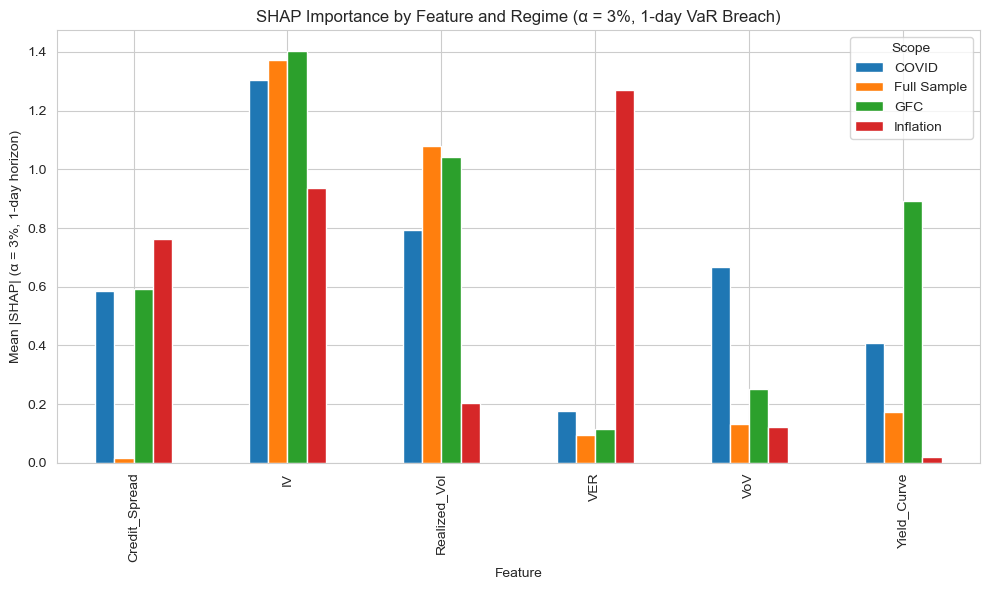

In [38]:
# Filter: alpha = 3%, horizon = 1 day
shap_alpha3_h1 = shap_results[
    (shap_results["Alpha"] == 0.03) &
    (shap_results["ForecastHorizon"] == 1)
].copy()
shap_alpha3_h1["Scope"] = shap_alpha3_h1["Scope"].replace({"Crisis": "GFC"})
shap_alpha3_h1["Feature"] = shap_alpha3_h1["Feature"].replace({"VaR_Ratio": "VER"})

agg = (
    shap_alpha3_h1
    .groupby(["Scope", "Feature"], as_index=False)["MeanAbs_SHAP"]
    .mean()
)


pivot = agg.pivot(index="Feature", columns="Scope", values="MeanAbs_SHAP")


pivot = pivot.sort_index()


ax = pivot.plot(
    kind="bar",
    figsize=(10, 6)
)

ax.set_xlabel("Feature")
ax.set_ylabel("Mean |SHAP| (α = 3%, 1-day horizon)")
ax.set_title("SHAP Importance by Feature and Regime (α = 3%, 1-day VaR Breach)")
ax.legend(title="Scope", loc="best")
plt.tight_layout()
plt.show()
